# Predicting Osteoporosis Risk Using Machine Learning

## Project Overview

This project aims to develop a robust machine learning
classification model to identify osteoporosis status based
on demographic, hormonal, nutritional, lifestyle, and
medical attributes.

## Business Objective

To identify factors associated with osteoporosis and
evaluate machine learning algorithms that could support
research-based identification of osteoporosis-positive
individuals.

## Technical Objective

Develop and compare binary classification models using
Osteoporosis as the target variable:

- 0: No Osteoporosis
- 1: Osteoporosis

The models will be evaluated using accuracy, precision,
recall, F1-score, and other relevant classification metrics,
with particular attention to the positive class.




In [1]:
# IMPORT REQUIRED LIBRARIES

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy import stats

# Display utilities
from IPython.display import display

# Pandas display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.4f}".format)

# Visualization settings
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["font.size"] = 11

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
# LOAD THE DATASET
df = pd.read_csv("osteoporosis.csv",keep_default_na=False,na_values=[""])

# Preserve an original copy
df_original = df.copy(deep=True)

# Define target variable
target = "Osteoporosis"

print("Dataset loaded successfully.")
print(f"Number of observations : {df.shape[0]}")
print(f"Number of columns      : {df.shape[1]}")

display(df.head())

Dataset loaded successfully.
Number of observations : 1958
Number of columns      : 16


,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
0,104866,69,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,Corticosteroids,Yes,1
1,101999,32,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,No,None,None,None,Yes,1
2,106567,89,Female,Postmenopausal,No,Caucasian,Normal,Adequate,Sufficient,Active,No,Moderate,Hyperthyroidism,Corticosteroids,No,1
3,102316,78,Female,Normal,No,Caucasian,Underweight,Adequate,Insufficient,Sedentary,Yes,None,Rheumatoid Arthritis,Corticosteroids,No,1
4,101944,38,Male,Postmenopausal,Yes,African American,Normal,Low,Sufficient,Active,Yes,None,Rheumatoid Arthritis,None,Yes,1


In [3]:
# INITIAL DATASET INSPECTION

print("Dataset Shape:")
print(df.shape)

print("\nDataset Dimensions:")
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Observations:")
display(df.head())

print("\nLast 5 Observations:")
display(df.tail())

print("\nRandom 5 Observations:")
display(df.sample(5, random_state=RANDOM_STATE))

Dataset Shape:
(1958, 16)

Dataset Dimensions:
Rows    : 1958
Columns : 16

Column Names:
['Id', 'Age', 'Gender', 'Hormonal Changes', 'Family History', 'Race/Ethnicity', 'Body Weight', 'Calcium Intake', 'Vitamin D Intake', 'Physical Activity', 'Smoking', 'Alcohol Consumption', 'Medical Conditions', 'Medications', 'Prior Fractures', 'Osteoporosis']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1958 entries, 0 to 1957
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Id                   1958 non-null   int64 
 1   Age                  1958 non-null   int64 
 2   Gender               1958 non-null   object
 3   Hormonal Changes     1958 non-null   object
 4   Family History       1958 non-null   object
 5   Race/Ethnicity       1958 non-null   object
 6   Body Weight          1958 non-null   object
 7   Calcium Intake       1958 non-null   object
 8   Vitamin D Intake     1958 

,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
0,104866,69,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,Corticosteroids,Yes,1
1,101999,32,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,No,None,None,None,Yes,1
2,106567,89,Female,Postmenopausal,No,Caucasian,Normal,Adequate,Sufficient,Active,No,Moderate,Hyperthyroidism,Corticosteroids,No,1
3,102316,78,Female,Normal,No,Caucasian,Underweight,Adequate,Insufficient,Sedentary,Yes,None,Rheumatoid Arthritis,Corticosteroids,No,1
4,101944,38,Male,Postmenopausal,Yes,African American,Normal,Low,Sufficient,Active,Yes,None,Rheumatoid Arthritis,None,Yes,1



Last 5 Observations:


,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
1953,106130,19,Female,Normal,Yes,African American,Normal,Adequate,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,None,Yes,0
1954,106463,23,Female,Postmenopausal,Yes,Caucasian,Underweight,Low,Insufficient,Active,No,None,None,Corticosteroids,No,0
1955,103142,34,Female,Postmenopausal,No,African American,Underweight,Low,Sufficient,Sedentary,No,None,Hyperthyroidism,None,No,0
1956,105187,25,Male,Postmenopausal,No,African American,Normal,Low,Insufficient,Sedentary,Yes,None,Rheumatoid Arthritis,Corticosteroids,Yes,0
1957,108561,26,Female,Postmenopausal,No,African American,Underweight,Adequate,Sufficient,Sedentary,Yes,None,Rheumatoid Arthritis,Corticosteroids,No,0



Random 5 Observations:


,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
1094,109583,20,Female,Postmenopausal,Yes,African American,Underweight,Adequate,Insufficient,Active,No,Moderate,Rheumatoid Arthritis,None,No,0
572,106603,73,Male,Postmenopausal,Yes,Asian,Normal,Adequate,Insufficient,Active,Yes,None,Hyperthyroidism,Corticosteroids,No,1
450,107658,30,Male,Normal,Yes,African American,Normal,Low,Sufficient,Sedentary,No,Moderate,Rheumatoid Arthritis,None,No,1
383,102810,65,Female,Postmenopausal,No,Caucasian,Normal,Adequate,Sufficient,Sedentary,No,Moderate,Rheumatoid Arthritis,None,No,1
1379,103142,21,Female,Postmenopausal,Yes,Caucasian,Underweight,Low,Sufficient,Active,Yes,None,Rheumatoid Arthritis,None,No,0


In [4]:
# COMPREHENSIVE DATASET SUMMARY

dataset_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Total Records": len(df),
    "Non-Null Count": df.notna().sum(),
    "Missing Count": df.isna().sum(),
    "Missing (%)": df.isna().mean() * 100,
    "Unique Values": df.nunique(),
    "Duplicate Values": [
        df[col].duplicated().sum()
        for col in df.columns
    ]
})

dataset_summary.index.name = "Feature"

display(dataset_summary)

,Data Type,Total Records,Non-Null Count,Missing Count,Missing (%),Unique Values,Duplicate Values
Feature,,,,,,,
Id,int64,1958,1958,0,0.0000,1749,209
Age,int64,1958,1958,0,0.0000,73,1885
Gender,object,1958,1958,0,0.0000,2,1956
Hormonal Changes,object,1958,1958,0,0.0000,2,1956
Family History,object,1958,1958,0,0.0000,2,1956
Race/Ethnicity,object,1958,1958,0,0.0000,3,1955
Body Weight,object,1958,1958,0,0.0000,2,1956
Calcium Intake,object,1958,1958,0,0.0000,2,1956
Vitamin D Intake,object,1958,1958,0,0.0000,2,1956


In [5]:
# FEATURE CLASSIFICATION

id_col = "Id"

numerical_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in [id_col, target]
]

categorical_cols = [
    col for col in df.select_dtypes(exclude=np.number).columns
    if col not in [id_col, target]
]

feature_cols = [
    col for col in df.columns
    if col not in [id_col, target]
]

print("Identifier Column:")
print(id_col)

print("\nNumerical Features:")
print(numerical_cols)

print("\nCategorical Features:")
for i, col in enumerate(categorical_cols, 1):
    print(f"{i}. {col}")

print("\nTarget Variable:")
print(target)

print("\nFeature Summary:")
print(f"Numerical Features   : {len(numerical_cols)}")
print(f"Categorical Features : {len(categorical_cols)}")
print(f"Total Input Features : {len(feature_cols)}")

Identifier Column:
Id

Numerical Features:
['Age']

Categorical Features:
1. Gender
2. Hormonal Changes
3. Family History
4. Race/Ethnicity
5. Body Weight
6. Calcium Intake
7. Vitamin D Intake
8. Physical Activity
9. Smoking
10. Alcohol Consumption
11. Medical Conditions
12. Medications
13. Prior Fractures

Target Variable:
Osteoporosis

Feature Summary:
Numerical Features   : 1
Categorical Features : 13
Total Input Features : 14


In [6]:
# NUMERICAL DESCRIPTIVE STATISTICS

numerical_summary = df[numerical_cols].describe().T

numerical_summary["median"] = df[numerical_cols].median()
numerical_summary["variance"] = df[numerical_cols].var()
numerical_summary["skewness"] = df[numerical_cols].skew()
numerical_summary["kurtosis"] = df[numerical_cols].kurtosis()
numerical_summary["range"] = (
    df[numerical_cols].max() - df[numerical_cols].min()
)

display(numerical_summary)

,count,mean,std,min,25%,50%,75%,max,median,variance,skewness,kurtosis,range
Feature,,,,,,,,,,,,,
Age,1958.0000,39.1011,21.3554,18.0000,21.0000,32.0000,53.0000,90.0000,32.0000,456.0542,0.9087,-0.4995,72


In [7]:
# CATEGORICAL DESCRIPTIVE STATISTICS

categorical_summary = df[categorical_cols].describe().T

categorical_summary["Mode (%)"] = (
    categorical_summary["freq"] / len(df) * 100
)

display(categorical_summary)

,count,unique,top,freq,Mode (%)
Feature,,,,,
Gender,1958,2,Male,992,50.6639
Hormonal Changes,1958,2,Normal,981,50.1021
Family History,1958,2,No,998,50.9704
Race/Ethnicity,1958,3,African American,681,34.7804
Body Weight,1958,2,Normal,1027,52.4515
Calcium Intake,1958,2,Low,1004,51.2768
Vitamin D Intake,1958,2,Sufficient,1011,51.6343
Physical Activity,1958,2,Active,1021,52.1450
Smoking,1958,2,Yes,982,50.1532


In [8]:
# CATEGORICAL VALUES AND FREQUENCY ANALYSIS

for col in categorical_cols:

    print("=" * 60)
    print(f"Feature: {col}")
    print(f"Unique Categories: {df[col].nunique()}")
    print("=" * 60)

    frequency_table = pd.DataFrame({
        "Count": df[col].value_counts(dropna=False),
        "Percentage (%)": (
            df[col].value_counts(
                normalize=True,
                dropna=False
            ) * 100
        )
    })

    display(frequency_table)

Feature: Gender
Unique Categories: 2


,Count,Percentage (%)
Gender,,
Male,992,50.6639
Female,966,49.3361


Feature: Hormonal Changes
Unique Categories: 2


,Count,Percentage (%)
Hormonal Changes,,
Normal,981,50.1021
Postmenopausal,977,49.8979


Feature: Family History
Unique Categories: 2


,Count,Percentage (%)
Family History,,
No,998,50.9704
Yes,960,49.0296


... (16 outputs left out)

Feature: Medications
Unique Categories: 2


,Count,Percentage (%)
Medications,,
None,985,50.3064
Corticosteroids,973,49.6936


Feature: Prior Fractures
Unique Categories: 2


,Count,Percentage (%)
Prior Fractures,,
Yes,983,50.2043
No,975,49.7957


### Comprehensive Data Quality Assessment

In [9]:
# MISSING VALUE ANALYSIS

missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage (%)": df.isna().mean() * 100
}).sort_values(
    by="Missing Count",
    ascending=False
)

display(missing_summary)

total_missing = df.isna().sum().sum()

print(f"Total Missing Values: {total_missing}")

if total_missing == 0:
    print("No missing values detected.")
else:
    print("Missing values require further investigation.")

,Missing Count,Missing Percentage (%)
Feature,,
Id,0,0.0000
Age,0,0.0000
Gender,0,0.0000
Hormonal Changes,0,0.0000
Family History,0,0.0000
Race/Ethnicity,0,0.0000
Body Weight,0,0.0000
Calcium Intake,0,0.0000
Vitamin D Intake,0,0.0000


Total Missing Values: 0
No missing values detected.


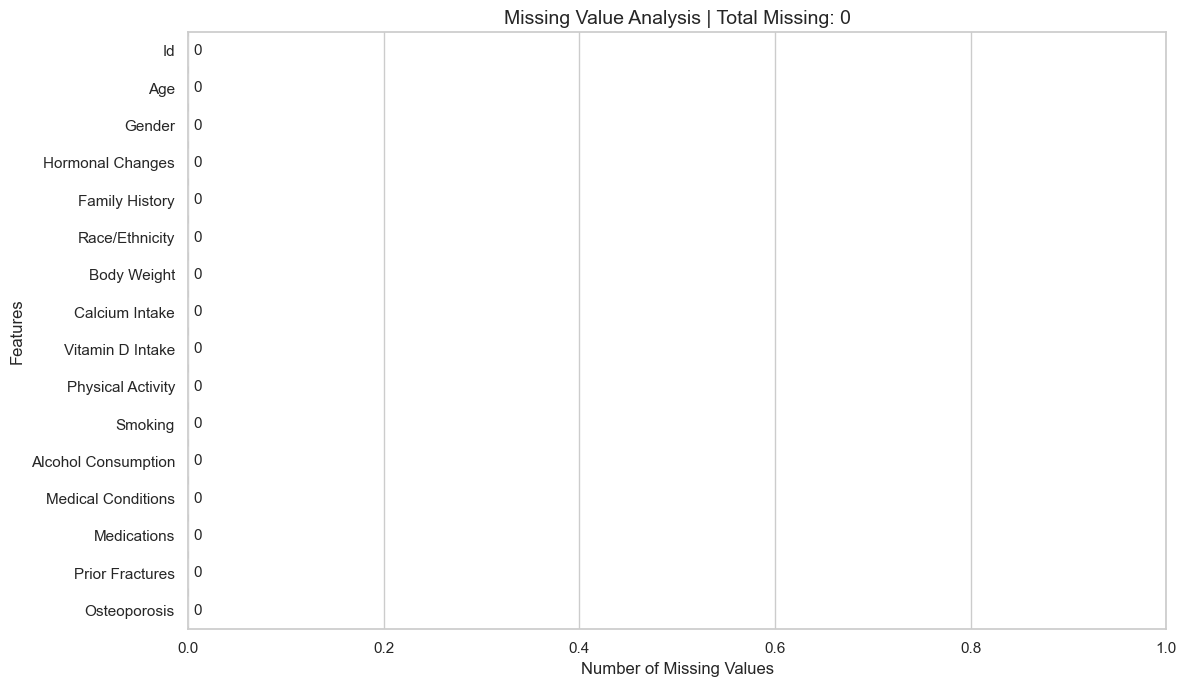

In [10]:
# MISSING VALUE VISUALIZATION

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=missing_summary.reset_index(),
    x="Missing Count",
    y="Feature",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container, padding=4, fmt="%.0f")

plt.xlim(
    0,
    max(1, missing_summary["Missing Count"].max() * 1.15)
)

plt.xlabel("Number of Missing Values")
plt.ylabel("Features")
plt.title(
    f"Missing Value Analysis | Total Missing: {total_missing}"
)

plt.tight_layout()
plt.show()

In [11]:
# VALIDATE NONE CATEGORIES

none_cols = [
    "Alcohol Consumption",
    "Medical Conditions",
    "Medications"
]

none_summary = pd.DataFrame({
    "Feature": none_cols,
    "None Count": [
        df[col].eq("None").sum()
        for col in none_cols
    ],
    "Actual Missing Count": [
        df[col].isna().sum()
        for col in none_cols
    ]
})

none_summary["None Percentage (%)"] = (
    none_summary["None Count"] / len(df) * 100
)

display(none_summary)

,Feature,None Count,Actual Missing Count,None Percentage (%)
0,Alcohol Consumption,988,0,50.4597
1,Medical Conditions,647,0,33.0439
2,Medications,985,0,50.3064


In [12]:
# BLANK AND WHITESPACE VALUE ANALYSIS

blank_summary = []

for col in categorical_cols:

    values = df[col].astype("string")

    blank_count = values.str.strip().eq("").sum()

    whitespace_count = (
        values.ne(values.str.strip())
    ).sum()

    blank_summary.append({
        "Feature": col,
        "Blank Values": blank_count,
        "Leading/Trailing Spaces": whitespace_count
    })

blank_summary = pd.DataFrame(blank_summary)

display(blank_summary)

,Feature,Blank Values,Leading/Trailing Spaces
0,Gender,0,0
1,Hormonal Changes,0,0
2,Family History,0,0
3,Race/Ethnicity,0,0
4,Body Weight,0,0
5,Calcium Intake,0,0
6,Vitamin D Intake,0,0
7,Physical Activity,0,0
8,Smoking,0,0
9,Alcohol Consumption,0,0


In [13]:
# COMPLETE DUPLICATE RECORD ANALYSIS

duplicate_count = df.duplicated().sum()

duplicate_percentage = (
    duplicate_count / len(df) * 100
)

print(f"Total Observations   : {len(df)}")
print(f"Duplicate Rows       : {duplicate_count}")
print(f"Duplicate Percentage : {duplicate_percentage:.2f}%")

if duplicate_count > 0:
    display(df[df.duplicated(keep=False)])
else:
    print("No complete duplicate records found.")

Total Observations   : 1958
Duplicate Rows       : 0
Duplicate Percentage : 0.00%
No complete duplicate records found.


In [14]:
# DUPLICATE PATIENT ID ANALYSIS

id_counts = df[id_col].value_counts()

repeated_ids = id_counts[id_counts > 1]

id_summary = pd.DataFrame({
    "Metric": [
        "Total Observations",
        "Unique IDs",
        "Additional ID Occurrences",
        "Distinct Repeated IDs",
        "Rows Associated with Repeated IDs"
    ],
    "Count": [
        len(df),
        df[id_col].nunique(),
        df[id_col].duplicated().sum(),
        len(repeated_ids),
        df[id_col].isin(repeated_ids.index).sum()
    ]
})

display(id_summary)

print("\nMost Frequently Repeated IDs:")

display(repeated_ids.head(10))

,Metric,Count
0,Total Observations,1958
1,Unique IDs,1749
2,Additional ID Occurrences,209
3,Distinct Repeated IDs,196
4,Rows Associated with Repeated IDs,405



Most Frequently Repeated IDs:


Id
106463    3
101608    3
101541    3
107264    3
107815    3
103172    3
107509    3
103872    3
103759    3
106370    3
Name: count, dtype: int64

In [15]:
# INSPECT REPEATED PATIENT ID RECORDS

duplicate_id_records = df[
    df.duplicated(subset=id_col, keep=False)
].sort_values(id_col)

display(duplicate_id_records.head(20))

Feature,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
77,101027,82,Female,Normal,No,Asian,Underweight,Low,Insufficient,Active,No,Moderate,None,Corticosteroids,No,1
1497,101027,29,Female,Postmenopausal,Yes,Caucasian,Normal,Low,Insufficient,Active,No,Moderate,None,Corticosteroids,No,0
1544,101148,25,Female,Postmenopausal,No,African American,Underweight,Low,Insufficient,Active,No,Moderate,Hyperthyroidism,None,No,0
736,101148,21,Male,Normal,Yes,Asian,Normal,Adequate,Insufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,Corticosteroids,No,1
720,101162,59,Female,Postmenopausal,Yes,African American,Underweight,Low,Sufficient,Active,Yes,Moderate,Hyperthyroidism,None,Yes,1
650,101162,25,Male,Normal,No,Caucasian,Underweight,Adequate,Sufficient,Active,Yes,None,Hyperthyroidism,Corticosteroids,Yes,1
647,101170,40,Male,Postmenopausal,No,Asian,Normal,Adequate,Sufficient,Active,No,None,Hyperthyroidism,Corticosteroids,No,1
1297,101170,35,Male,Normal,No,Caucasian,Normal,Adequate,Insufficient,Active,Yes,None,None,None,Yes,0
1385,101180,20,Male,Postmenopausal,Yes,Asian,Normal,Adequate,Sufficient,Sedentary,Yes,None,Rheumatoid Arthritis,None,Yes,0
1941,101180,20,Male,Postmenopausal,No,African American,Normal,Adequate,Sufficient,Active,Yes,Moderate,None,None,Yes,0


In [16]:
# DUPLICATE RECORDS EXCLUDING ID

analysis_cols = [
    col for col in df.columns
    if col != id_col
]

duplicate_without_id = df.duplicated(
    subset=analysis_cols,
    keep="first"
)

duplicate_without_id_count = duplicate_without_id.sum()

print(
    "Duplicate Records Excluding ID:",
    duplicate_without_id_count
)

duplicate_records = df[
    df.duplicated(
        subset=analysis_cols,
        keep=False
    )
].sort_values(analysis_cols)

display(duplicate_records)

Duplicate Records Excluding ID: 4


Feature,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
1238,103375,18,Female,Normal,No,Asian,Normal,Low,Insufficient,Active,No,Moderate,None,None,Yes,0
1925,101859,18,Female,Normal,No,Asian,Normal,Low,Insufficient,Active,No,Moderate,None,None,Yes,0
1032,107924,19,Female,Postmenopausal,Yes,Asian,Underweight,Adequate,Insufficient,Active,Yes,Moderate,Hyperthyroidism,Corticosteroids,No,0
1820,106334,19,Female,Postmenopausal,Yes,Asian,Underweight,Adequate,Insufficient,Active,Yes,Moderate,Hyperthyroidism,Corticosteroids,No,0
1301,101832,29,Female,Normal,No,Asian,Underweight,Adequate,Sufficient,Sedentary,No,Moderate,None,Corticosteroids,No,0
1712,103129,29,Female,Normal,No,Asian,Underweight,Adequate,Sufficient,Sedentary,No,Moderate,None,Corticosteroids,No,0
1231,106605,34,Male,Normal,Yes,Caucasian,Underweight,Low,Sufficient,Sedentary,No,Moderate,Hyperthyroidism,Corticosteroids,No,0
1882,103645,34,Male,Normal,Yes,Caucasian,Underweight,Low,Sufficient,Sedentary,No,Moderate,Hyperthyroidism,Corticosteroids,No,0


In [17]:
# CONFLICTING TARGET LABEL ANALYSIS

target_variation = df.groupby(
    feature_cols,
    dropna=False
)[target].transform("nunique")

conflicting_records = df[
    target_variation > 1
].sort_values(feature_cols)

print(
    "Records with Conflicting Target Labels:",
    len(conflicting_records)
)

display(conflicting_records)

Records with Conflicting Target Labels: 4


Feature,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
160,106419,19,Male,Postmenopausal,Yes,Caucasian,Underweight,Low,Sufficient,Sedentary,No,Moderate,Hyperthyroidism,None,No,1
1528,108412,19,Male,Postmenopausal,Yes,Caucasian,Underweight,Low,Sufficient,Sedentary,No,Moderate,Hyperthyroidism,None,No,0
754,103968,25,Female,Normal,No,Asian,Normal,Low,Sufficient,Active,No,None,Hyperthyroidism,Corticosteroids,No,1
1305,101644,25,Female,Normal,No,Asian,Normal,Low,Sufficient,Active,No,None,Hyperthyroidism,Corticosteroids,No,0


In [18]:
# COUNT CONFLICTING FEATURE PROFILES

conflicting_profiles = (
    conflicting_records[feature_cols]
    .drop_duplicates()
)

print(
    "Unique Conflicting Feature Profiles:",
    len(conflicting_profiles)
)

Unique Conflicting Feature Profiles: 2


In [19]:
# AGE VALIDITY ANALYSIS

print("Minimum Age:", df["Age"].min())
print("Maximum Age:", df["Age"].max())
print("Unique Age Values:", df["Age"].nunique())

invalid_age = df[
    (df["Age"] <= 0) |
    (df["Age"] > 120)
]

print("\nPotentially Invalid Age Records:")
print(len(invalid_age))

display(invalid_age)

Minimum Age: 18
Maximum Age: 90
Unique Age Values: 73

Potentially Invalid Age Records:
0


Feature,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis


In [20]:
# AGE OUTLIER ANALYSIS USING IQR

Q1 = df["Age"].quantile(0.25)
Q3 = df["Age"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

age_outliers = df[
    (df["Age"] < lower_bound) |
    (df["Age"] > upper_bound)
]

outlier_summary = pd.DataFrame({
    "Metric": [
        "Q1",
        "Q3",
        "IQR",
        "Lower Bound",
        "Upper Bound",
        "Outlier Count",
        "Outlier Percentage (%)"
    ],
    "Value": [
        Q1,
        Q3,
        IQR,
        lower_bound,
        upper_bound,
        len(age_outliers),
        len(age_outliers) / len(df) * 100
    ]
})

display(outlier_summary)

,Metric,Value
0,Q1,21.0000
1,Q3,53.0000
2,IQR,32.0000
3,Lower Bound,-27.0000
4,Upper Bound,101.0000
5,Outlier Count,0.0000
6,Outlier Percentage (%),0.0000


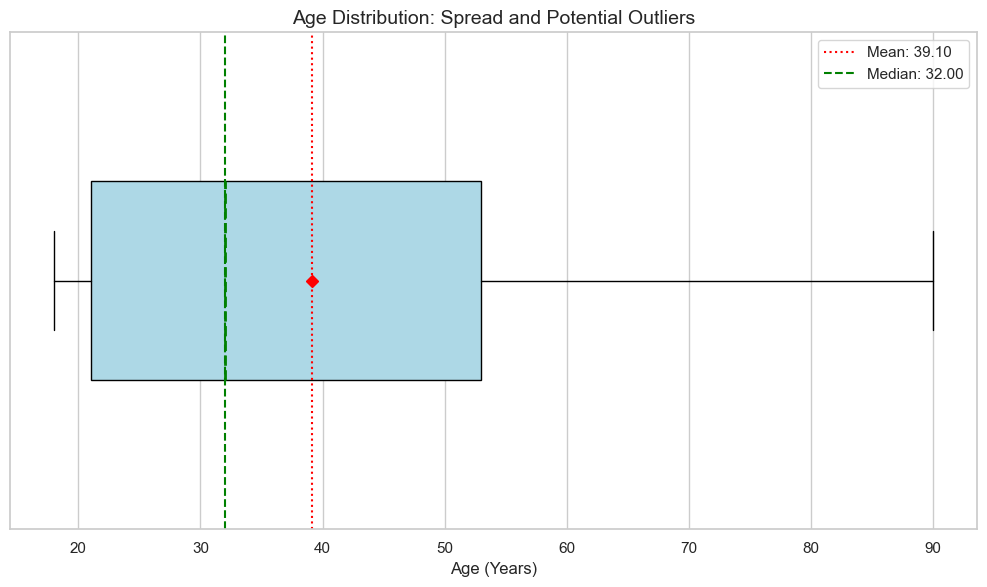

In [21]:
# AGE BOXPLOT

plt.figure(figsize=(10, 6))

plt.boxplot(
    df["Age"],
    vert=False,
    widths=0.4,
    patch_artist=True,
    showmeans=True,
    boxprops=dict(facecolor="lightblue"),
    meanprops=dict(
        marker="D",
        markerfacecolor="red",
        markeredgecolor="red"
    ),
    medianprops=dict(
        color="green",
        linestyle="--",
        linewidth=2
    )
)

plt.axvline(
    df["Age"].mean(),
    color="red",
    linestyle=":",
    label=f"Mean: {df['Age'].mean():.2f}"
)

plt.axvline(
    df["Age"].median(),
    color="green",
    linestyle="--",
    label=f"Median: {df['Age'].median():.2f}"
)

plt.xlabel("Age (Years)")
plt.yticks([])
plt.title("Age Distribution: Spread and Potential Outliers")
plt.legend()

plt.tight_layout()
plt.show()

In [22]:
# GENDER AND HORMONAL CHANGES ANALYSIS

hormonal_summary = pd.crosstab(
    df["Gender"],
    df["Hormonal Changes"],
    margins=True
)

display(hormonal_summary)

hormonal_percentage = pd.crosstab(
    df["Gender"],
    df["Hormonal Changes"],
    normalize="index"
) * 100

display(hormonal_percentage)

Hormonal Changes,Normal,Postmenopausal,All
Gender,,,
Female,475,491,966
Male,506,486,992
All,981,977,1958


Hormonal Changes,Normal,Postmenopausal
Gender,,
Female,49.1718,50.8282
Male,51.0081,48.9919


In [23]:
# HORMONAL CHANGES INCONSISTENCY

inconsistent_hormonal = df[
    (df["Gender"] == "Male") &
    (df["Hormonal Changes"] == "Postmenopausal")
]

male_count = df["Gender"].eq("Male").sum()

print(
    "Total Male Observations:",
    male_count
)

print(
    "Male Observations Classified as Postmenopausal:",
    len(inconsistent_hormonal)
)

print(
    "Percentage Among Male Observations:",
    f"{len(inconsistent_hormonal) / male_count * 100:.2f}%"
)

print(
    "Percentage of Entire Dataset:",
    f"{len(inconsistent_hormonal) / len(df) * 100:.2f}%"
)

display(inconsistent_hormonal.head())

Total Male Observations: 992
Male Observations Classified as Postmenopausal: 486
Percentage Among Male Observations: 48.99%
Percentage of Entire Dataset: 24.82%


Feature,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
4,101944,38,Male,Postmenopausal,Yes,African American,Normal,Low,Sufficient,Active,Yes,None,Rheumatoid Arthritis,None,Yes,1
6,107447,20,Male,Postmenopausal,Yes,African American,Underweight,Adequate,Sufficient,Sedentary,No,None,Rheumatoid Arthritis,None,No,1
7,103065,39,Male,Postmenopausal,Yes,Asian,Normal,Adequate,Sufficient,Sedentary,No,None,Rheumatoid Arthritis,Corticosteroids,Yes,1
8,103040,70,Male,Postmenopausal,No,Asian,Underweight,Low,Sufficient,Active,Yes,None,Rheumatoid Arthritis,Corticosteroids,No,1
15,109617,38,Male,Postmenopausal,Yes,African American,Normal,Adequate,Sufficient,Active,Yes,None,Rheumatoid Arthritis,None,No,1


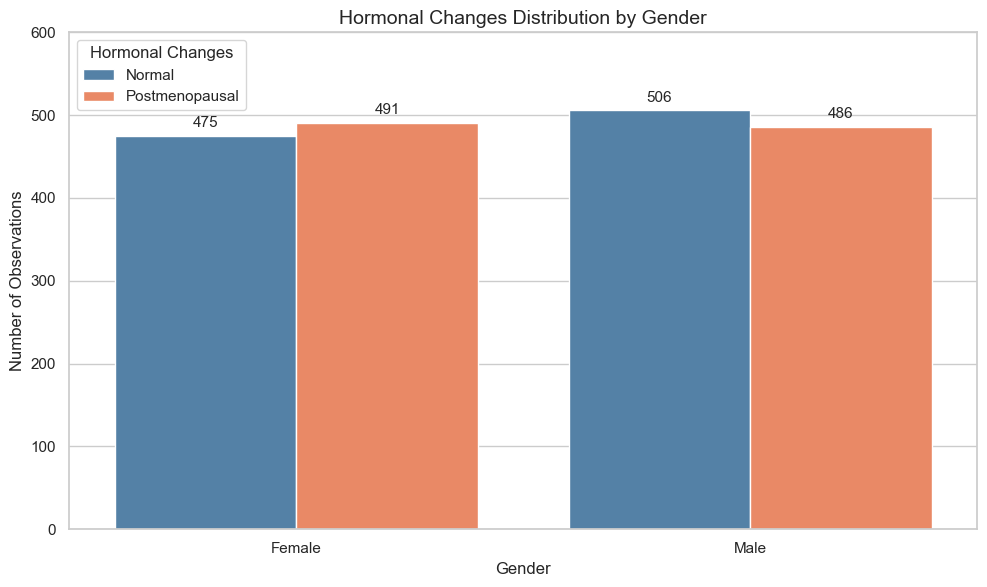

In [24]:
# GENDER VS HORMONAL CHANGES VISUALIZATION

plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df,
    x="Gender",
    hue="Hormonal Changes",
    palette=["steelblue", "coral"]
)

for container in ax.containers:
    ax.bar_label(container, padding=4)

plt.xlabel("Gender")
plt.ylabel("Number of Observations")
plt.title("Hormonal Changes Distribution by Gender")
plt.legend(title="Hormonal Changes")
plt.ylim(0, 600)

plt.tight_layout()
plt.show()

In [25]:
# TARGET VARIABLE VALIDATION

valid_target_values = [0, 1]

invalid_target = df[
    ~df[target].isin(valid_target_values)
]

print("Target Variable:", target)
print("Unique Values:", sorted(df[target].unique()))
print("Missing Target Values:", df[target].isna().sum())
print("Invalid Target Values:", len(invalid_target))

target_summary = pd.DataFrame({
    "Count": df[target].value_counts().sort_index(),
    "Percentage (%)": (
        df[target].value_counts(
            normalize=True
        ).sort_index() * 100
    )
})

target_summary.index = [
    "No Osteoporosis (0)",
    "Osteoporosis (1)"
]

display(target_summary)

Target Variable: Osteoporosis
Unique Values: [np.int64(0), np.int64(1)]
Missing Target Values: 0
Invalid Target Values: 0


,Count,Percentage (%)
No Osteoporosis (0),979,50.0000
Osteoporosis (1),979,50.0000


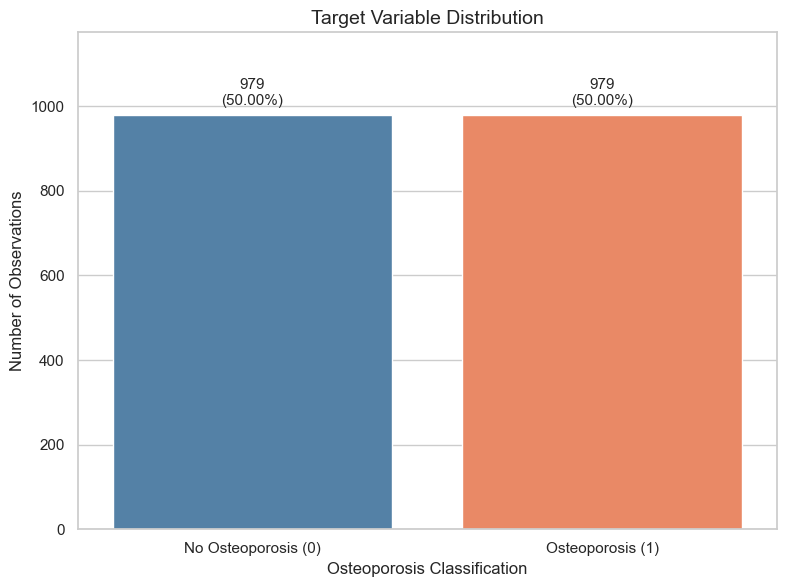

In [26]:
# TARGET DISTRIBUTION

plt.figure(figsize=(8, 6))

ax = sns.countplot(
    data=df,
    x=target,
    hue=target,
    palette=["steelblue", "coral"],
    legend=False
)

for container in ax.containers:

    labels = [
        f"{bar.get_height():.0f}\n"
        f"({bar.get_height() / len(df) * 100:.2f}%)"
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        padding=5
    )

plt.xticks(
    [0, 1],
    ["No Osteoporosis (0)", "Osteoporosis (1)"]
)

plt.xlabel("Osteoporosis Classification")
plt.ylabel("Number of Observations")
plt.title("Target Variable Distribution")
plt.ylim(0, df[target].value_counts().max() * 1.2)

plt.tight_layout()
plt.show()

In [27]:
# CONSOLIDATED DATA QUALITY REPORT

quality_report = pd.DataFrame({

    "Quality Check": [
        "Total Observations",
        "Total Columns",
        "Genuine Missing Values",
        "Complete Duplicate Rows",
        "Additional Repeated ID Occurrences",
        "Duplicate Rows Excluding ID",
        "Conflicting Target Records",
        "Invalid Age Records",
        "Hormonal Inconsistency Records",
        "Invalid Target Records"
    ],

    "Result": [
        len(df),
        df.shape[1],
        df.isna().sum().sum(),
        df.duplicated().sum(),
        df[id_col].duplicated().sum(),
        duplicate_without_id_count,
        len(conflicting_records),
        len(invalid_age),
        len(inconsistent_hormonal),
        len(invalid_target)
    ],

    "Action": [
        "Retain",
        "Review feature roles",
        "No imputation required",
        "No complete duplicates to remove",
        "Retain rows; exclude ID from modeling",
        "Investigate and prevent split leakage",
        "Retain and document",
        "Investigate if detected",
        "Evaluate with and without feature",
        "Investigate if detected"
    ]

})

display(quality_report)

,Quality Check,Result,Action
0,Total Observations,1958,Retain
1,Total Columns,16,Review feature roles
2,Genuine Missing Values,0,No imputation required
3,Complete Duplicate Rows,0,No complete duplicates to remove
4,Additional Repeated ID Occurrences,209,Retain rows; exclude ID from modeling
5,Duplicate Rows Excluding ID,4,Investigate and prevent split leakage
6,Conflicting Target Records,4,Retain and document
7,Invalid Age Records,0,Investigate if detected
8,Hormonal Inconsistency Records,486,Evaluate with and without feature
9,Invalid Target Records,0,Investigate if detected


## Data Quality Assessment Findings

1. The dataset contains 1,958 observations and 16 columns.

2. The target variable is Osteoporosis, with 979 positive
   and 979 negative observations.

3. No genuine missing values were identified after
   preserving valid None categories.

4. The ID column contains 1,749 unique values and 209
   additional ID occurrences. As clarified by the project
   team, ID is not a reliable unique patient identifier.

5. No complete duplicate rows were identified when
   considering all columns.

6. Four additional duplicate records were identified
   after excluding the ID column. These require careful
   consideration during data splitting.

7. Four observations belong to identical predictor
   profiles with conflicting target labels.

8. Patient ages range from 18 to 90 years.

9. A total of 486 male observations are classified as
   Postmenopausal, indicating a significant inconsistency
   in the Hormonal Changes feature.

10. Model performance will be evaluated with and without
    the Hormonal Changes feature.

11. The dataset is intended for research purposes and
    should not be considered clinically validated.

12. No observations have been removed at this stage.

### Data cleaning and validation


In [28]:
# CREATE CLEAN WORKING DATASET

df = df_original.copy(deep=True)

initial_shape = df.shape

# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

# Clean categorical values while preserving None categories
for col in df.select_dtypes(include=["object", "string"]).columns:

    df[col] = df[col].str.strip()

    # Convert genuinely empty strings into missing values
    df[col] = df[col].replace("", np.nan)

# Remove only complete duplicate records
complete_duplicates = df.duplicated().sum()

df = df.drop_duplicates().reset_index(drop=True)

print("Original Dataset Shape:", initial_shape)
print("Cleaned Dataset Shape:", df.shape)
print("Complete Duplicates Removed:", complete_duplicates)
print("Remaining Missing Values:", df.isna().sum().sum())

display(df.head())

Original Dataset Shape: (1958, 16)
Cleaned Dataset Shape: (1958, 16)
Complete Duplicates Removed: 0
Remaining Missing Values: 0


,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
0,104866,69,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,Corticosteroids,Yes,1
1,101999,32,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,No,None,None,None,Yes,1
2,106567,89,Female,Postmenopausal,No,Caucasian,Normal,Adequate,Sufficient,Active,No,Moderate,Hyperthyroidism,Corticosteroids,No,1
3,102316,78,Female,Normal,No,Caucasian,Underweight,Adequate,Insufficient,Sedentary,Yes,None,Rheumatoid Arthritis,Corticosteroids,No,1
4,101944,38,Male,Postmenopausal,Yes,African American,Normal,Low,Sufficient,Active,Yes,None,Rheumatoid Arthritis,None,Yes,1


In [29]:
# POST-CLEANING DATA VALIDATION

validation_summary = pd.DataFrame({
    "Validation Check": [
        "Total Observations",
        "Total Columns",
        "Missing Values",
        "Complete Duplicate Rows",
        "Repeated ID Occurrences",
        "Invalid Age Values",
        "Invalid Target Values"
    ],
    "Result": [
        len(df),
        df.shape[1],
        df.isna().sum().sum(),
        df.duplicated().sum(),
        df[id_col].duplicated().sum(),
        (~df["Age"].between(1, 120)).sum(),
        (~df[target].isin([0, 1])).sum()
    ]
})

display(validation_summary)

assert df[target].isin([0, 1]).all(), "Invalid target values detected"

print("Target validation completed successfully.")

,Validation Check,Result
0,Total Observations,1958
1,Total Columns,16
2,Missing Values,0
3,Complete Duplicate Rows,0
4,Repeated ID Occurrences,209
5,Invalid Age Values,0
6,Invalid Target Values,0


Target validation completed successfully.


In [30]:
# DEFINE FEATURES FOR EXPLORATORY DATA ANALYSIS

target = "Osteoporosis"
id_col = "Id"

feature_cols = [
    col for col in df.columns
    if col not in [id_col, target]
]

numerical_cols = [
    col for col in feature_cols
    if pd.api.types.is_numeric_dtype(df[col])
]

categorical_cols = [
    col for col in feature_cols
    if col not in numerical_cols
]

print("Numerical Features:", numerical_cols)

print("\nCategorical Features:")
for i, col in enumerate(categorical_cols, 1):
    print(f"{i}. {col}")

print("\nTotal Candidate Features:", len(feature_cols))

Numerical Features: ['Age']

Categorical Features:
1. Gender
2. Hormonal Changes
3. Family History
4. Race/Ethnicity
5. Body Weight
6. Calcium Intake
7. Vitamin D Intake
8. Physical Activity
9. Smoking
10. Alcohol Consumption
11. Medical Conditions
12. Medications
13. Prior Fractures

Total Candidate Features: 14


### Create a separate EDA dataset
We will create additional analytical columns without modifying the original modeling features.

In [31]:
# CREATE SEPARATE EDA DATASET

df_eda = df.copy(deep=True)

df_eda["Osteoporosis Status"] = df_eda[target].map({
    0: "No Osteoporosis",
    1: "Osteoporosis"
})

status_order = [
    "No Osteoporosis",
    "Osteoporosis"
]

class_palette = {
    "No Osteoporosis": "steelblue",
    "Osteoporosis": "coral"
}

display(df_eda.head())

,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis,Osteoporosis Status
0,104866,69,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,Corticosteroids,Yes,1,Osteoporosis
1,101999,32,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,No,None,None,None,Yes,1,Osteoporosis
2,106567,89,Female,Postmenopausal,No,Caucasian,Normal,Adequate,Sufficient,Active,No,Moderate,Hyperthyroidism,Corticosteroids,No,1,Osteoporosis
3,102316,78,Female,Normal,No,Caucasian,Underweight,Adequate,Insufficient,Sedentary,Yes,None,Rheumatoid Arthritis,Corticosteroids,No,1,Osteoporosis
4,101944,38,Male,Postmenopausal,Yes,African American,Normal,Low,Sufficient,Active,Yes,None,Rheumatoid Arthritis,None,Yes,1,Osteoporosis


### Univariate analysis

,Count,Percentage (%)
Osteoporosis Status,,
No Osteoporosis,979,50.0000
Osteoporosis,979,50.0000


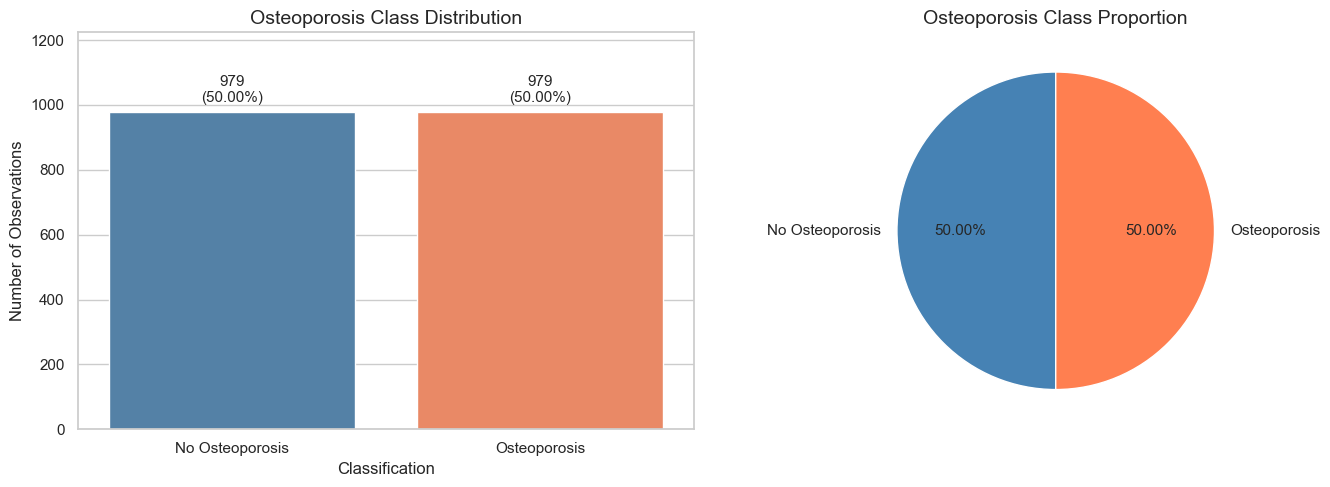

In [32]:
# TARGET VARIABLE DISTRIBUTION

target_counts = (
    df_eda["Osteoporosis Status"]
    .value_counts()
    .reindex(status_order, fill_value=0)
)

target_distribution = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_counts / len(df_eda) * 100
})

display(target_distribution)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count plot
ax = sns.countplot(
    data=df_eda,
    x="Osteoporosis Status",
    hue="Osteoporosis Status",
    order=status_order,
    palette=class_palette,
    legend=False,
    ax=axes[0]
)

for container in ax.containers:

    labels = [
        f"{bar.get_height():.0f}\n"
        f"({bar.get_height() / len(df_eda):.2%})"
        for bar in container
    ]

    ax.bar_label(container, labels=labels, padding=5)

axes[0].set_title("Osteoporosis Class Distribution")
axes[0].set_xlabel("Classification")
axes[0].set_ylabel("Number of Observations")
axes[0].set_ylim(0, target_counts.max() * 1.25)

# Pie chart
axes[1].pie(
    target_counts,
    labels=target_counts.index,
    autopct="%1.2f%%",
    colors=["steelblue", "coral"],
    startangle=90,
    wedgeprops={"edgecolor": "white"}
)

axes[1].set_title("Osteoporosis Class Proportion")

plt.tight_layout()
plt.show()

In [33]:
# AGE DESCRIPTIVE STATISTICS

age_summary = pd.DataFrame({
    "Statistic": [
        "Count",
        "Mean",
        "Median",
        "Mode",
        "Standard Deviation",
        "Variance",
        "Minimum",
        "Maximum",
        "Range",
        "25th Percentile",
        "75th Percentile",
        "Skewness",
        "Kurtosis"
    ],
    "Value": [
        df["Age"].count(),
        df["Age"].mean(),
        df["Age"].median(),
        df["Age"].mode().iloc[0],
        df["Age"].std(),
        df["Age"].var(),
        df["Age"].min(),
        df["Age"].max(),
        df["Age"].max() - df["Age"].min(),
        df["Age"].quantile(0.25),
        df["Age"].quantile(0.75),
        df["Age"].skew(),
        df["Age"].kurtosis()
    ]
})

display(age_summary.round(4))

,Statistic,Value
0,Count,1958.0000
1,Mean,39.1011
2,Median,32.0000
3,Mode,18.0000
4,Standard Deviation,21.3554
5,Variance,456.0542
6,Minimum,18.0000
7,Maximum,90.0000
8,Range,72.0000
9,25th Percentile,21.0000


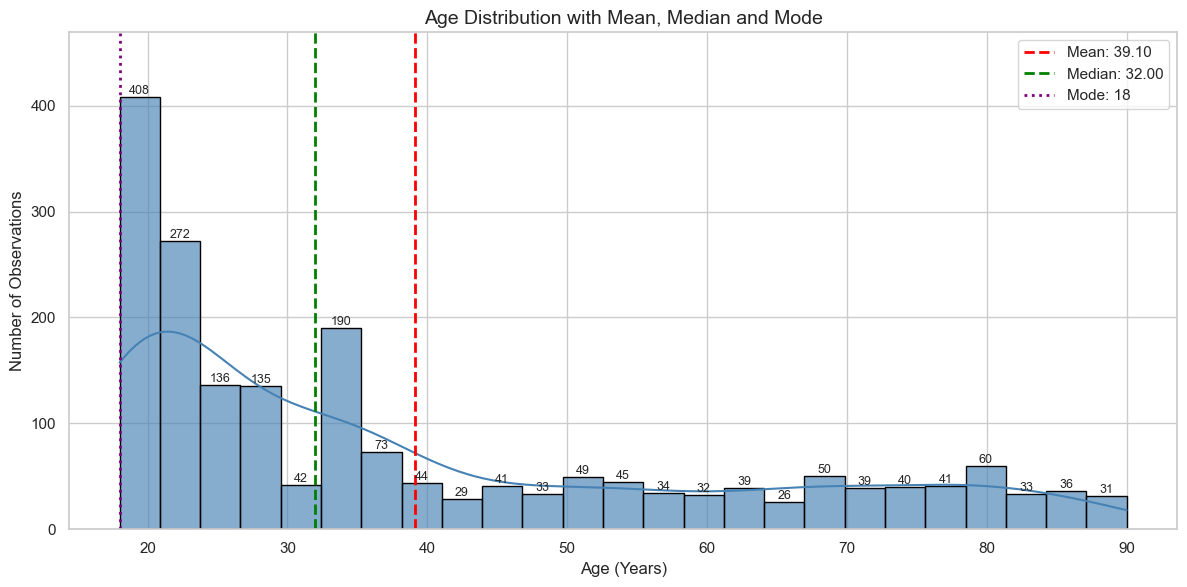

In [34]:
# AGE DISTRIBUTION ANALYSIS

mean_age = df["Age"].mean()
median_age = df["Age"].median()
mode_age = df["Age"].mode().iloc[0]

plt.figure(figsize=(12, 6))

ax = sns.histplot(
    data=df,
    x="Age",
    bins=25,
    kde=True,
    color="steelblue",
    edgecolor="black",
    alpha=0.65
)

# Mean
plt.axvline(
    mean_age,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_age:.2f}"
)

# Median
plt.axvline(
    median_age,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_age:.2f}"
)

# Mode
plt.axvline(
    mode_age,
    color="purple",
    linestyle=":",
    linewidth=2,
    label=f"Mode: {mode_age}"
)

# Frequency labels
for bar in ax.patches:

    height = bar.get_height()

    if height > 0:
        ax.annotate(
            f"{height:.0f}",
            (
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.xlabel("Age (Years)")
plt.ylabel("Number of Observations")
plt.title("Age Distribution with Mean, Median and Mode")
plt.legend()
plt.margins(y=0.15)

plt.tight_layout()
plt.show()

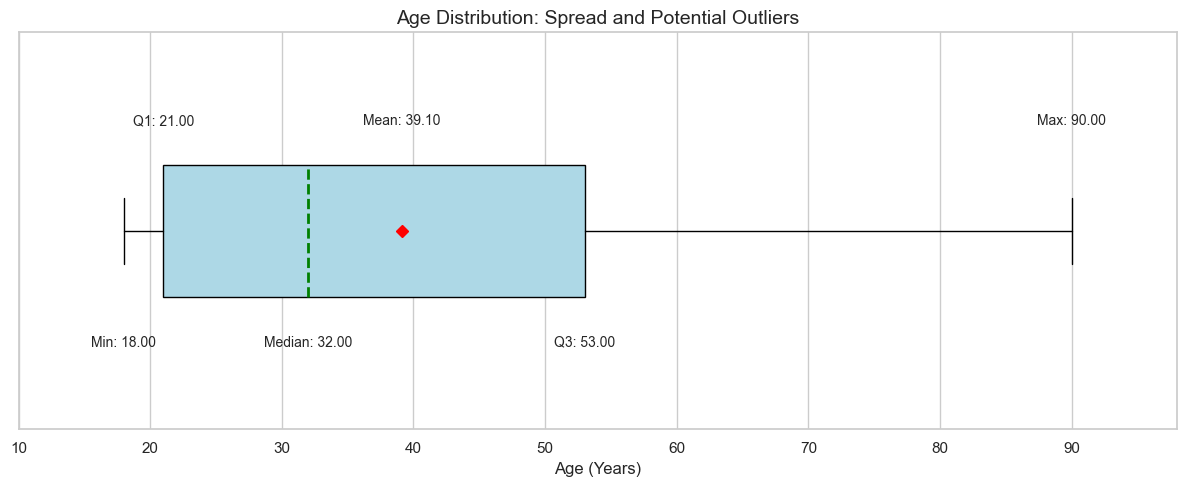

Q1          : 21.00
Q3          : 53.00
IQR         : 32.00
Lower Bound : -27.00
Upper Bound : 101.00


In [35]:
# AGE BOXPLOT WITH STATISTICAL ANNOTATIONS

Q1 = df["Age"].quantile(0.25)
Q3 = df["Age"].quantile(0.75)
IQR = Q3 - Q1

median_age = df["Age"].median()
mean_age = df["Age"].mean()

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

plt.figure(figsize=(12, 5))

plt.boxplot(
    df["Age"],
    vert=False,
    widths=0.4,
    patch_artist=True,
    showmeans=True,
    boxprops=dict(facecolor="lightblue"),
    meanprops=dict(
        marker="D",
        markerfacecolor="red",
        markeredgecolor="red"
    ),
    medianprops=dict(
        color="green",
        linestyle="--",
        linewidth=2
    )
)

for value, label, y in [
    (df["Age"].min(), "Min", 0.65),
    (Q1, "Q1", 1.32),
    (median_age, "Median", 0.65),
    (mean_age, "Mean", 1.32),
    (Q3, "Q3", 0.65),
    (df["Age"].max(), "Max", 1.32)
]:

    plt.text(
        value,
        y,
        f"{label}: {value:.2f}",
        ha="center",
        fontsize=10
    )

plt.xlabel("Age (Years)")
plt.yticks([])
plt.ylim(0.4, 1.6)
plt.xlim(df["Age"].min() - 8, df["Age"].max() + 8)

plt.title("Age Distribution: Spread and Potential Outliers")

plt.tight_layout()
plt.show()

print(f"Q1          : {Q1:.2f}")
print(f"Q3          : {Q3:.2f}")
print(f"IQR         : {IQR:.2f}")
print(f"Lower Bound : {lower_bound:.2f}")
print(f"Upper Bound : {upper_bound:.2f}")

In [36]:
# CREATE AGE GROUPS FOR EDA

age_bins = [18, 30, 40, 50, 60, 70, np.inf]

age_labels = [
    "18-29",
    "30-39",
    "40-49",
    "50-59",
    "60-69",
    "70+"
]

df_eda["Age Group"] = pd.cut(
    df_eda["Age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

age_group_counts = (
    df_eda["Age Group"]
    .value_counts()
    .reindex(age_labels, fill_value=0)
)

age_group_summary = pd.DataFrame({
    "Count": age_group_counts,
    "Percentage (%)": age_group_counts / len(df_eda) * 100
})

display(age_group_summary)

,Count,Percentage (%)
Age Group,,
18-29,951,48.5700
30-39,314,16.0368
40-49,138,7.0480
50-59,140,7.1502
60-69,135,6.8948
70+,280,14.3003


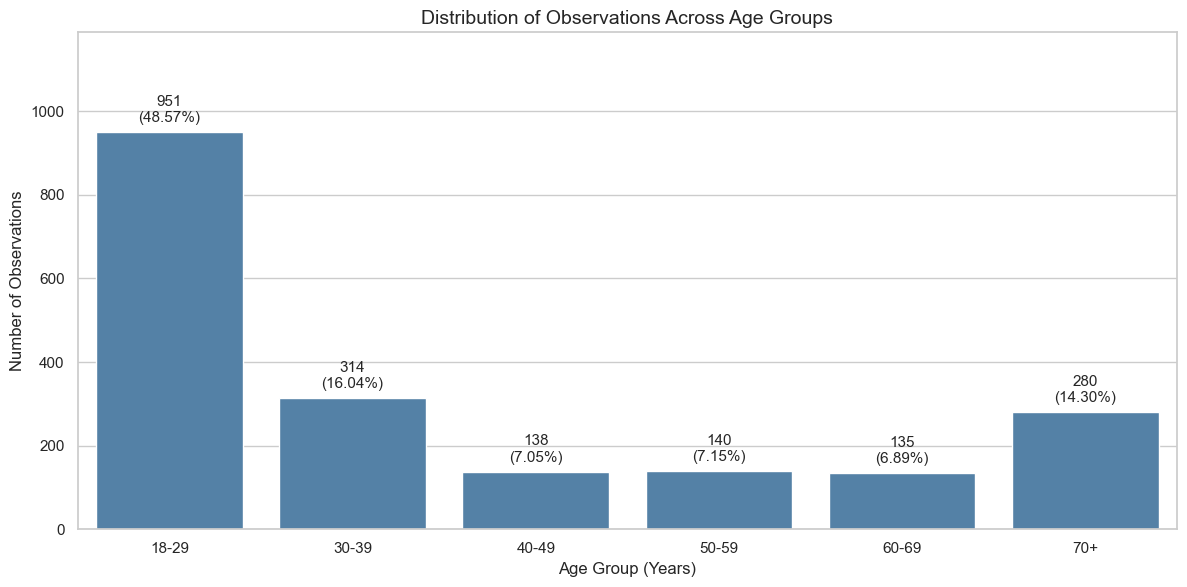

In [37]:
# AGE GROUP DISTRIBUTION

plt.figure(figsize=(12, 6))

ax = sns.countplot(
    data=df_eda,
    x="Age Group",
    order=age_labels,
    color="steelblue"
)

for container in ax.containers:

    labels = [
        f"{bar.get_height():.0f}\n"
        f"({bar.get_height() / len(df_eda):.2%})"
        for bar in container
    ]

    ax.bar_label(container, labels=labels, padding=5)

plt.xlabel("Age Group (Years)")
plt.ylabel("Number of Observations")
plt.title("Distribution of Observations Across Age Groups")

plt.ylim(0, age_group_counts.max() * 1.25)

plt.tight_layout()
plt.show()

In [38]:
# CATEGORICAL UNIVARIATE ANALYSIS FUNCTION

def categorical_univariate_analysis(data, column):

    counts = data[column].value_counts(dropna=False)

    summary = pd.DataFrame({
        "Count": counts,
        "Percentage (%)": counts / len(data) * 100
    })

    print("=" * 65)
    print(f"UNIVARIATE ANALYSIS: {column}")
    print("=" * 65)

    display(summary.round(2))

    plt.figure(figsize=(10, 5))

    ax = sns.countplot(
        data=data,
        y=column,
        order=data[column].value_counts().index,
        color="steelblue"
    )

    for container in ax.containers:

        labels = [
            f"{bar.get_width():.0f} "
            f"({bar.get_width() / len(data):.2%})"
            for bar in container
        ]

        ax.bar_label(
            container,
            labels=labels,
            padding=5
        )

    plt.xlim(0, max(1, counts.max() * 1.35))

    plt.xlabel("Number of Observations")
    plt.ylabel(column)
    plt.title(f"Distribution of {column}")

    plt.tight_layout()
    
    plt.show()

UNIVARIATE ANALYSIS: Gender


,Count,Percentage (%)
Gender,,
Male,992,50.6600
Female,966,49.3400


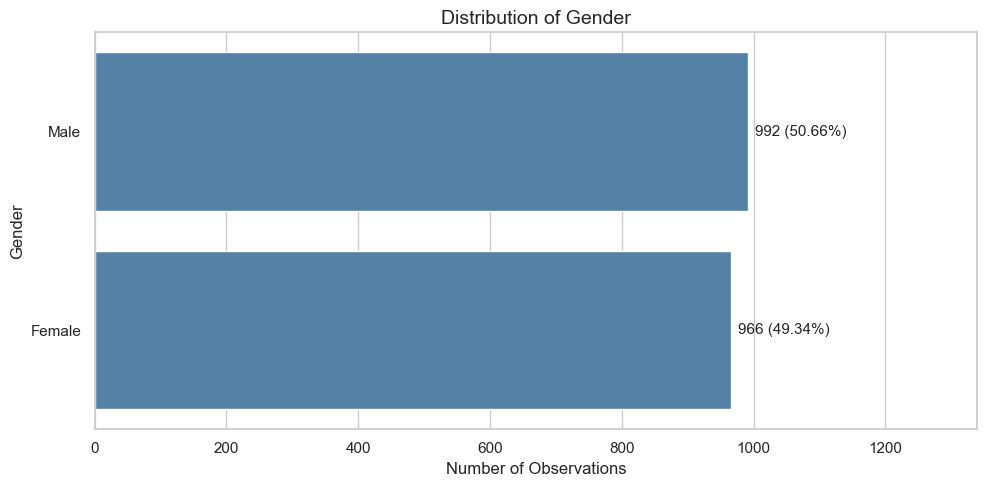

UNIVARIATE ANALYSIS: Hormonal Changes


,Count,Percentage (%)
Hormonal Changes,,
Normal,981,50.1000
Postmenopausal,977,49.9000


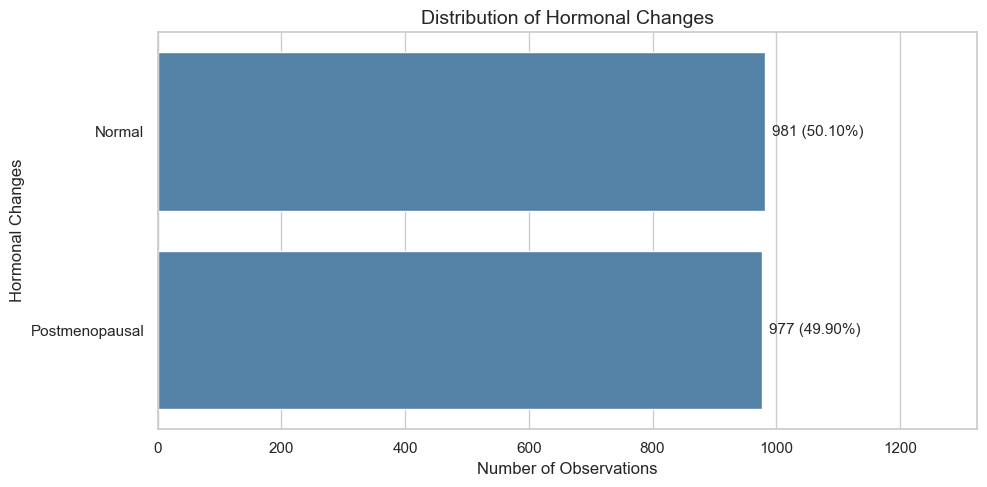

UNIVARIATE ANALYSIS: Family History


,Count,Percentage (%)
Family History,,
No,998,50.9700
Yes,960,49.0300


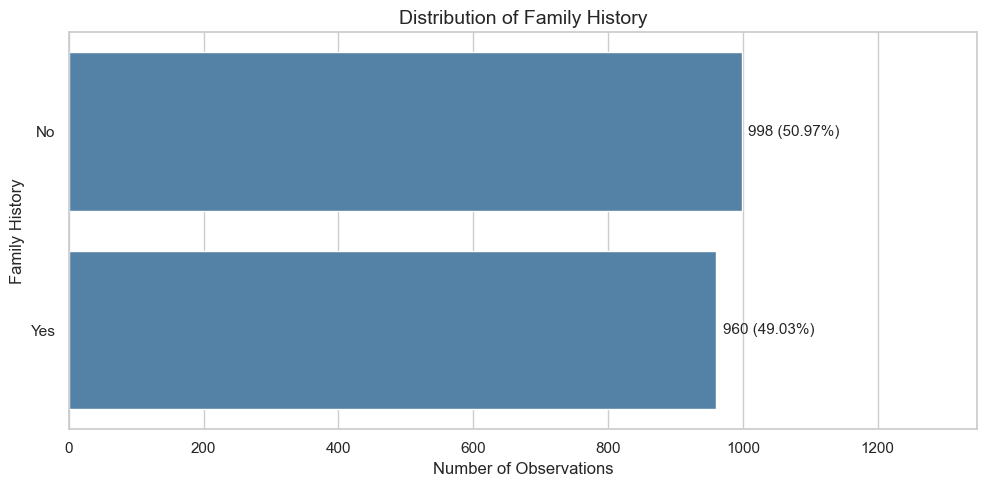

UNIVARIATE ANALYSIS: Race/Ethnicity


,Count,Percentage (%)
Race/Ethnicity,,
African American,681,34.7800
Caucasian,646,32.9900
Asian,631,32.2300


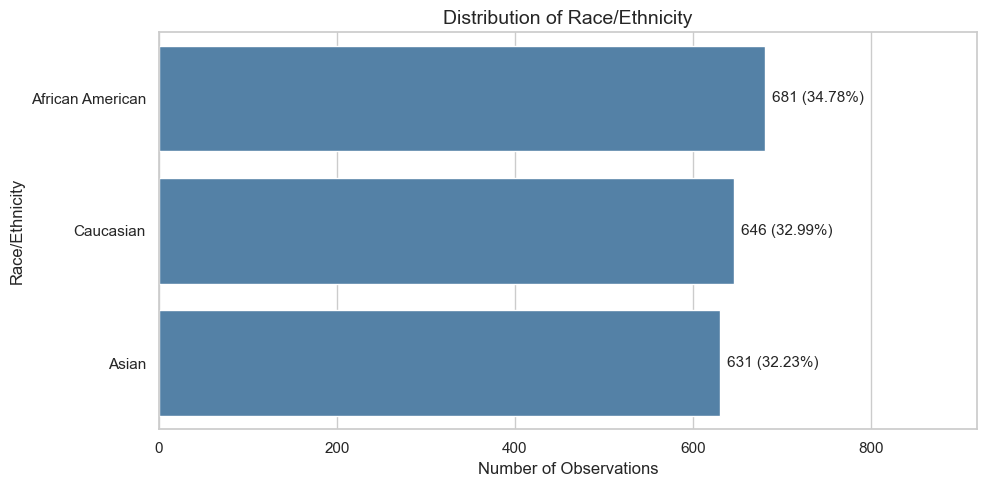

UNIVARIATE ANALYSIS: Body Weight


,Count,Percentage (%)
Body Weight,,
Normal,1027,52.4500
Underweight,931,47.5500


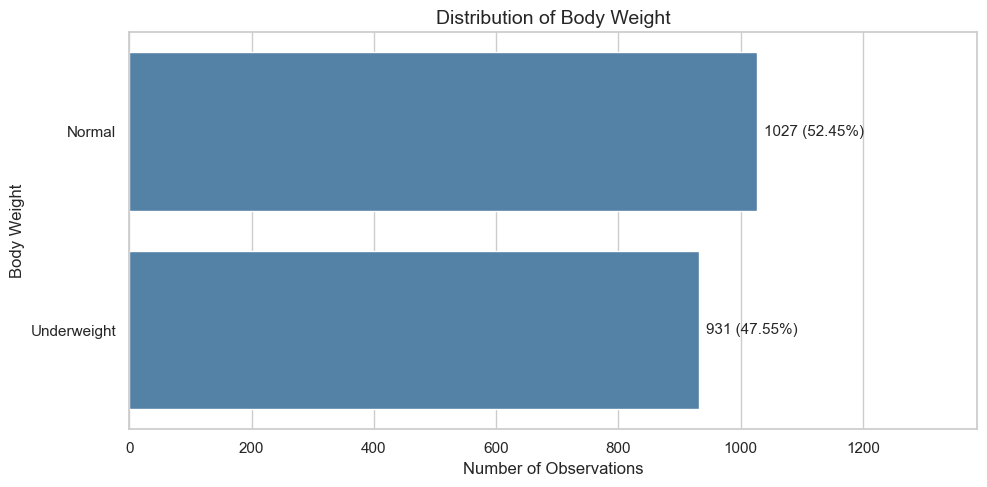

UNIVARIATE ANALYSIS: Calcium Intake


,Count,Percentage (%)
Calcium Intake,,
Low,1004,51.2800
Adequate,954,48.7200


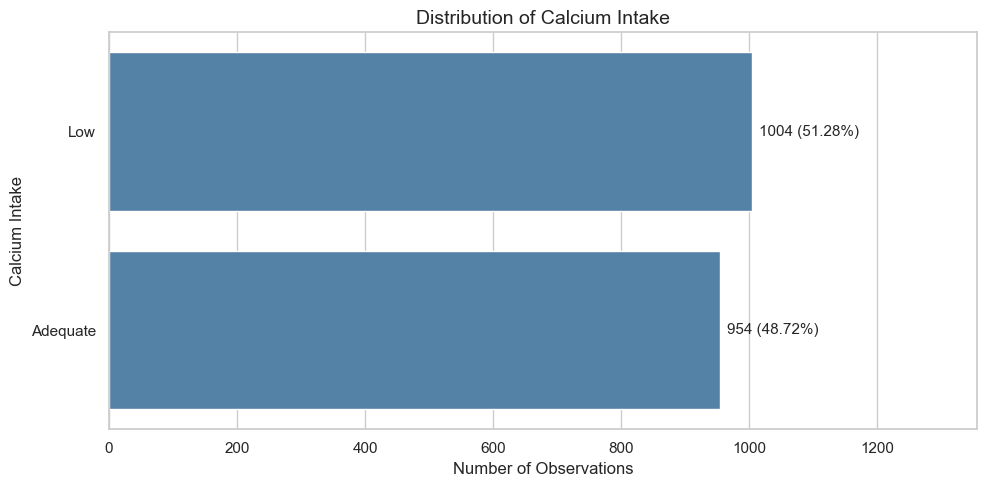

UNIVARIATE ANALYSIS: Vitamin D Intake


,Count,Percentage (%)
Vitamin D Intake,,
Sufficient,1011,51.6300
Insufficient,947,48.3700


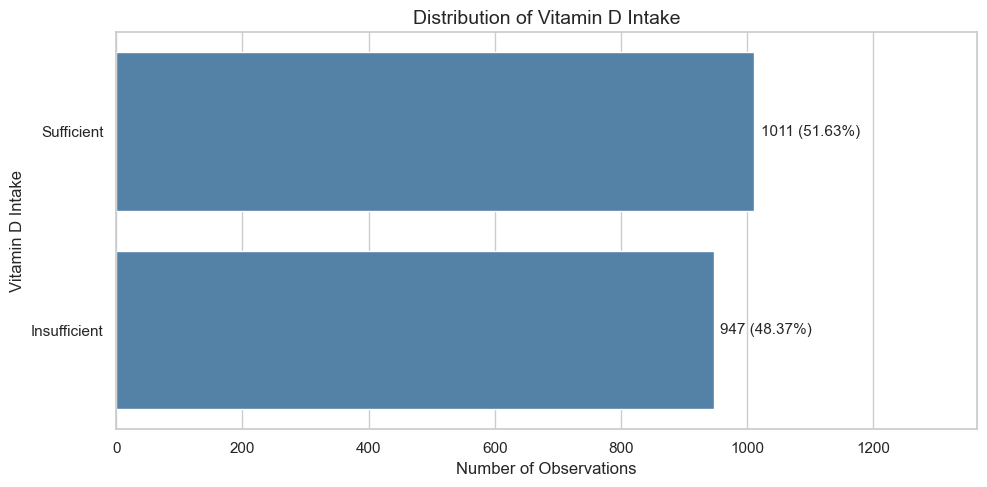

UNIVARIATE ANALYSIS: Physical Activity


,Count,Percentage (%)
Physical Activity,,
Active,1021,52.1500
Sedentary,937,47.8500


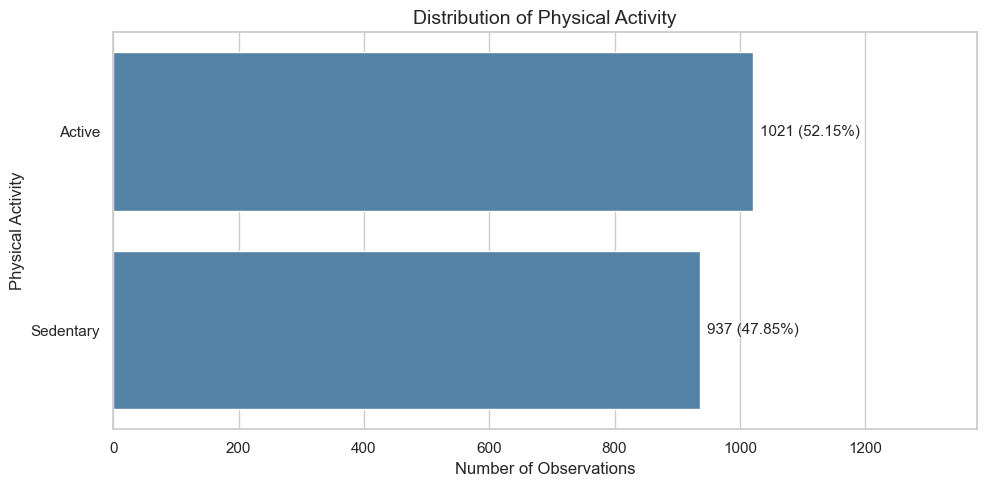

UNIVARIATE ANALYSIS: Smoking


,Count,Percentage (%)
Smoking,,
Yes,982,50.1500
No,976,49.8500


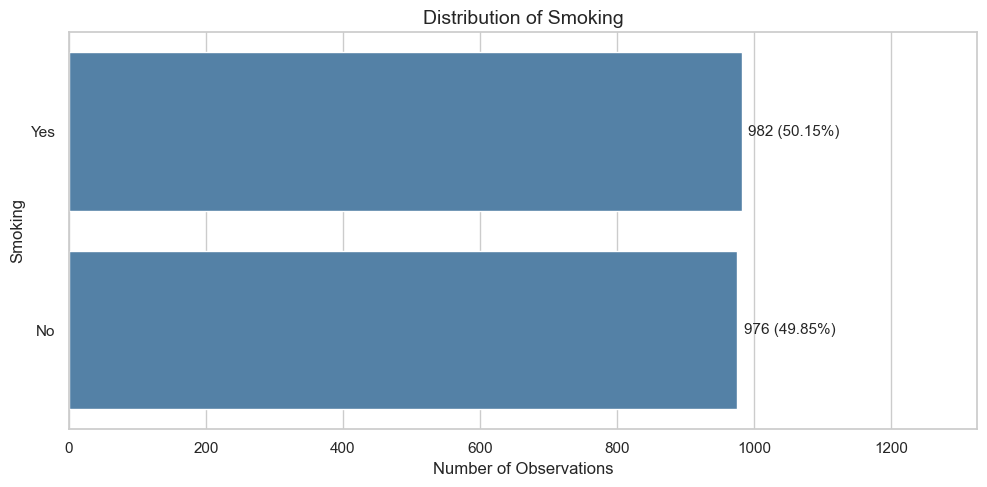

UNIVARIATE ANALYSIS: Alcohol Consumption


,Count,Percentage (%)
Alcohol Consumption,,
None,988,50.4600
Moderate,970,49.5400


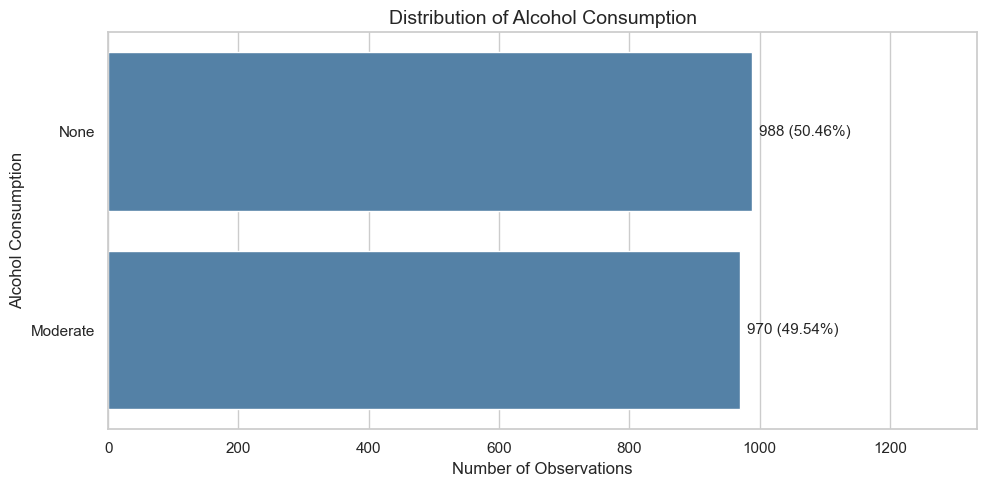

UNIVARIATE ANALYSIS: Medical Conditions


,Count,Percentage (%)
Medical Conditions,,
Hyperthyroidism,678,34.6300
None,647,33.0400
Rheumatoid Arthritis,633,32.3300


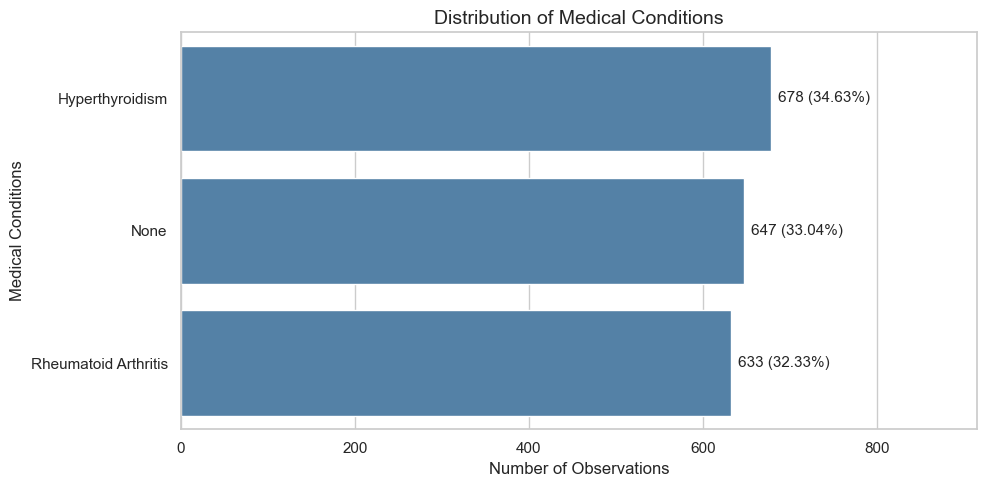

UNIVARIATE ANALYSIS: Medications


,Count,Percentage (%)
Medications,,
None,985,50.3100
Corticosteroids,973,49.6900


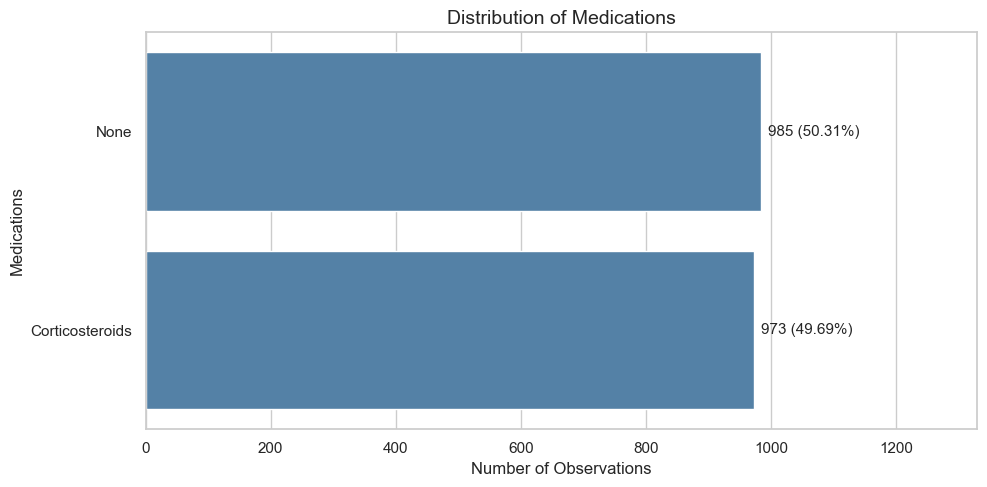

UNIVARIATE ANALYSIS: Prior Fractures


,Count,Percentage (%)
Prior Fractures,,
Yes,983,50.2000
No,975,49.8000


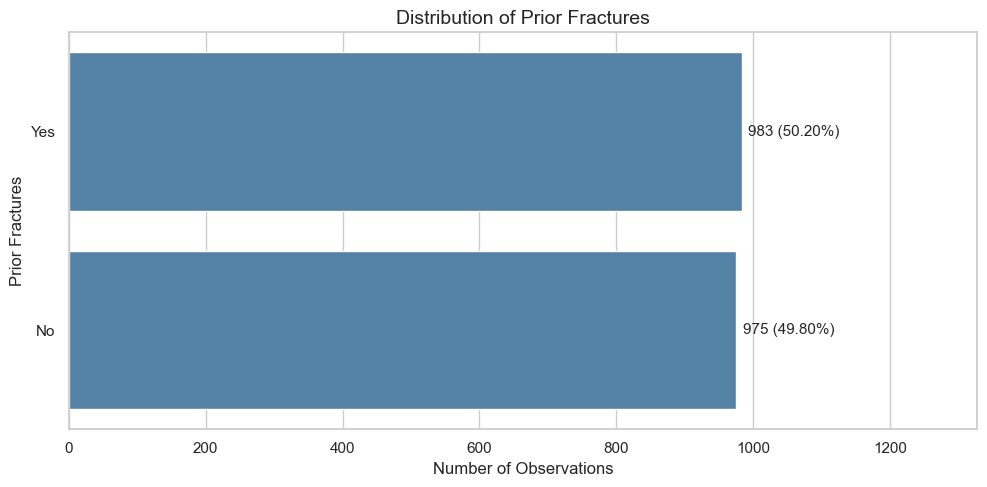

In [39]:
# UNIVARIATE ANALYSIS OF ALL CATEGORICAL FEATURES

for col in categorical_cols:

    categorical_univariate_analysis(
        data=df_eda,
        column=col
    )

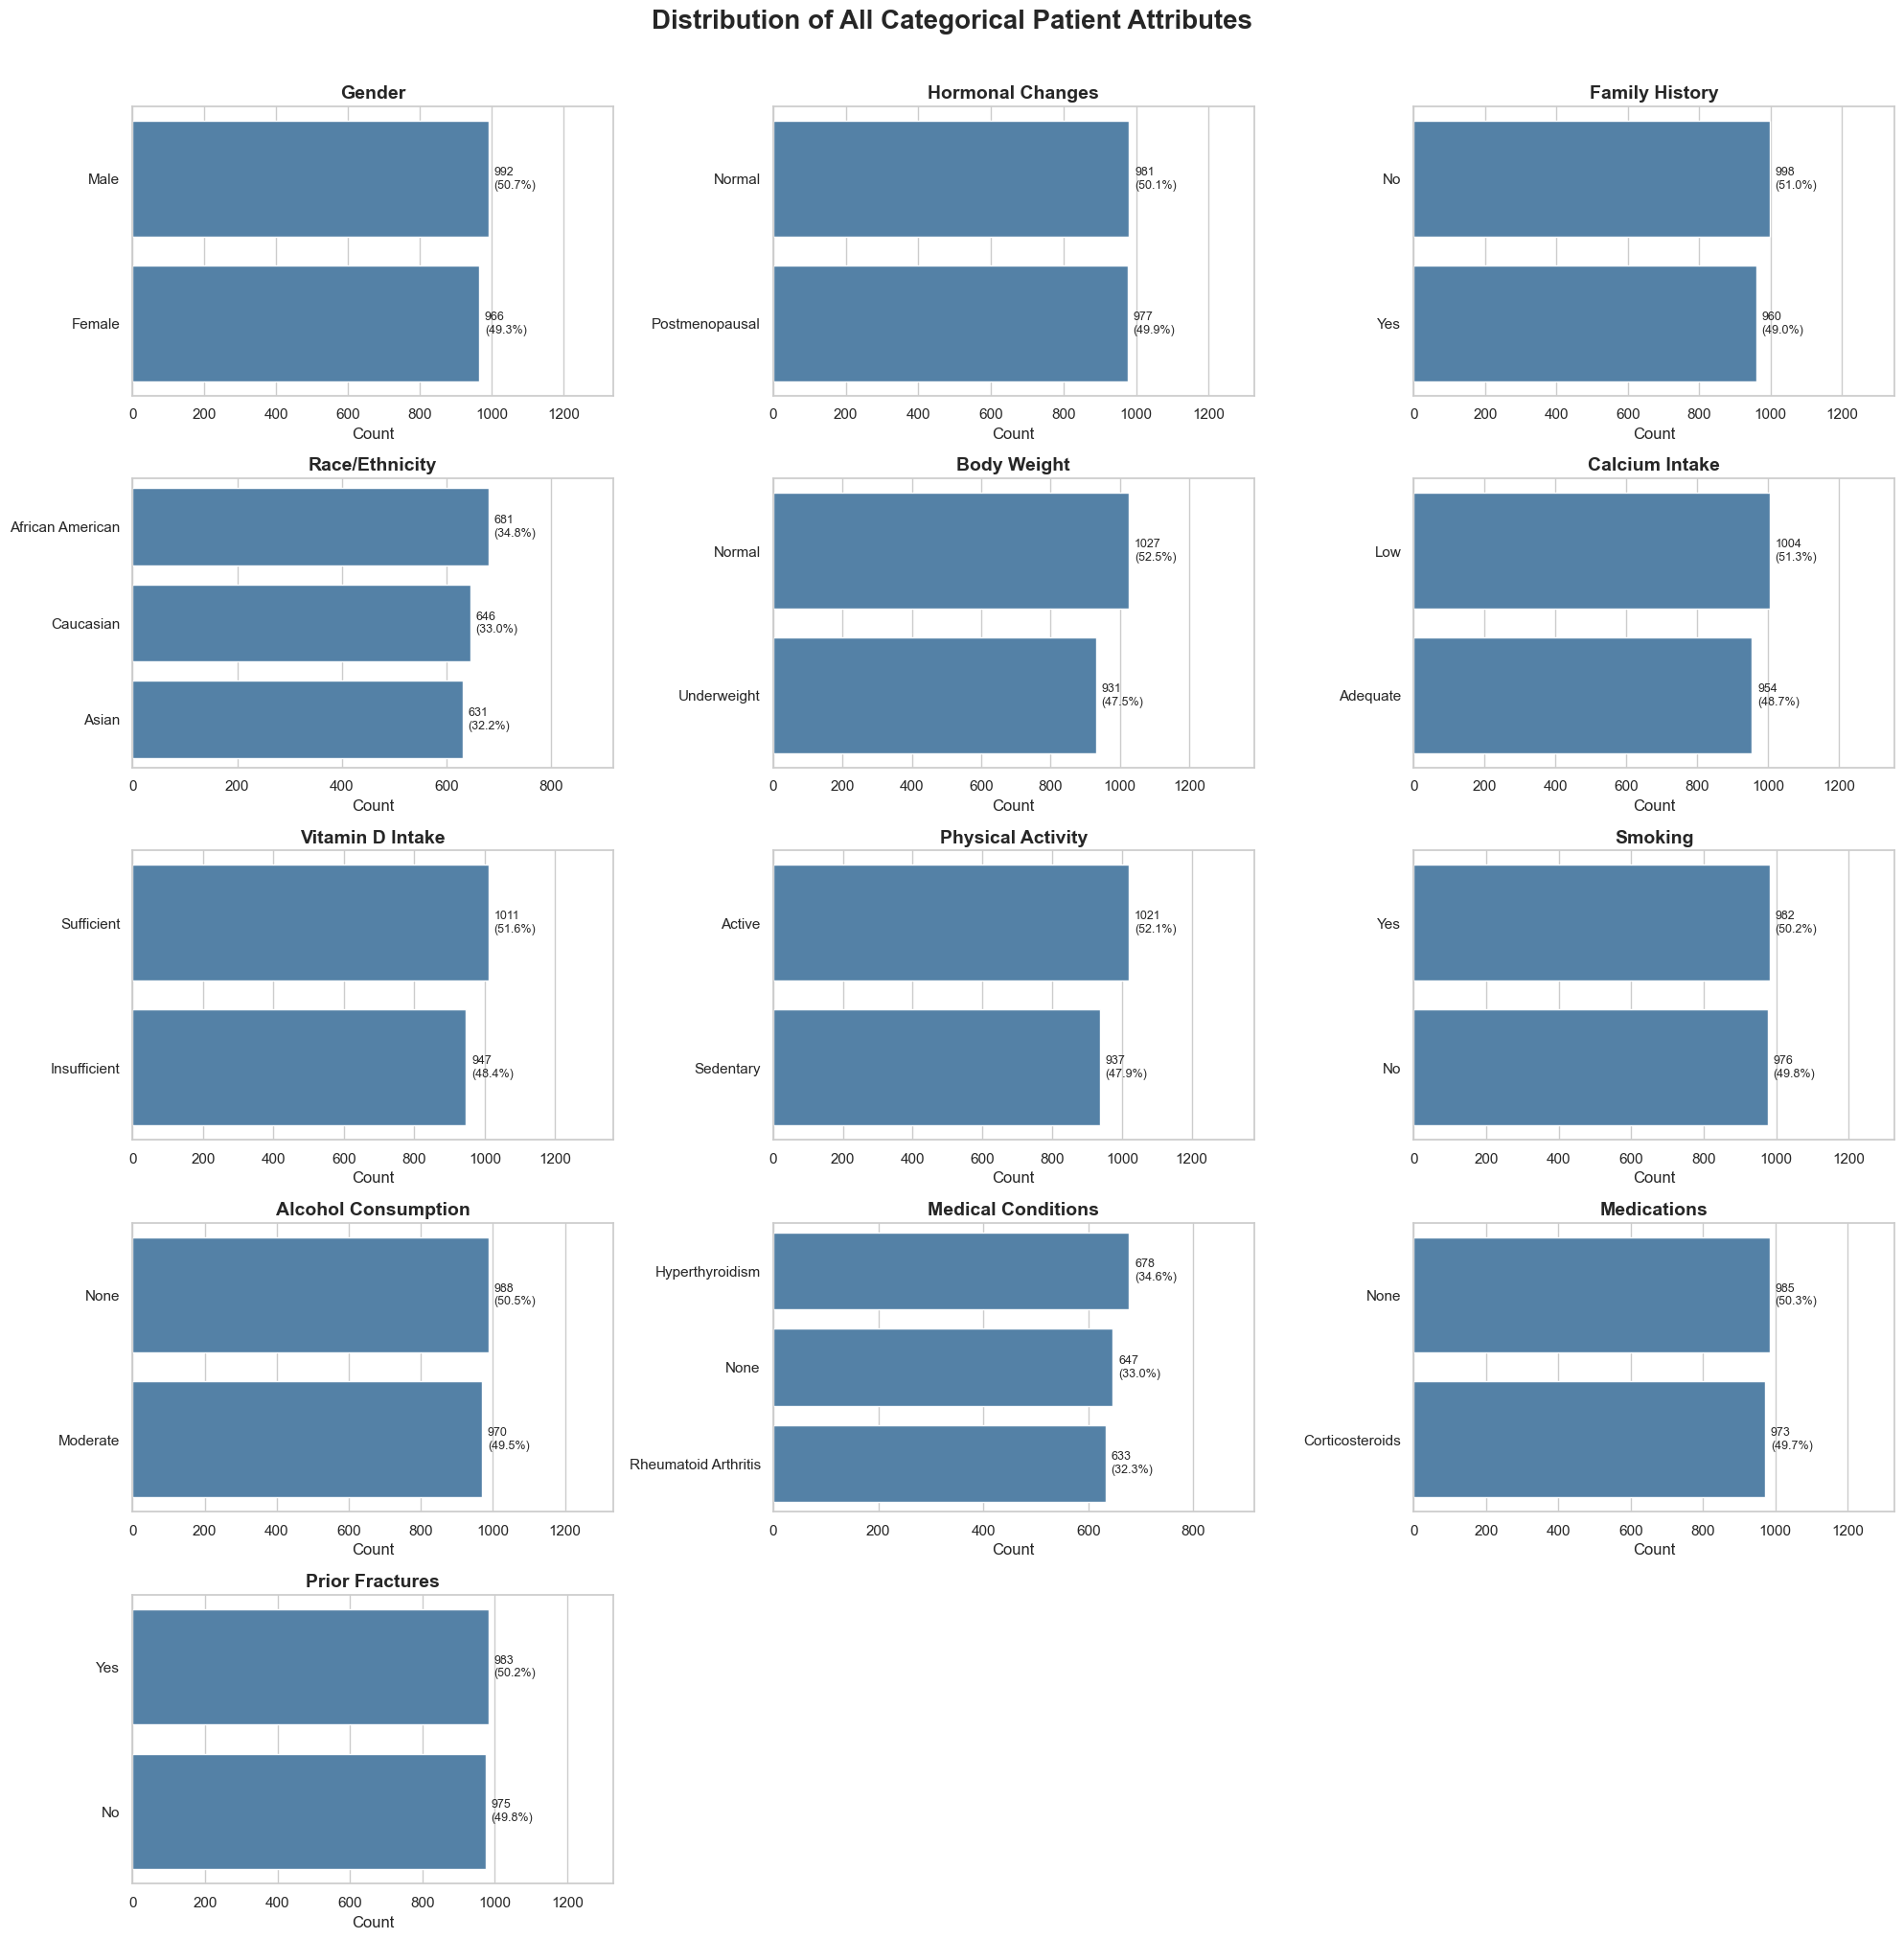

In [40]:
# COMBINED CATEGORICAL DISTRIBUTION DASHBOARD

n_cols = 3
n_rows = int(np.ceil(len(categorical_cols) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(20, n_rows * 4)
)

axes = axes.flatten()

for i, col in enumerate(categorical_cols):

    order = df[col].value_counts().index

    ax = sns.countplot(
        data=df,
        y=col,
        order=order,
        color="steelblue",
        ax=axes[i]
    )

    for container in ax.containers:

        labels = [
            f"{bar.get_width():.0f}\n"
            f"({bar.get_width() / len(df):.1%})"
            for bar in container
        ]

        ax.bar_label(
            container,
            labels=labels,
            padding=4,
            fontsize=9
        )

    ax.set_title(col, fontweight="bold")
    ax.set_xlabel("Count")
    ax.set_ylabel("")
    ax.set_xlim(0, df[col].value_counts().max() * 1.35)

for i in range(len(categorical_cols), len(axes)):
    axes[i].set_visible(False)

fig.suptitle(
    "Distribution of All Categorical Patient Attributes",
    fontsize=20,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

### Bivariate analysis

In [41]:
# AGE VS OSTEOPOROSIS - STATISTICAL SUMMARY

age_target_summary = df.groupby(target)["Age"].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

age_target_summary.index = status_order

display(age_target_summary.round(2))

,count,mean,median,std,min,max
No Osteoporosis,979,24.3400,22.0000,6.1100,18,38
Osteoporosis,979,53.8600,53.0000,20.9600,18,90


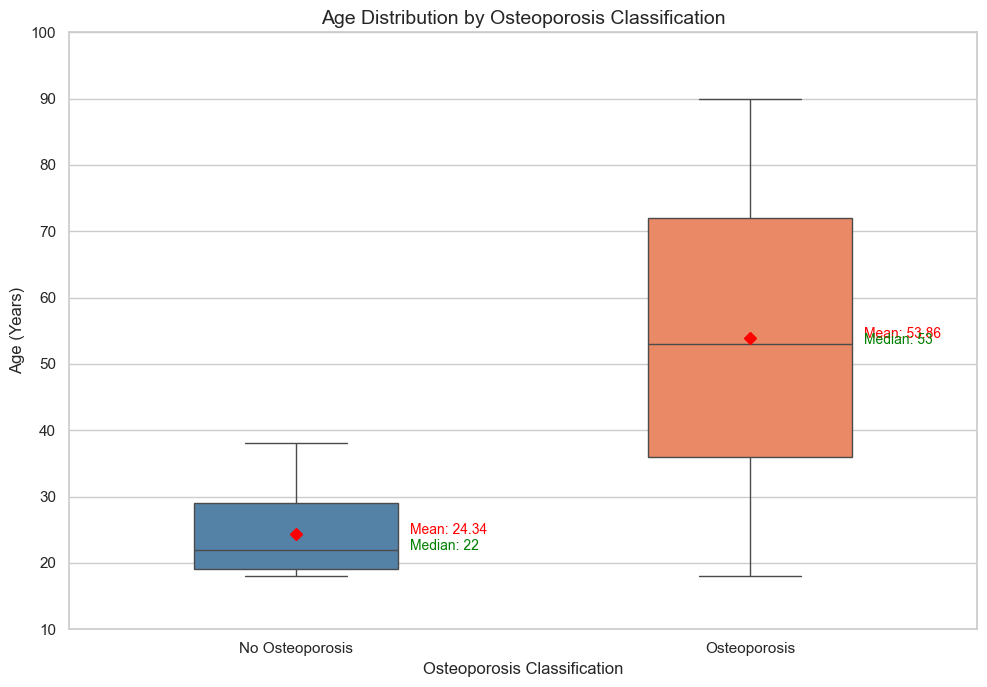

In [42]:
# AGE VS OSTEOPOROSIS - BOXPLOT

plt.figure(figsize=(10, 7))

ax = sns.boxplot(
    data=df_eda,
    x="Osteoporosis Status",
    y="Age",
    hue="Osteoporosis Status",
    order=status_order,
    palette=class_palette,
    legend=False,
    width=0.45,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "red",
        "markeredgecolor": "red"
    }
)

for i, status in enumerate(status_order):

    ages = df_eda.loc[
        df_eda["Osteoporosis Status"] == status,
        "Age"
    ]

    ax.text(
        i + 0.25,
        ages.mean(),
        f"Mean: {ages.mean():.2f}",
        color="red",
        fontsize=10
    )

    ax.text(
        i + 0.25,
        ages.median(),
        f"Median: {ages.median():.0f}",
        color="green",
        fontsize=10
    )

plt.xlabel("Osteoporosis Classification")
plt.ylabel("Age (Years)")
plt.title("Age Distribution by Osteoporosis Classification")
plt.ylim(10, 100)

plt.tight_layout()
plt.show()

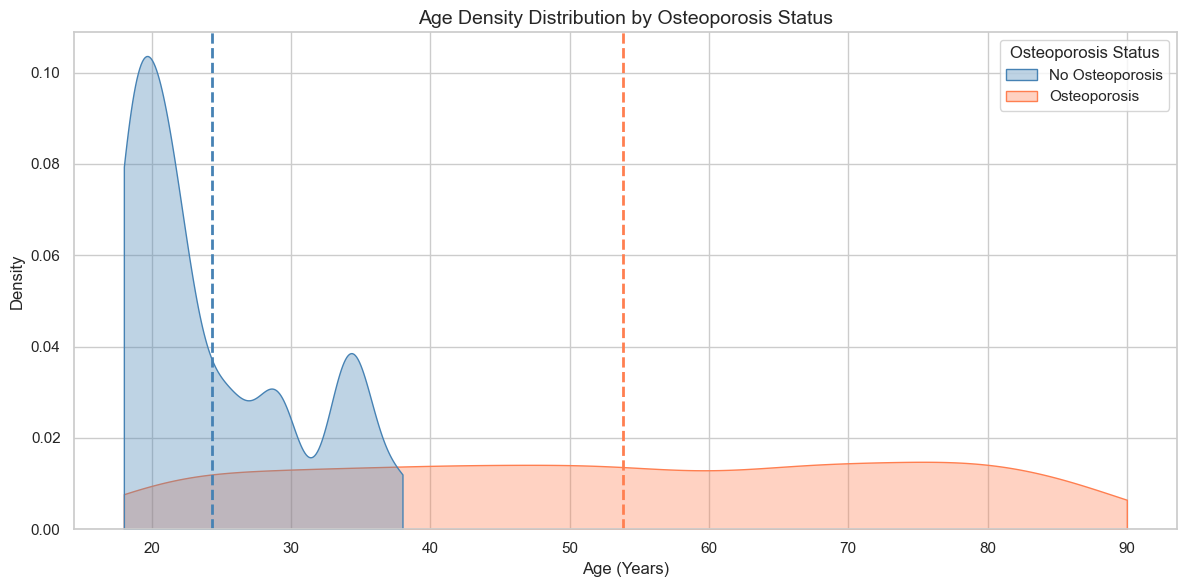

In [43]:
# AGE DISTRIBUTION BY OSTEOPOROSIS STATUS (KDE plot)

plt.figure(figsize=(12, 6))

sns.kdeplot(
    data=df_eda,
    x="Age",
    hue="Osteoporosis Status",
    hue_order=status_order,
    palette=class_palette,
    fill=True,
    alpha=0.35,
    common_norm=False,
    cut=0
)

for status in status_order:

    mean_value = df_eda.loc[
        df_eda["Osteoporosis Status"] == status,
        "Age"
    ].mean()

    plt.axvline(
        mean_value,
        color=class_palette[status],
        linestyle="--",
        linewidth=2
    )

plt.xlabel("Age (Years)")
plt.ylabel("Density")
plt.title("Age Density Distribution by Osteoporosis Status")

plt.tight_layout()
plt.show()

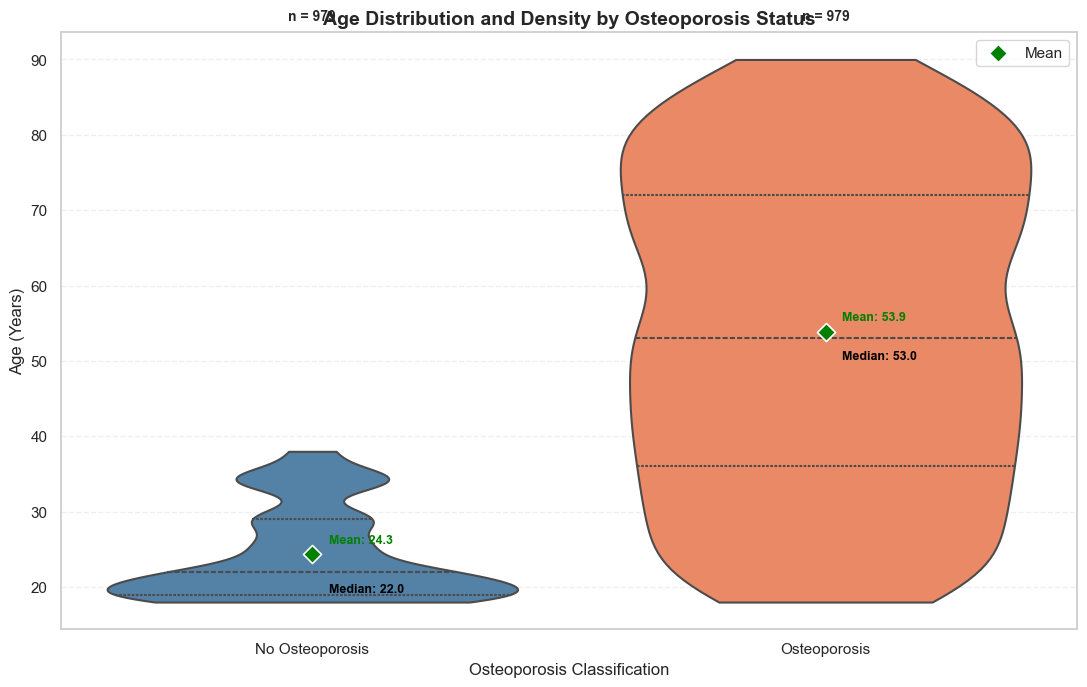

In [44]:
# AGE VS OSTEOPOROSIS -VIOLIN PLOT

plt.figure(figsize=(11, 7))

ax = sns.violinplot(
    data=df_eda,
    x="Osteoporosis Status",
    y="Age",
    hue="Osteoporosis Status",
    order=status_order,
    palette=class_palette,
    legend=False,
    inner="quartile",
    cut=0,
    linewidth=1.5
)


# Add mean, median and sample size
for i, status in enumerate(status_order):

    group = df_eda.loc[
        df_eda["Osteoporosis Status"] == status,
        "Age"
    ].dropna()

    mean_age = group.mean()
    median_age = group.median()
    count = group.count()

    # Mean marker
    ax.scatter(
        i,
        mean_age,
        color="green",
        marker="D",
        s=85,
        edgecolor="white",
        linewidth=1.2,
        zorder=5,
        label="Mean" if i == 0 else ""
    )

    # Mean label
    ax.annotate(
        f"Mean: {mean_age:.1f}",
        (i, mean_age),
        xytext=(12, 8),
        textcoords="offset points",
        color="green",
        fontsize=9,
        fontweight="bold"
    )

    # Median label
    ax.annotate(
        f"Median: {median_age:.1f}",
        (i, median_age),
        xytext=(12, -15),
        textcoords="offset points",
        color="black",
        fontsize=9,
        fontweight="bold"
    )

    # Sample count
    ax.text(
        i,
        1.02,
        f"n = {count}",
        transform=ax.get_xaxis_transform(),
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

plt.xlabel("Osteoporosis Classification", fontsize=12)
plt.ylabel("Age (Years)", fontsize=12)

plt.title(
    "Age Distribution and Density by Osteoporosis Status",
    fontsize=14,
    fontweight="bold"
)

plt.legend(loc="upper right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


In [45]:
# AGE GROUP VS OSTEOPOROSIS - SUMMARY

age_risk_summary = pd.crosstab(
    df_eda["Age Group"],
    df_eda[target]
).reindex(
    index=age_labels,
    columns=[0, 1],
    fill_value=0
)

age_risk_summary.columns = [
    "No Osteoporosis",
    "Osteoporosis"
]

age_risk_summary["Total"] = (
    age_risk_summary["No Osteoporosis"] +
    age_risk_summary["Osteoporosis"]
)

age_risk_summary["Osteoporosis (%)"] = (
    age_risk_summary["Osteoporosis"] /
    age_risk_summary["Total"] * 100
)

display(age_risk_summary.round(2))

,No Osteoporosis,Osteoporosis,Total,Osteoporosis (%)
Age Group,,,,
18-29,794,157,951,16.5100
30-39,185,129,314,41.0800
40-49,0,138,138,100.0000
50-59,0,140,140,100.0000
60-69,0,135,135,100.0000
70+,0,280,280,100.0000


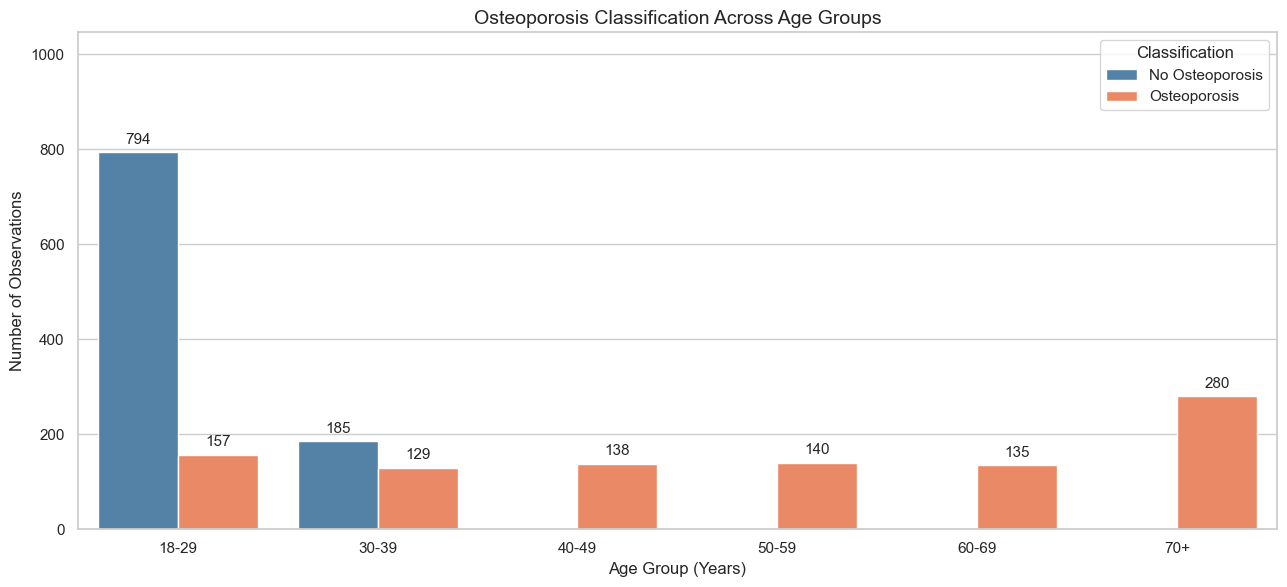

In [46]:
# AGE GROUP VS OSTEOPOROSIS - GROUPED BAR PLOT

plt.figure(figsize=(13, 6))

ax = sns.countplot(
    data=df_eda,
    x="Age Group",
    hue="Osteoporosis Status",
    order=age_labels,
    hue_order=status_order,
    palette=class_palette
)

for container in ax.containers:
    ax.bar_label(container, padding=4, fmt="%.0f")

plt.xlabel("Age Group (Years)")
plt.ylabel("Number of Observations")
plt.title("Osteoporosis Classification Across Age Groups")
plt.legend(title="Classification")

plt.ylim(0, age_risk_summary["Total"].max() * 1.1)

plt.tight_layout()
plt.show()

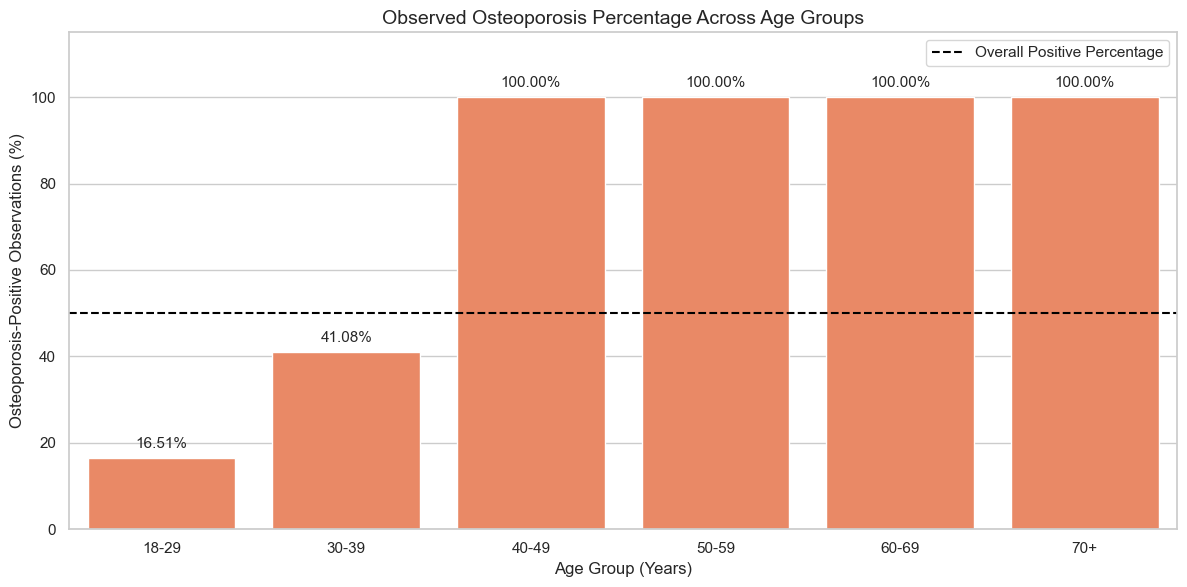

In [47]:
# OSTEOPOROSIS POSITIVE PERCENTAGE BY AGE GROUP

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=age_risk_summary.reset_index(),
    x="Age Group",
    y="Osteoporosis (%)",
    color="coral"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=5
    )

plt.axhline(
    df[target].mean() * 100,
    color="black",
    linestyle="--",
    label="Overall Positive Percentage"
)

plt.xlabel("Age Group (Years)")
plt.ylabel("Osteoporosis-Positive Observations (%)")
plt.title("Observed Osteoporosis Percentage Across Age Groups")
plt.ylim(0, 115)
plt.legend()

plt.tight_layout()
plt.show()

In [48]:
# CATEGORICAL BIVARIATE ANALYSIS FUNCTION

def categorical_bivariate_analysis(data, column):

    plot_data = data.copy()

    # Represent actual missing values explicitly for EDA
    plot_data[column] = (
        plot_data[column]
        .astype("string")
        .fillna("Missing")
    )

    # Classification counts
    summary = pd.crosstab(
        plot_data[column],
        plot_data[target]
    ).reindex(columns=[0, 1], fill_value=0)

    summary.columns = [
        "No Osteoporosis",
        "Osteoporosis"
    ]

    summary["Total"] = (
        summary["No Osteoporosis"] +
        summary["Osteoporosis"]
    )

    summary["No Osteoporosis (%)"] = (
        summary["No Osteoporosis"] /
        summary["Total"] * 100
    )

    summary["Osteoporosis (%)"] = (
        summary["Osteoporosis"] /
        summary["Total"] * 100
    )

    summary = summary.sort_values(
        "Osteoporosis (%)",
        ascending=False
    )

    order = summary.index.tolist()

    print("=" * 70)
    print(f"BIVARIATE ANALYSIS: {column} VS OSTEOPOROSIS")
    print("=" * 70)

    display(summary.round(2))

    fig, axes = plt.subplots(
        1, 3,
        figsize=(21, 6)
    )

    # 1. GROUPED COUNT PLOT

    sns.countplot(
        data=plot_data,
        x=column,
        hue="Osteoporosis Status",
        order=order,
        hue_order=status_order,
        palette=class_palette,
        ax=axes[0]
    )

    for container in axes[0].containers:
        axes[0].bar_label(
            container,
            padding=4,
            fmt="%.0f"
        )

    axes[0].set_title("Classification Counts")
    axes[0].set_xlabel(column)
    axes[0].set_ylabel("Number of Observations")
    axes[0].tick_params(axis="x", rotation=20)
    axes[0].margins(y=0.15)

    # 2. PERCENTAGE STACKED BAR PLOT

    percentage_data = summary[[
        "No Osteoporosis (%)",
        "Osteoporosis (%)"
    ]]

    percentage_data.plot(
        kind="bar",
        stacked=True,
        color=["steelblue", "coral"],
        ax=axes[1],
        width=0.65
    )

    for container in axes[1].containers:

        labels = [
            f"{bar.get_height():.1f}%"
            if bar.get_height() > 0 else ""
            for bar in container
        ]

        axes[1].bar_label(
            container,
            labels=labels,
            label_type="center",
            fontsize=10
        )

    axes[1].set_title("Classification Proportions")
    axes[1].set_xlabel(column)
    axes[1].set_ylabel("Percentage (%)")
    axes[1].set_ylim(0, 100)
    axes[1].tick_params(axis="x", rotation=20)

    axes[1].legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18)
    )

    # 3. POSITIVE CLASS PERCENTAGE

    sns.barplot(
        data=summary.reset_index(),
        x=column,
        y="Osteoporosis (%)",
        order=order,
        color="coral",
        ax=axes[2]
    )

    for container in axes[2].containers:
        axes[2].bar_label(
            container,
            fmt="%.2f%%",
            padding=5
        )

    axes[2].axhline(
        data[target].mean() * 100,
        color="black",
        linestyle="--",
        label="Overall Positive Percentage"
    )

    axes[2].set_title("Osteoporosis-Positive Percentage")
    axes[2].set_xlabel(column)
    axes[2].set_ylabel("Positive Observations (%)")
    axes[2].set_ylim(0, 115)
    axes[2].tick_params(axis="x", rotation=20)
    axes[2].legend()

    fig.suptitle(
        f"{column} vs Osteoporosis Classification",
        fontsize=18,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

    return summary

BIVARIATE ANALYSIS: Gender VS OSTEOPOROSIS


,No Osteoporosis,Osteoporosis,Total,No Osteoporosis (%),Osteoporosis (%)
Gender,,,,,
Male,490,502,992,49.4000,50.6000
Female,489,477,966,50.6200,49.3800


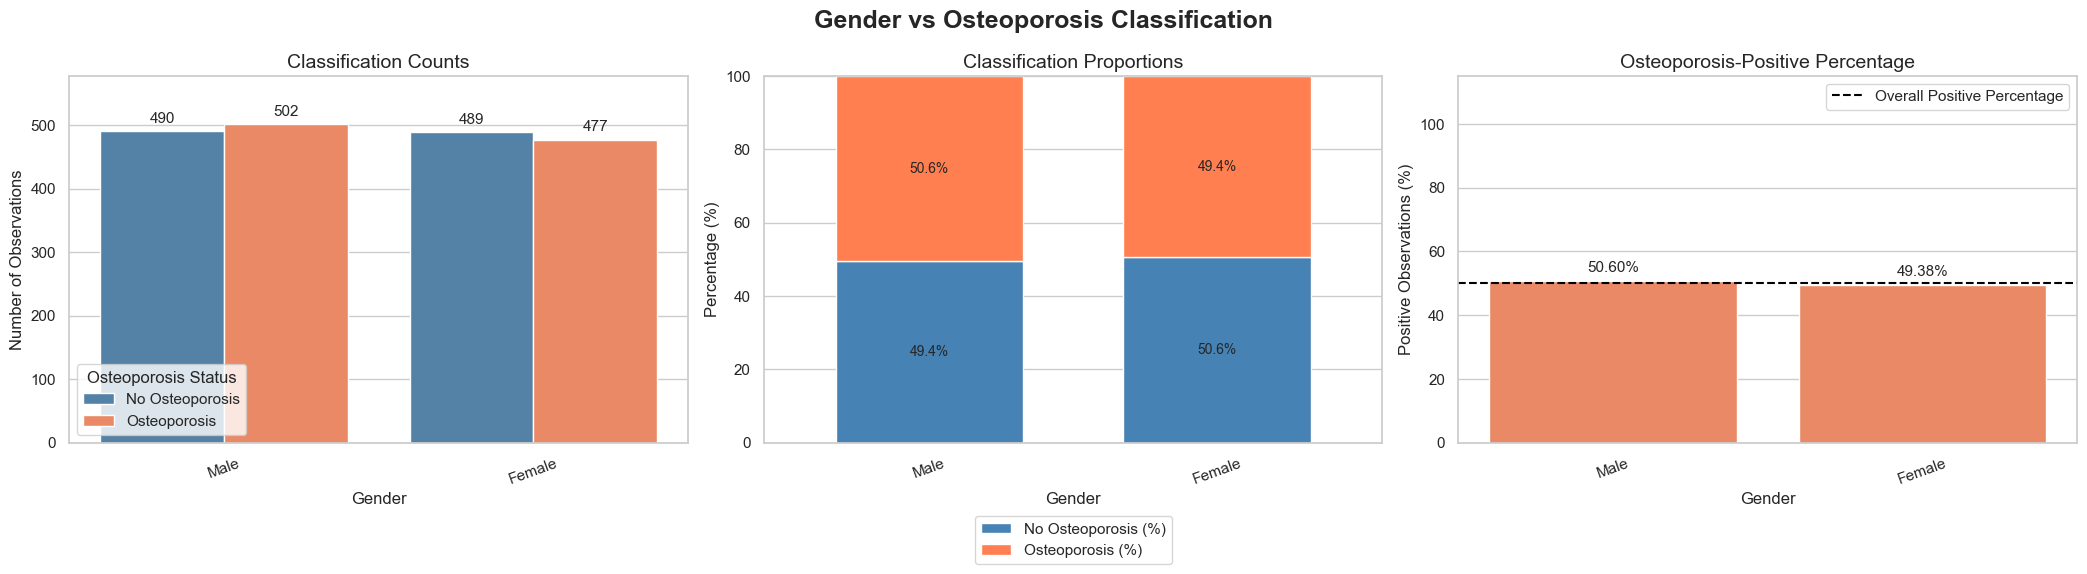

BIVARIATE ANALYSIS: Hormonal Changes VS OSTEOPOROSIS


,No Osteoporosis,Osteoporosis,Total,No Osteoporosis (%),Osteoporosis (%)
Hormonal Changes,,,,,
Postmenopausal,481,496,977,49.2300,50.7700
Normal,498,483,981,50.7600,49.2400


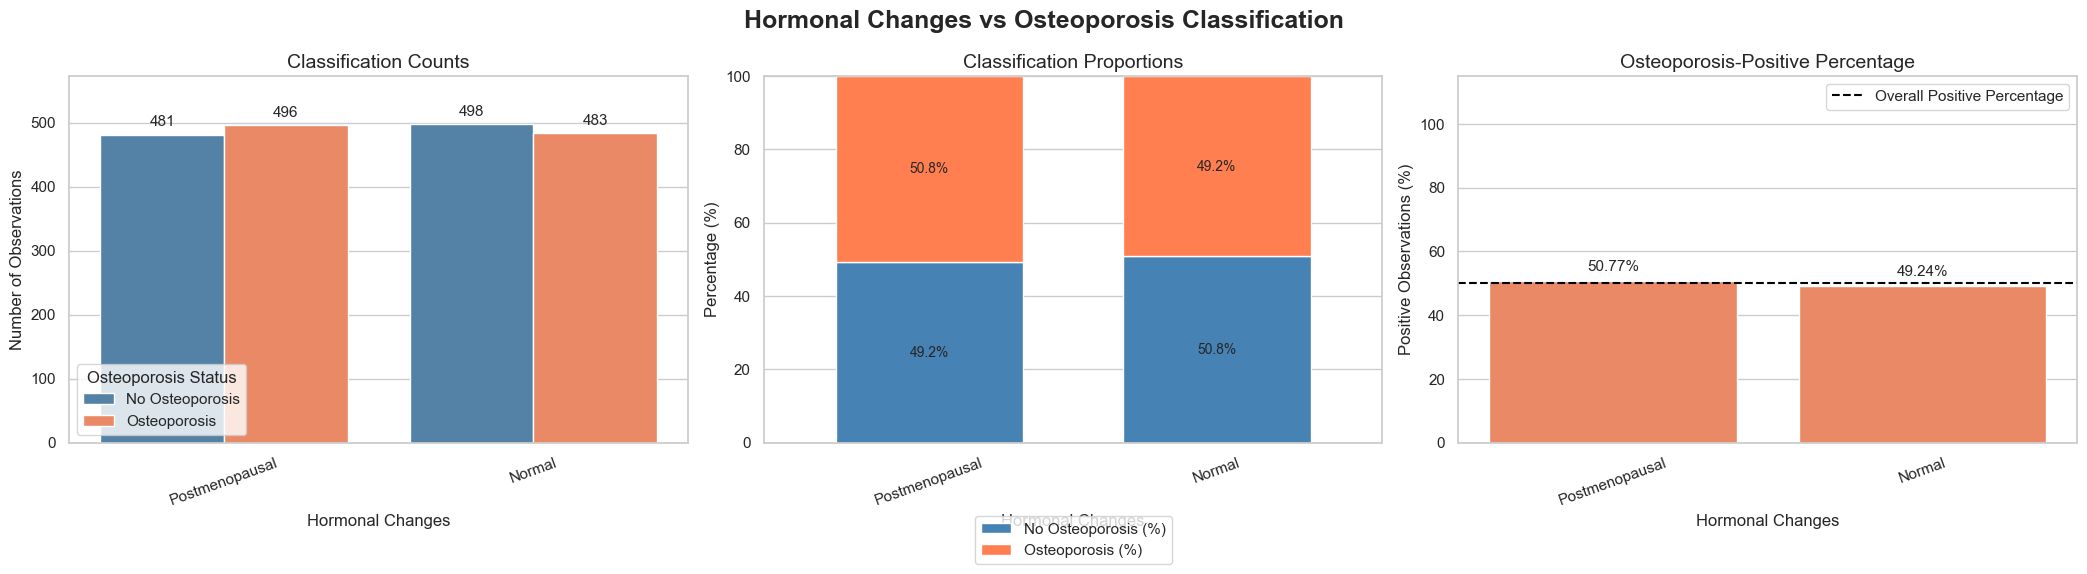

BIVARIATE ANALYSIS: Family History VS OSTEOPOROSIS


,No Osteoporosis,Osteoporosis,Total,No Osteoporosis (%),Osteoporosis (%)
Family History,,,,,
No,498,500,998,49.9000,50.1000
Yes,481,479,960,50.1000,49.9000


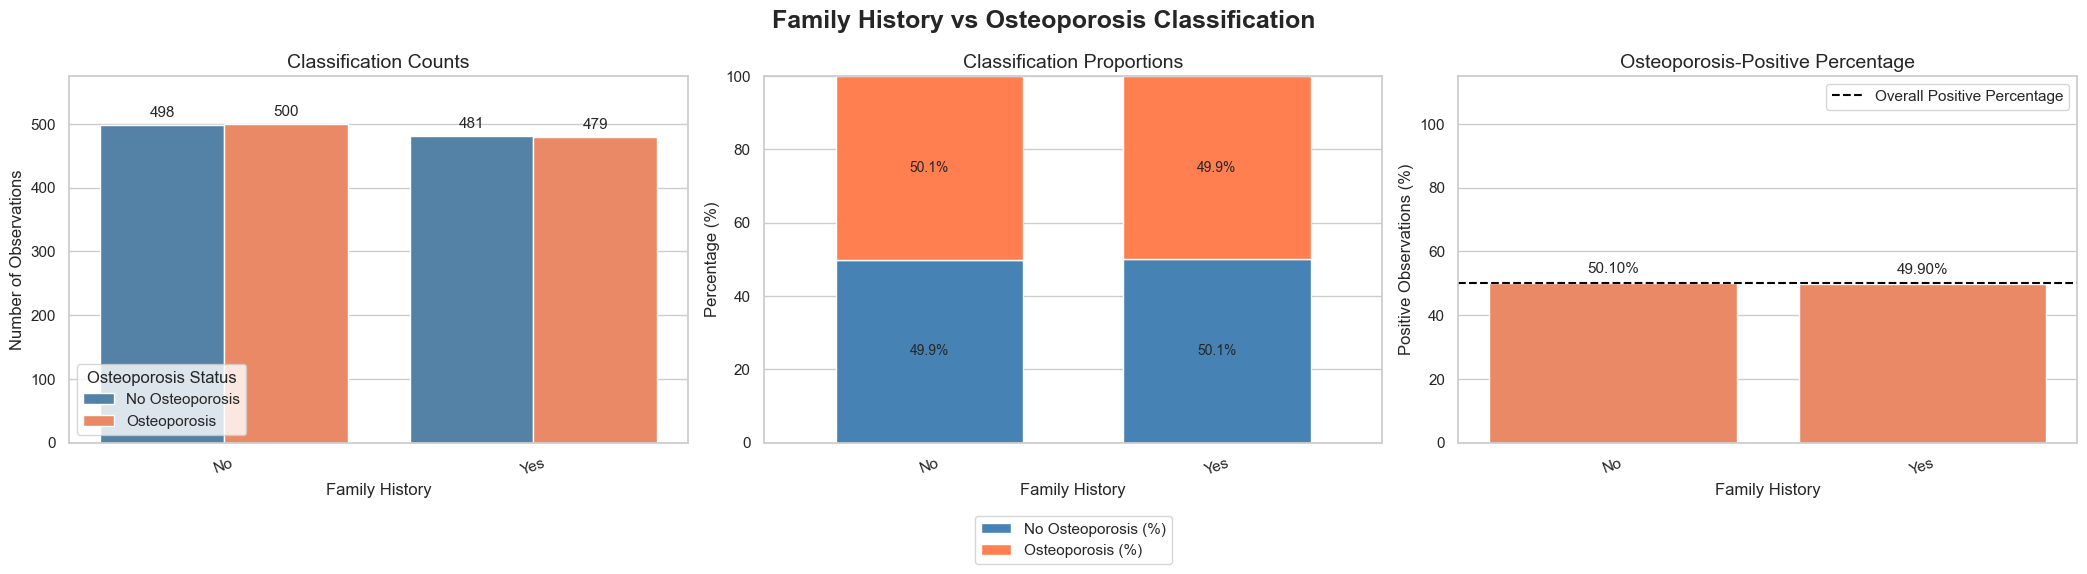

BIVARIATE ANALYSIS: Race/Ethnicity VS OSTEOPOROSIS


,No Osteoporosis,Osteoporosis,Total,No Osteoporosis (%),Osteoporosis (%)
Race/Ethnicity,,,,,
African American,337,344,681,49.4900,50.5100
Asian,317,314,631,50.2400,49.7600
Caucasian,325,321,646,50.3100,49.6900


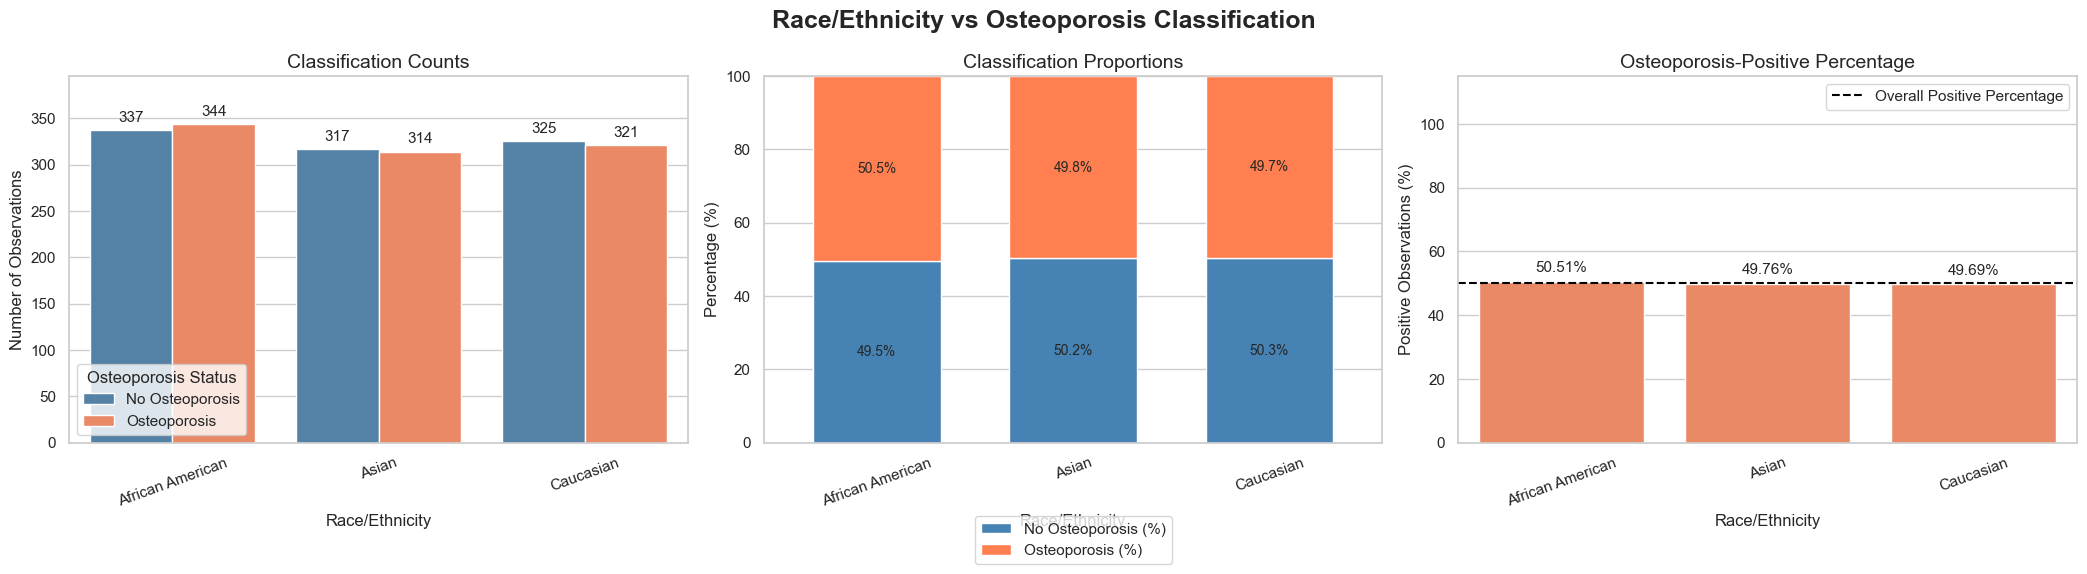

BIVARIATE ANALYSIS: Body Weight VS OSTEOPOROSIS


,No Osteoporosis,Osteoporosis,Total,No Osteoporosis (%),Osteoporosis (%)
Body Weight,,,,,
Underweight,448,483,931,48.1200,51.8800
Normal,531,496,1027,51.7000,48.3000


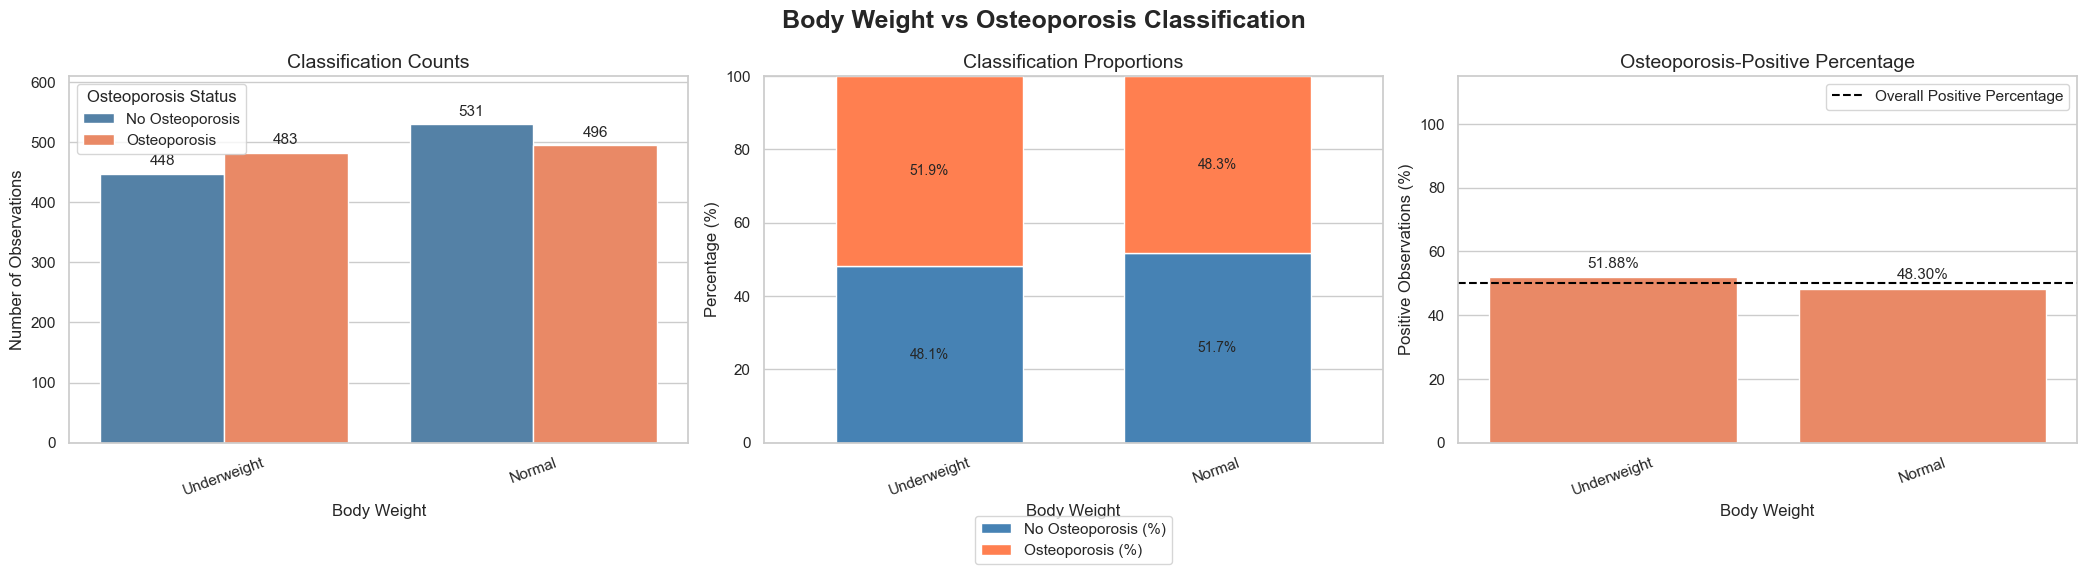

BIVARIATE ANALYSIS: Calcium Intake VS OSTEOPOROSIS


,No Osteoporosis,Osteoporosis,Total,No Osteoporosis (%),Osteoporosis (%)
Calcium Intake,,,,,
Adequate,475,479,954,49.7900,50.2100
Low,504,500,1004,50.2000,49.8000


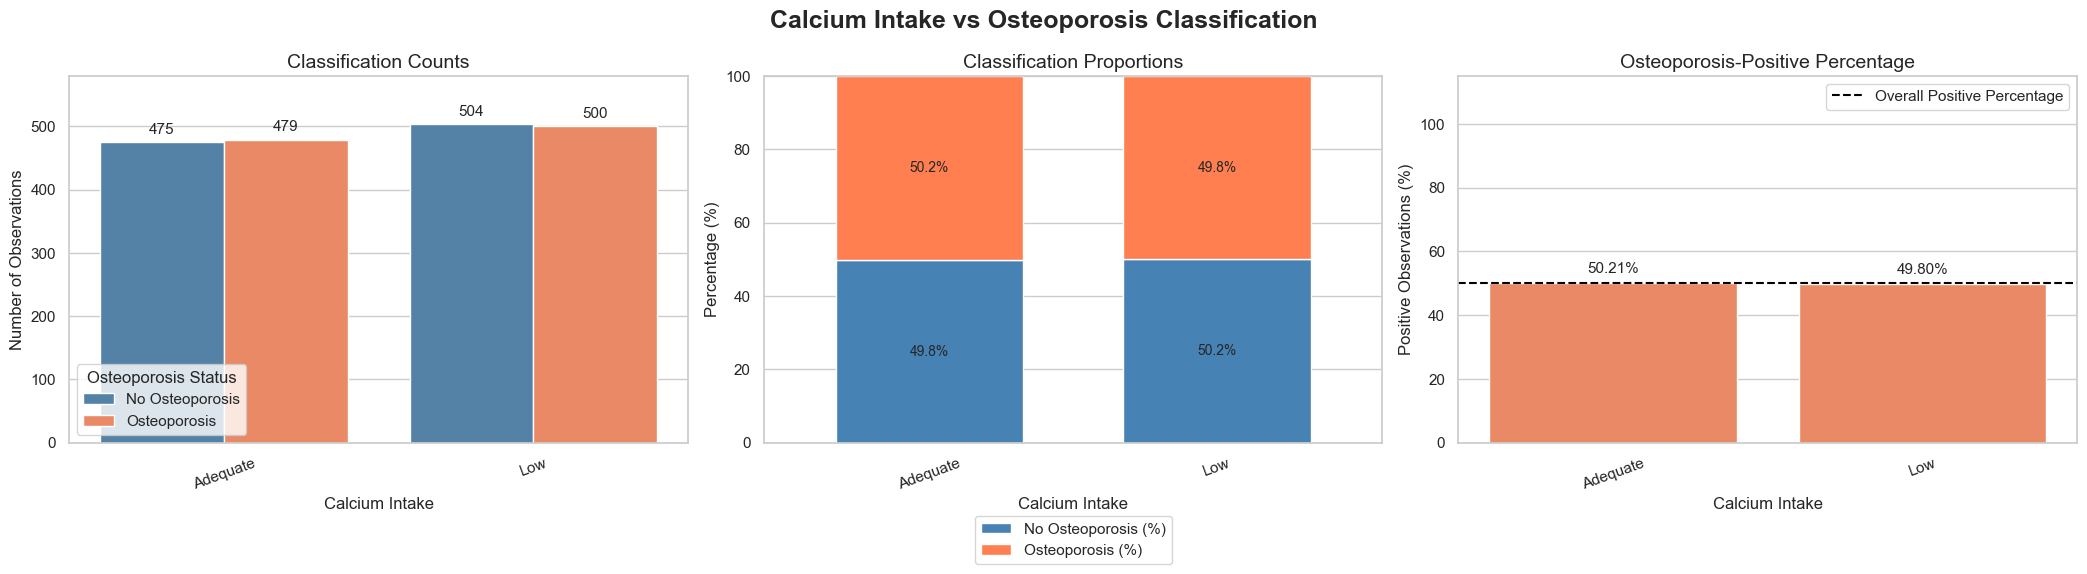

BIVARIATE ANALYSIS: Vitamin D Intake VS OSTEOPOROSIS


,No Osteoporosis,Osteoporosis,Total,No Osteoporosis (%),Osteoporosis (%)
Vitamin D Intake,,,,,
Sufficient,497,514,1011,49.1600,50.8400
Insufficient,482,465,947,50.9000,49.1000


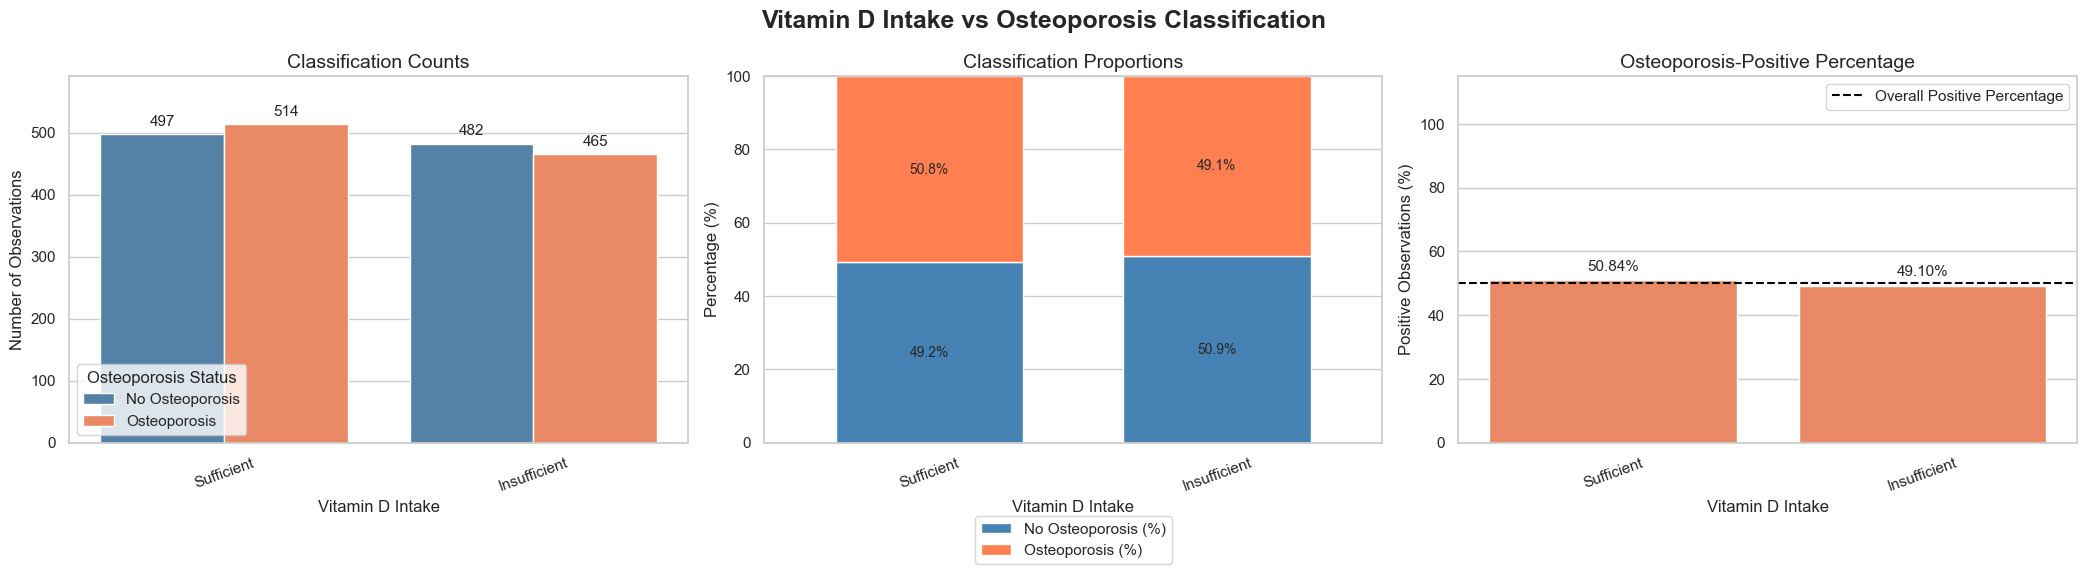

BIVARIATE ANALYSIS: Physical Activity VS OSTEOPOROSIS


,No Osteoporosis,Osteoporosis,Total,No Osteoporosis (%),Osteoporosis (%)
Physical Activity,,,,,
Sedentary,459,478,937,48.9900,51.0100
Active,520,501,1021,50.9300,49.0700


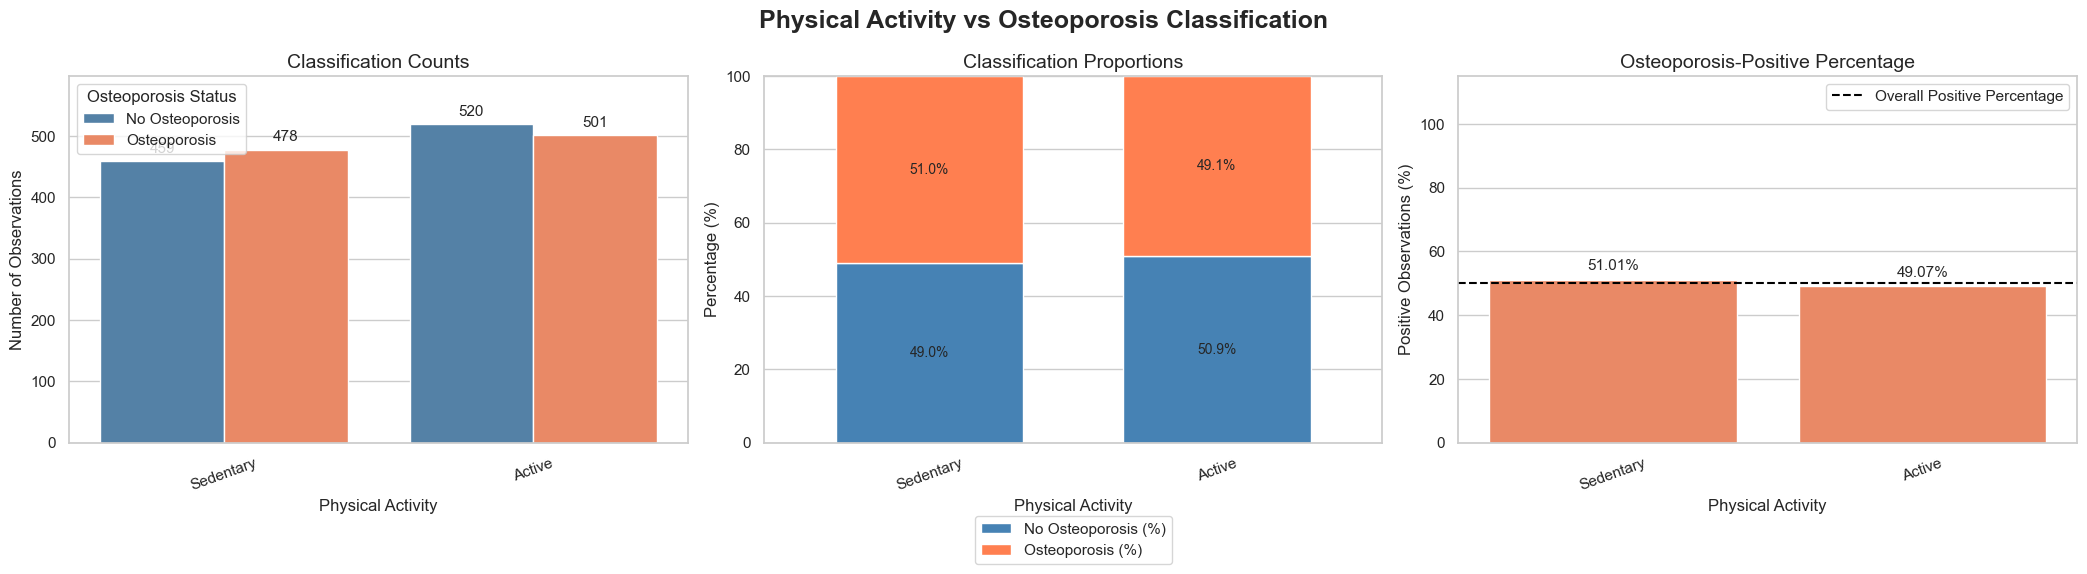

BIVARIATE ANALYSIS: Smoking VS OSTEOPOROSIS


,No Osteoporosis,Osteoporosis,Total,No Osteoporosis (%),Osteoporosis (%)
Smoking,,,,,
No,480,496,976,49.1800,50.8200
Yes,499,483,982,50.8100,49.1900


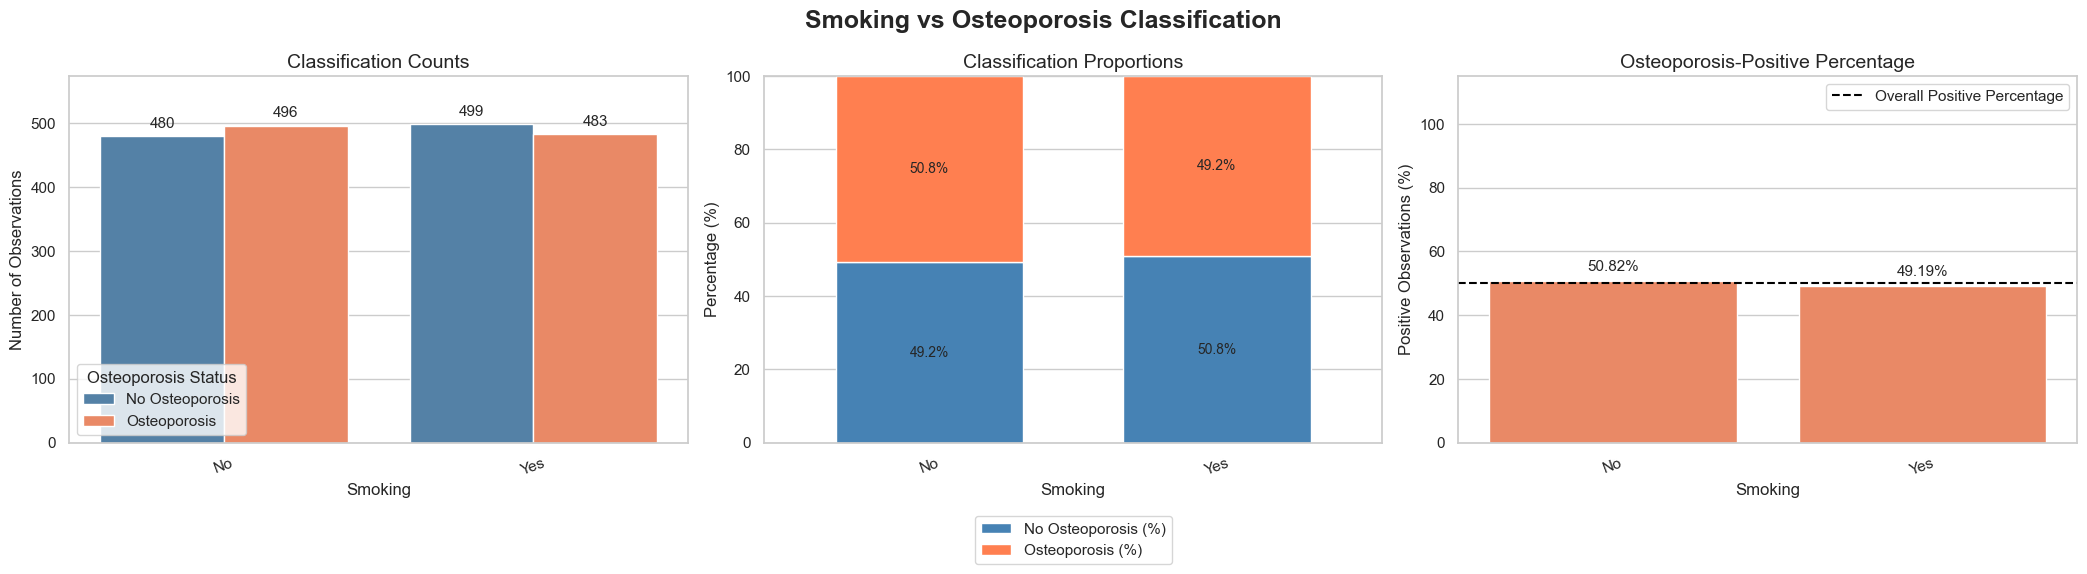

BIVARIATE ANALYSIS: Alcohol Consumption VS OSTEOPOROSIS


,No Osteoporosis,Osteoporosis,Total,No Osteoporosis (%),Osteoporosis (%)
Alcohol Consumption,,,,,
Moderate,484,486,970,49.9000,50.1000
None,495,493,988,50.1000,49.9000


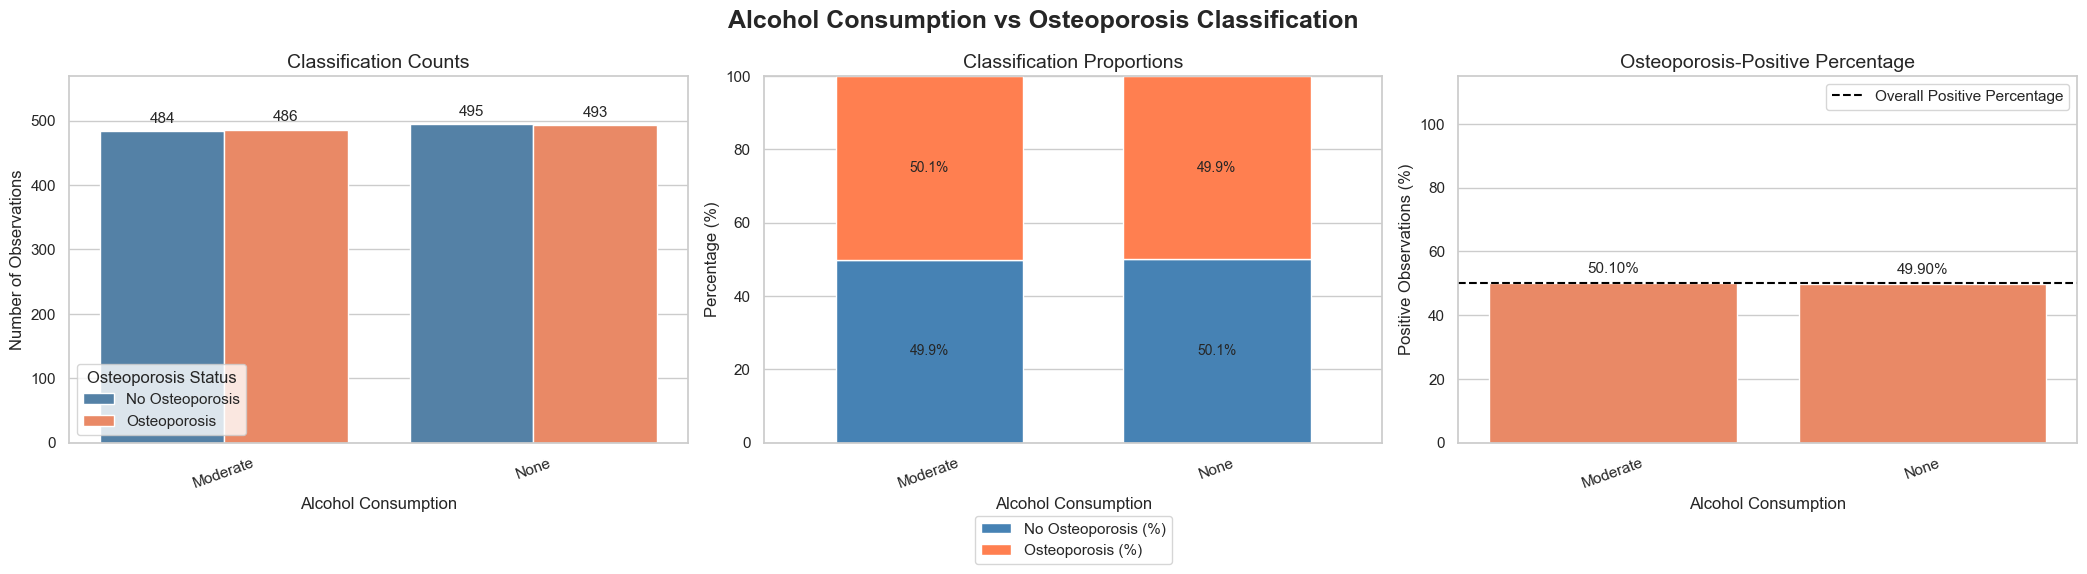

BIVARIATE ANALYSIS: Medical Conditions VS OSTEOPOROSIS


,No Osteoporosis,Osteoporosis,Total,No Osteoporosis (%),Osteoporosis (%)
Medical Conditions,,,,,
Hyperthyroidism,335,343,678,49.4100,50.5900
Rheumatoid Arthritis,315,318,633,49.7600,50.2400
None,329,318,647,50.8500,49.1500


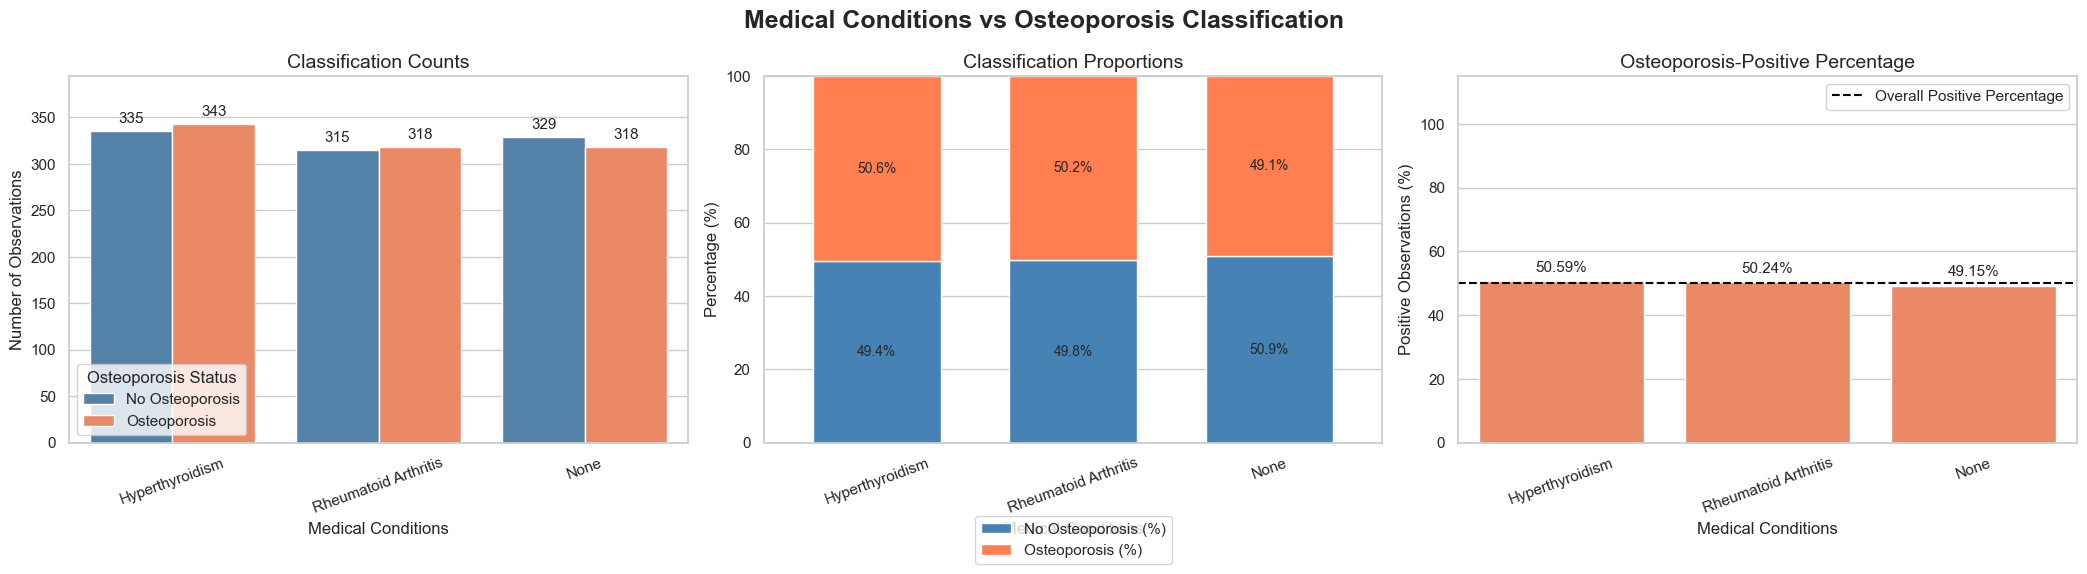

BIVARIATE ANALYSIS: Medications VS OSTEOPOROSIS


,No Osteoporosis,Osteoporosis,Total,No Osteoporosis (%),Osteoporosis (%)
Medications,,,,,
Corticosteroids,470,503,973,48.3000,51.7000
None,509,476,985,51.6800,48.3200


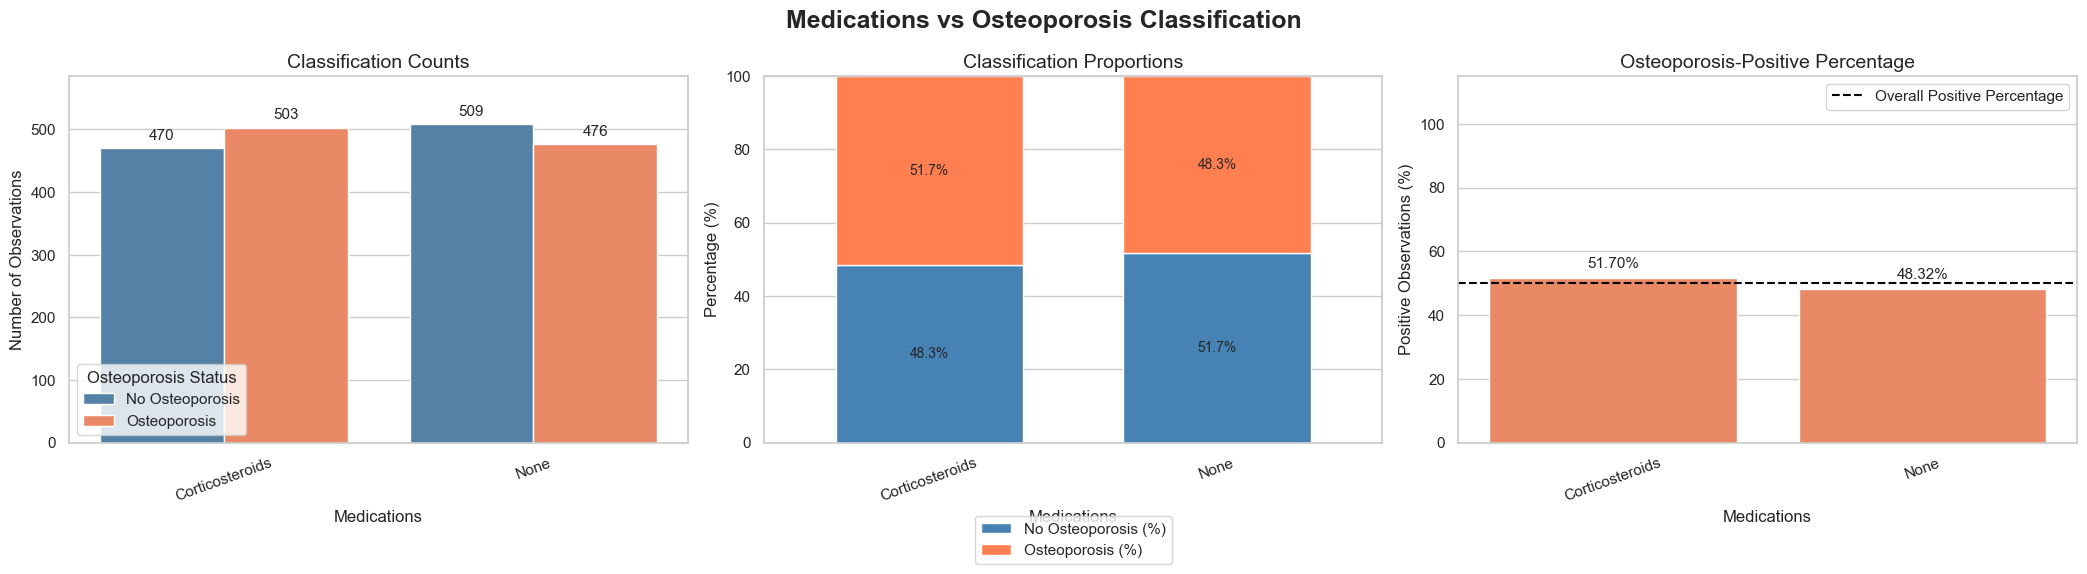

BIVARIATE ANALYSIS: Prior Fractures VS OSTEOPOROSIS


,No Osteoporosis,Osteoporosis,Total,No Osteoporosis (%),Osteoporosis (%)
Prior Fractures,,,,,
Yes,484,499,983,49.2400,50.7600
No,495,480,975,50.7700,49.2300


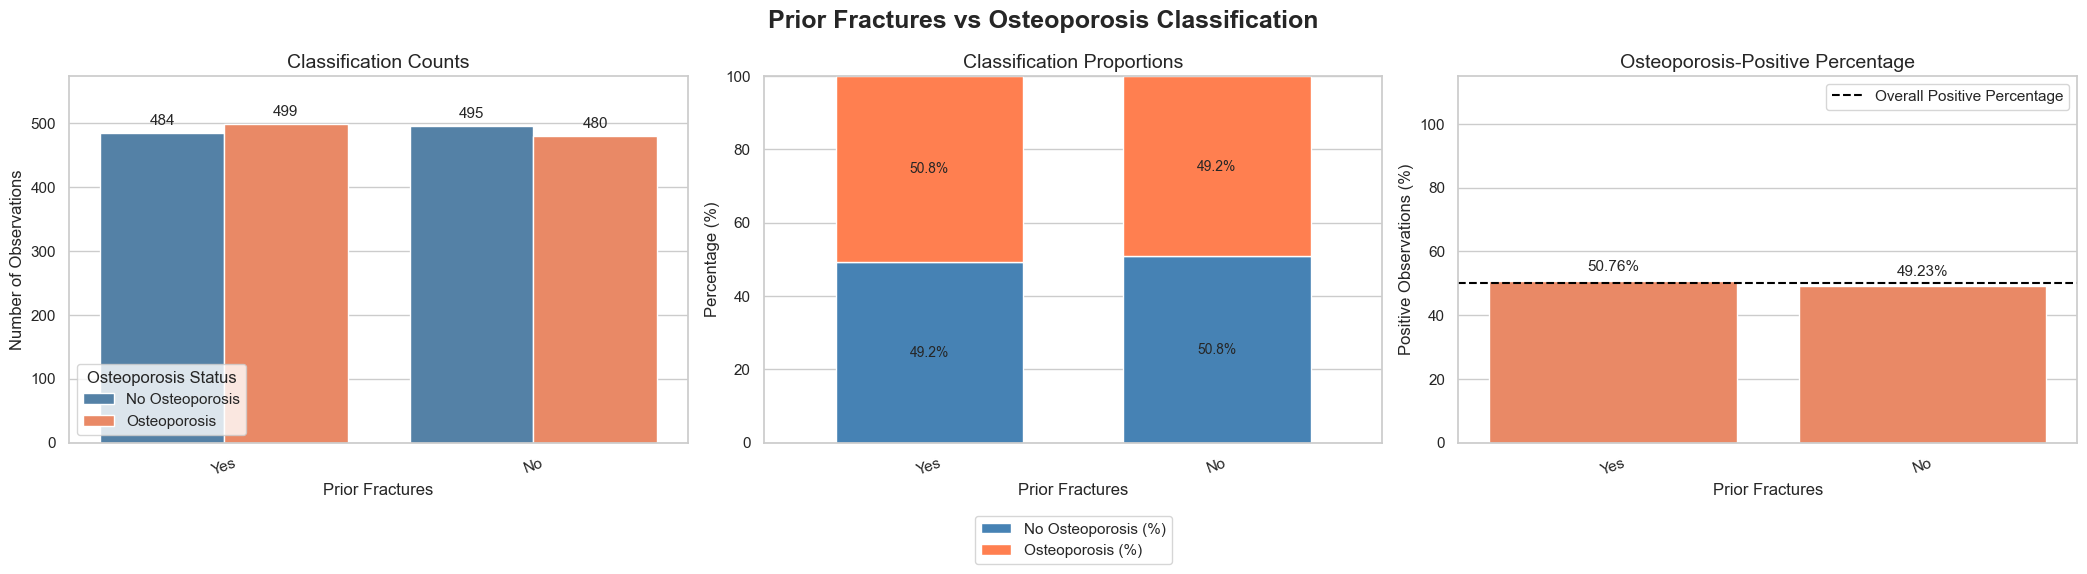

In [49]:
# BIVARIATE ANALYSIS OF ALL CATEGORICAL FEATURES

bivariate_results = {}

for col in categorical_cols:

    bivariate_results[col] = (
        categorical_bivariate_analysis(
            data=df_eda,
            column=col
        )
    )

In [50]:
display(bivariate_results["Smoking"])

display(bivariate_results["Calcium Intake"])

display(bivariate_results["Family History"])

,No Osteoporosis,Osteoporosis,Total,No Osteoporosis (%),Osteoporosis (%)
Smoking,,,,,
No,480,496,976,49.1803,50.8197
Yes,499,483,982,50.8147,49.1853


,No Osteoporosis,Osteoporosis,Total,No Osteoporosis (%),Osteoporosis (%)
Calcium Intake,,,,,
Adequate,475,479,954,49.7904,50.2096
Low,504,500,1004,50.1992,49.8008


,No Osteoporosis,Osteoporosis,Total,No Osteoporosis (%),Osteoporosis (%)
Family History,,,,,
No,498,500,998,49.8998,50.1002
Yes,481,479,960,50.1042,49.8958


In [51]:
# CATEGORICAL FEATURE ASSOCIATION SUMMARY

association_results = []

for col, summary in bivariate_results.items():

    max_category = summary["Osteoporosis (%)"].idxmax()
    min_category = summary["Osteoporosis (%)"].idxmin()

    max_percentage = summary["Osteoporosis (%)"].max()
    min_percentage = summary["Osteoporosis (%)"].min()

    association_results.append({

        "Feature": col,

        "Highest Positive Category": max_category,

        "Highest Positive (%)": max_percentage,

        "Lowest Positive Category": min_category,

        "Lowest Positive (%)": min_percentage,

        "Percentage Point Difference": (
            max_percentage - min_percentage
        )

    })

association_summary = pd.DataFrame(
    association_results
).sort_values(
    "Percentage Point Difference",
    ascending=False
).reset_index(drop=True)

display(association_summary.round(2))

,Feature,Highest Positive Category,Highest Positive (%),Lowest Positive Category,Lowest Positive (%),Percentage Point Difference
0,Body Weight,Underweight,51.8800,Normal,48.3000,3.5800
1,Medications,Corticosteroids,51.7000,None,48.3200,3.3700
2,Physical Activity,Sedentary,51.0100,Active,49.0700,1.9400
3,Vitamin D Intake,Sufficient,50.8400,Insufficient,49.1000,1.7400
4,Smoking,No,50.8200,Yes,49.1900,1.6300
5,Prior Fractures,Yes,50.7600,No,49.2300,1.5300
6,Hormonal Changes,Postmenopausal,50.7700,Normal,49.2400,1.5300
7,Medical Conditions,Hyperthyroidism,50.5900,None,49.1500,1.4400
8,Gender,Male,50.6000,Female,49.3800,1.2300
9,Race/Ethnicity,African American,50.5100,Caucasian,49.6900,0.8200


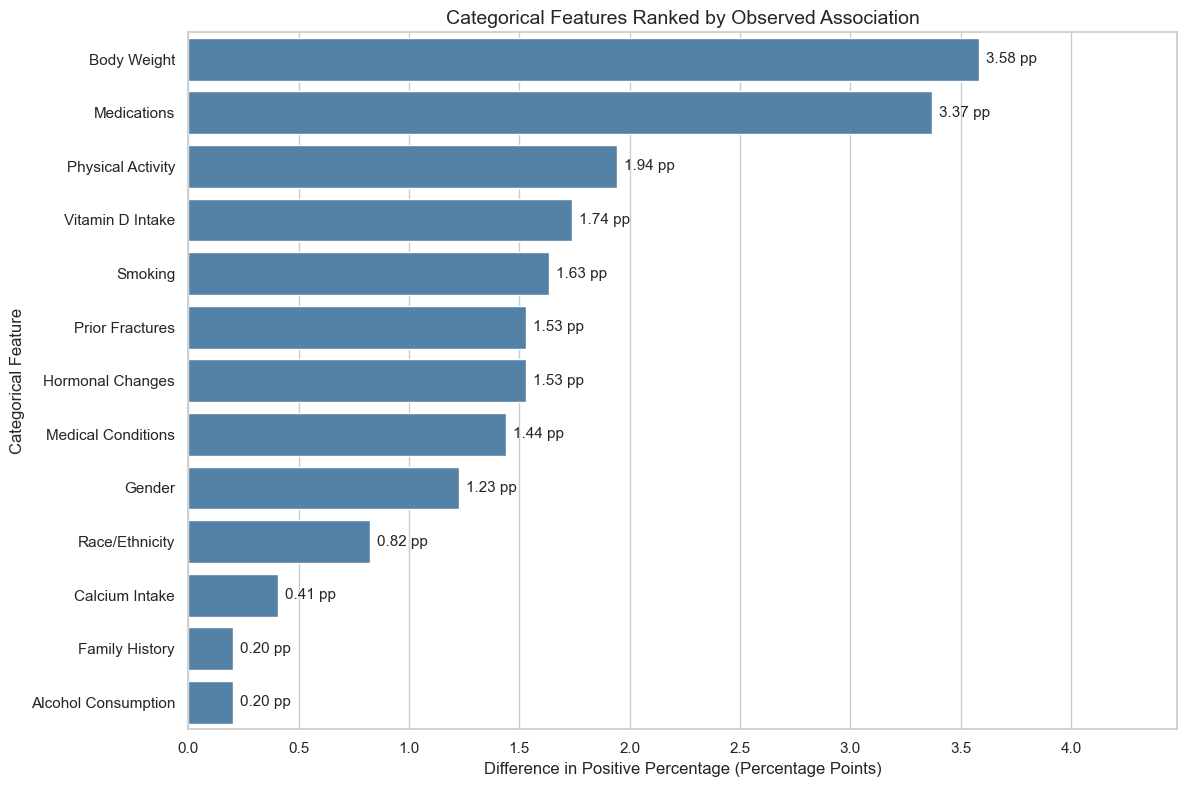

In [52]:
# CATEGORICAL FEATURE ASSOCIATION RANKING

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=association_summary,
    x="Percentage Point Difference",
    y="Feature",
    color="steelblue"
)

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.2f pp",
        padding=5
    )

plt.xlim(
    0,
    max(
        1,
        association_summary[
            "Percentage Point Difference"
        ].max() * 1.25
    )
)

plt.xlabel("Difference in Positive Percentage (Percentage Points)")
plt.ylabel("Categorical Feature")
plt.title("Categorical Features Ranked by Observed Association")

plt.tight_layout()
plt.show()

### Multivariate analysis

In [53]:
# AGE, GENDER AND OSTEOPOROSIS - STATISTICAL SUMMARY

age_gender_summary = df_eda.groupby(
    ["Gender", "Osteoporosis Status"],
    observed=True
)["Age"].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Std_Dev="std",
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75),
    Min="min",
    Max="max"
)

display(age_gender_summary.round(2))


Count    Mean  Median  Std_Dev      Q1      Q3  \
Gender Osteoporosis Status                                                   
Female No Osteoporosis        489 24.2200 22.0000   5.9600 19.0000 29.0000   
       Osteoporosis           477 53.7000 54.0000  20.9000 36.0000 72.0000   
Male   No Osteoporosis        490 24.4700 22.0000   6.2600 19.0000 29.0000   
       Osteoporosis           502 54.0100 53.0000  21.0300 36.0000 73.0000   

                            Min  Max  
Gender Osteoporosis Status            
Female No Osteoporosis       18   38  
       Osteoporosis          18   90  
Male   No Osteoporosis       18   38  
       Osteoporosis          18   90

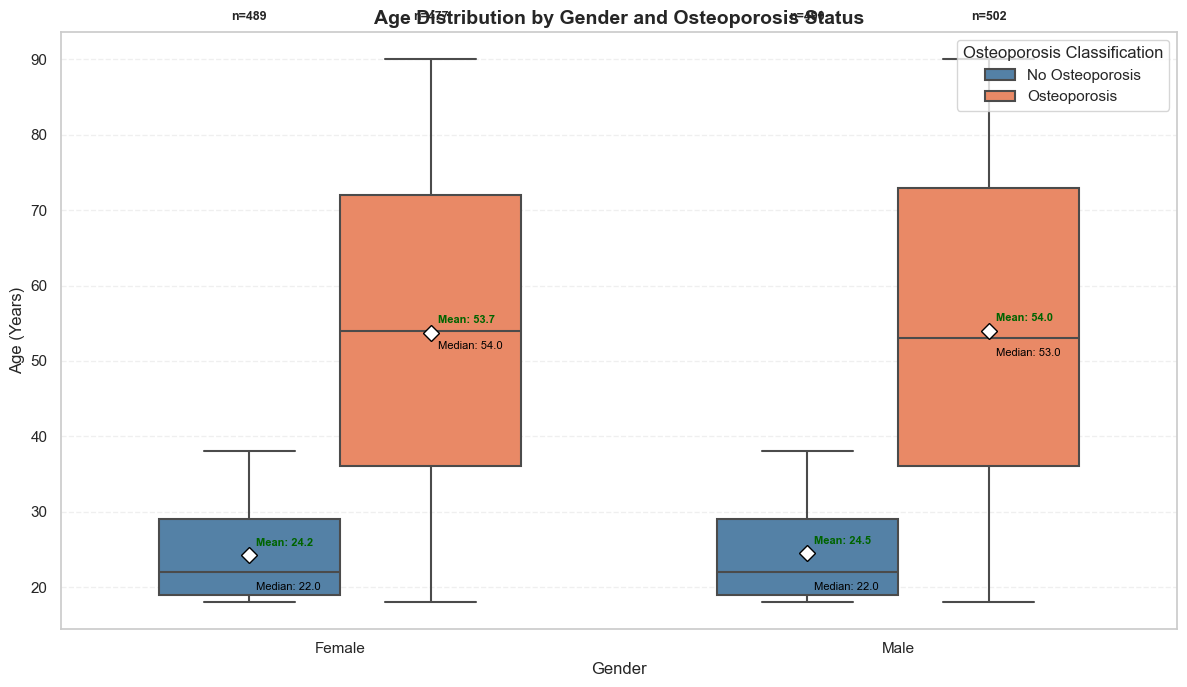

In [54]:
# AGE, GENDER AND OSTEOPOROSIS - ENHANCED BOXPLOT

plt.figure(figsize=(12, 7))

ax = sns.boxplot(
    data=df_eda,
    x="Gender",
    y="Age",
    hue="Osteoporosis Status",
    hue_order=status_order,
    palette=class_palette,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 8
    },
    width=0.65,
    linewidth=1.5
)



# Add mean, median and sample count labels
gender_order = list(df_eda["Gender"].dropna().unique())

for i, gender in enumerate(gender_order):

    for j, status in enumerate(status_order):

        group = df_eda.loc[
            (df_eda["Gender"] == gender) &
            (df_eda["Osteoporosis Status"] == status),
            "Age"
        ].dropna()

        if group.empty:
            continue

        mean_age = group.mean()
        median_age = group.median()
        count = group.count()

        # Position according to grouped bar arrangement
        offset = (j - (len(status_order) - 1) / 2) * 0.325
        x_position = i + offset

        # Mean label
        ax.annotate(
            f"Mean: {mean_age:.1f}",
            (x_position, mean_age),
            xytext=(5, 7),
            textcoords="offset points",
            fontsize=8,
            color="darkgreen",
            fontweight="bold"
        )

        # Median label
        ax.annotate(
            f"Median: {median_age:.1f}",
            (x_position, median_age),
            xytext=(5, -13),
            textcoords="offset points",
            fontsize=8,
            color="black"
        )

        # Sample count
        ax.text(
            x_position,
            1.02,
            f"n={count}",
            transform=ax.get_xaxis_transform(),
            ha="center",
            fontsize=9,
            fontweight="bold"
        )

plt.xlabel("Gender", fontsize=12)
plt.ylabel("Age (Years)", fontsize=12)

plt.title(
    "Age Distribution by Gender and Osteoporosis Status",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    title="Osteoporosis Classification",
    loc="upper right"
)

plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


,Age Group,Gender,Total,Positive,Positive_Rate,Osteoporosis (%)
0,18-29,Female,486,81,0.1700,16.6700
1,18-29,Male,465,76,0.1600,16.3400
2,30-39,Female,139,55,0.4000,39.5700
3,30-39,Male,175,74,0.4200,42.2900
4,40-49,Female,69,69,1.0000,100.0000
5,40-49,Male,69,69,1.0000,100.0000
6,50-59,Female,73,73,1.0000,100.0000
7,50-59,Male,67,67,1.0000,100.0000
8,60-69,Female,65,65,1.0000,100.0000
9,60-69,Male,70,70,1.0000,100.0000


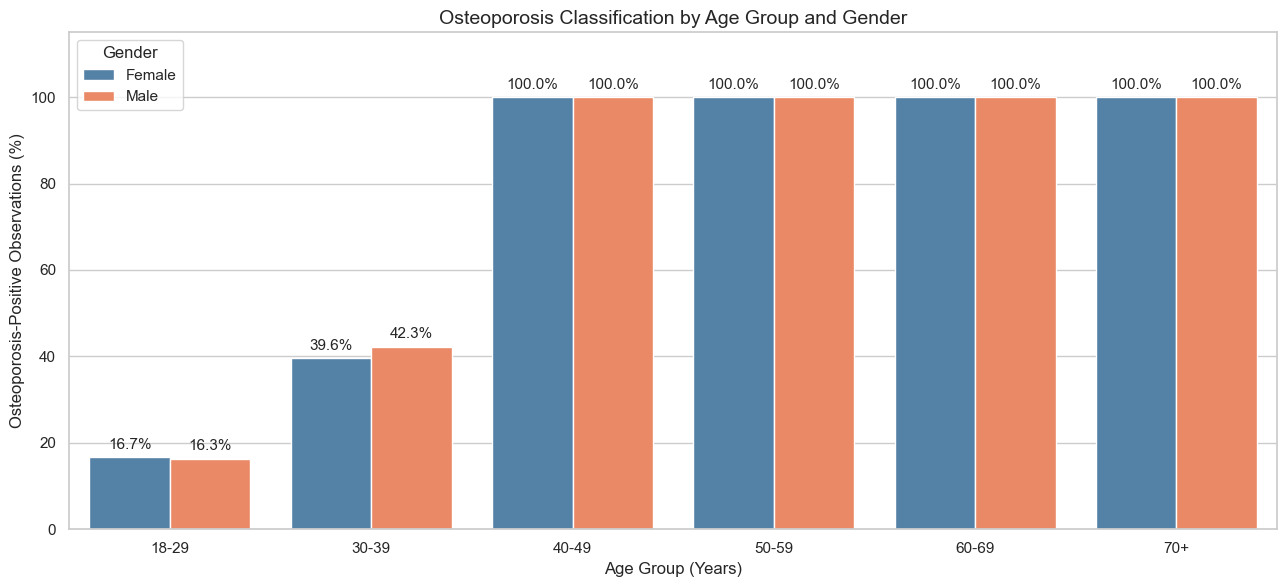

In [55]:
# AGE GROUP AND GENDER VS OSTEOPOROSIS

age_gender_risk = df_eda.groupby(
    ["Age Group", "Gender"],
    observed=True
)[target].agg(
    Total="size",
    Positive="sum",
    Positive_Rate="mean"
).reset_index()

age_gender_risk["Osteoporosis (%)"] = (
    age_gender_risk["Positive_Rate"] * 100
)

display(age_gender_risk.round(2))

plt.figure(figsize=(13, 6))

ax = sns.barplot(
    data=age_gender_risk,
    x="Age Group",
    y="Osteoporosis (%)",
    hue="Gender",
    order=age_labels,
    palette=["steelblue", "coral"]
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=4
    )

plt.xlabel("Age Group (Years)")
plt.ylabel("Osteoporosis-Positive Observations (%)")
plt.title("Osteoporosis Classification by Age Group and Gender")
plt.ylim(0, 115)

plt.tight_layout()
plt.show()

In [ ]:
# AGE AND HORMONAL CHANGES - STATISTICAL SUMMARY

hormonal_age_summary = df_eda.groupby(
    ["Gender", "Hormonal Changes"],
    observed=True
)["Age"].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Std_Dev="std",
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75),
    Min="min",
    Max="max"
)

display(hormonal_age_summary.round(2))


Count    Mean  Median  Std_Dev      Q1      Q3  Min  \
Gender Hormonal Changes                                                        
Female Normal              475 39.0700 30.0000  21.5100 21.0000 54.5000   18   
       Postmenopausal      491 38.4800 29.0000  20.9700 21.0000 51.5000   18   
Male   Normal              506 38.9000 32.0000  21.6000 21.0000 52.0000   18   
       Postmenopausal      486 39.9600 34.0000  21.3600 22.0000 56.0000   18   

                         Max  
Gender Hormonal Changes       
Female Normal             90  
       Postmenopausal     90  
Male   Normal             90  
       Postmenopausal     89

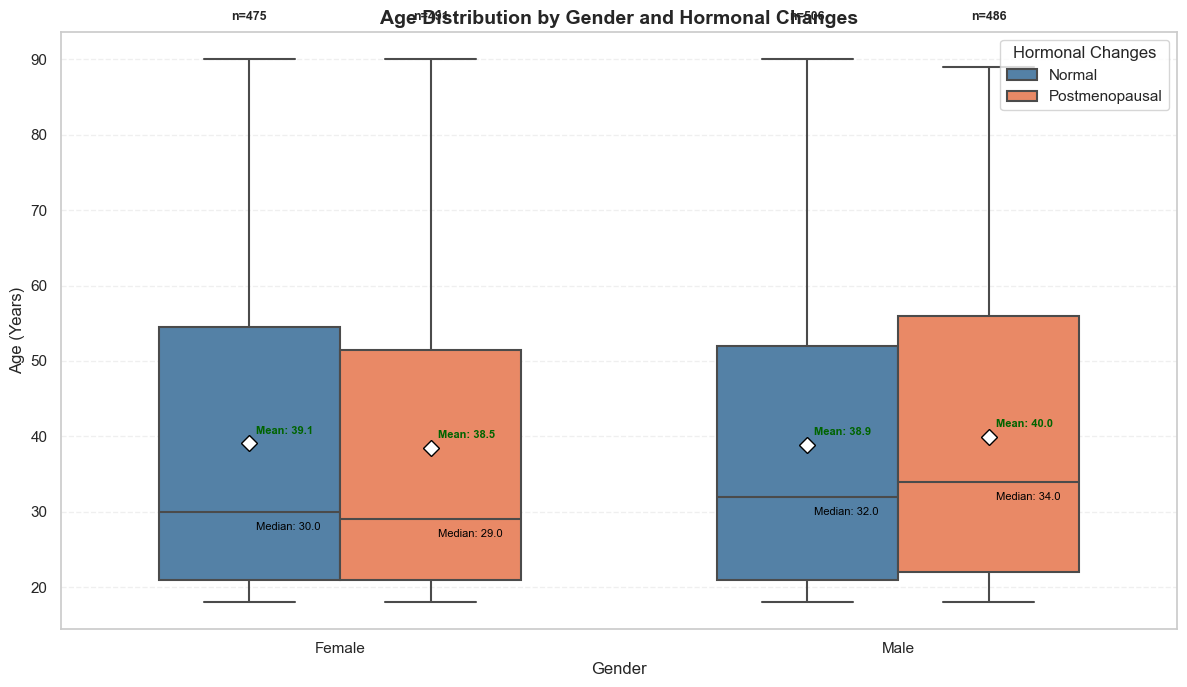

In [ ]:
# AGE AND HORMONAL CHANGES - ENHANCED BOXPLOT

plt.figure(figsize=(12, 7))

hormonal_order = list(
    df_eda["Hormonal Changes"].dropna().unique()
)

hormonal_palette = {
    hormonal_order[0]: "steelblue",
    hormonal_order[1]: "coral"
}

ax = sns.boxplot(
    data=df_eda,
    x="Gender",
    y="Age",
    hue="Hormonal Changes",
    hue_order=hormonal_order,
    palette=hormonal_palette,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 8
    },
    width=0.65,
    linewidth=1.5
)



# Add mean, median and sample count
gender_order = list(
    df_eda["Gender"].dropna().unique()
)

for i, gender in enumerate(gender_order):

    for j, hormonal_status in enumerate(hormonal_order):

        group = df_eda.loc[
            (df_eda["Gender"] == gender) &
            (df_eda["Hormonal Changes"] == hormonal_status),
            "Age"
        ].dropna()

        if group.empty:
            continue

        mean_age = group.mean()
        median_age = group.median()
        count = group.count()

        # Position of grouped boxes
        offset = (j - (len(hormonal_order) - 1) / 2) * 0.325
        x_position = i + offset

        # Mean label
        ax.annotate(
            f"Mean: {mean_age:.1f}",
            (x_position, mean_age),
            xytext=(5, 7),
            textcoords="offset points",
            fontsize=8,
            color="darkgreen",
            fontweight="bold"
        )

        # Median label
        ax.annotate(
            f"Median: {median_age:.1f}",
            (x_position, median_age),
            xytext=(5, -13),
            textcoords="offset points",
            fontsize=8,
            color="black"
        )

        # Sample count
        ax.text(
            x_position,
            1.02,
            f"n={count}",
            transform=ax.get_xaxis_transform(),
            ha="center",
            fontsize=9,
            fontweight="bold"
        )

plt.xlabel("Gender", fontsize=12)
plt.ylabel("Age (Years)", fontsize=12)

plt.title(
    "Age Distribution by Gender and Hormonal Changes",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    title="Hormonal Changes",
    loc="upper right"
)

plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
# FEATURE INTERACTION HEATMAP FUNCTION

def interaction_heatmap(data, row_feature, col_feature):

    percentage_table = pd.pivot_table(
        data,
        index=row_feature,
        columns=col_feature,
        values=target,
        aggfunc="mean",
        observed=True
    ) * 100

    count_table = pd.crosstab(
        data[row_feature],
        data[col_feature]
    ).reindex(
        index=percentage_table.index,
        columns=percentage_table.columns
    )

    annotations = pd.DataFrame(
        "",
        index=percentage_table.index,
        columns=percentage_table.columns
    )

    for row in percentage_table.index:

        for col in percentage_table.columns:

            percentage = percentage_table.loc[row, col]
            count = count_table.loc[row, col]

            if pd.notna(percentage):

                annotations.loc[row, col] = (
                    f"{percentage:.2f}%\n"
                    f"(n={count:.0f})"
                )

    plt.figure(figsize=(10, 6))

    sns.heatmap(
        percentage_table,
        annot=annotations,
        fmt="",
        cmap="YlOrRd",
        vmin=0,
        vmax=100,
        linewidths=0.5,
        cbar_kws={
            "label": "Osteoporosis-Positive Percentage (%)"
        }
    )

    plt.xlabel(col_feature)
    plt.ylabel(row_feature)

    plt.title(
        f"{row_feature} and {col_feature}\n"
        "Observed Osteoporosis-Positive Percentage"
    )

    plt.tight_layout()
    plt.show()

    display(percentage_table.round(2))
    display(count_table)

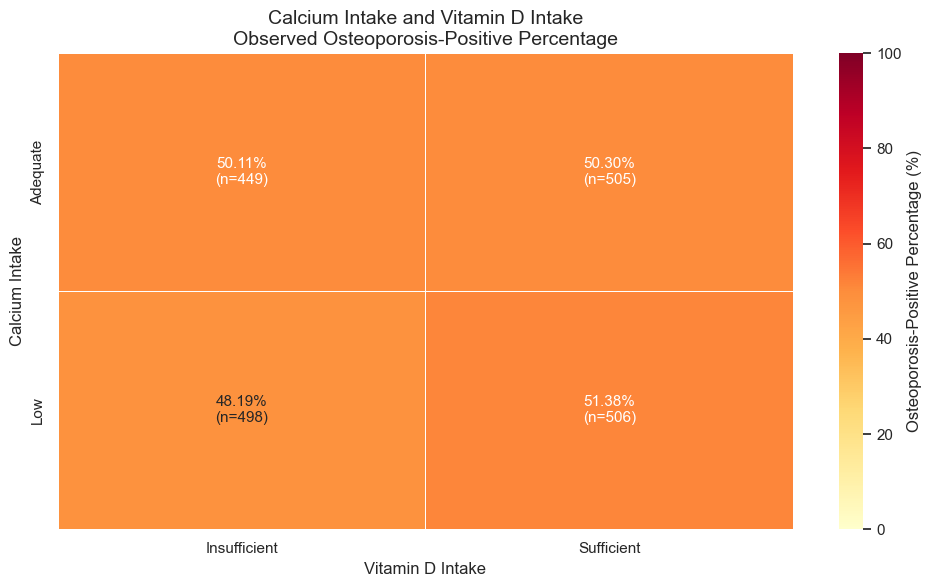

Vitamin D Intake,Insufficient,Sufficient
Calcium Intake,,
Adequate,50.1100,50.3000
Low,48.1900,51.3800


Vitamin D Intake,Insufficient,Sufficient
Calcium Intake,,
Adequate,449,505
Low,498,506


In [ ]:
# Nutritional factors

interaction_heatmap(
    df_eda,
    "Calcium Intake",
    "Vitamin D Intake"
)

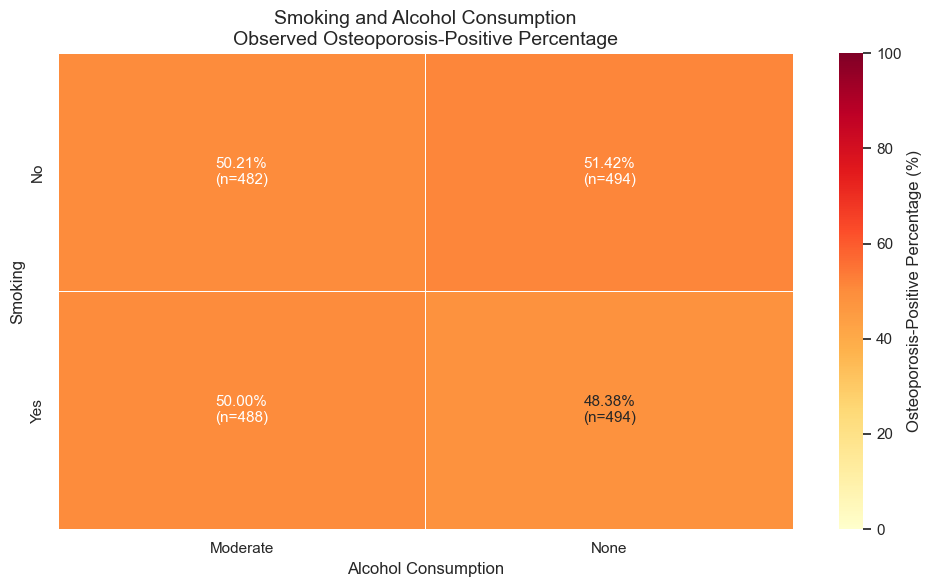

Alcohol Consumption,Moderate,None
Smoking,,
No,50.2100,51.4200
Yes,50.0000,48.3800


Alcohol Consumption,Moderate,None
Smoking,,
No,482,494
Yes,488,494


In [ ]:
# Lifestyle factors

interaction_heatmap(
    df_eda,
    "Smoking",
    "Alcohol Consumption"
)

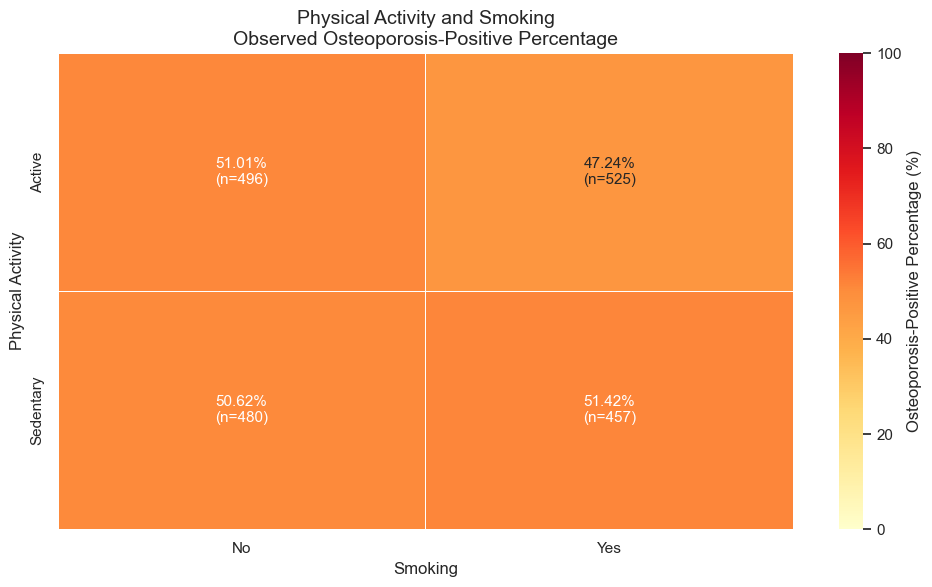

Smoking,No,Yes
Physical Activity,,
Active,51.0100,47.2400
Sedentary,50.6200,51.4200


Smoking,No,Yes
Physical Activity,,
Active,496,525
Sedentary,480,457


In [ ]:
# Physical activity and lifestyle factors

interaction_heatmap(
    df_eda,
    "Physical Activity",
    "Smoking"
)

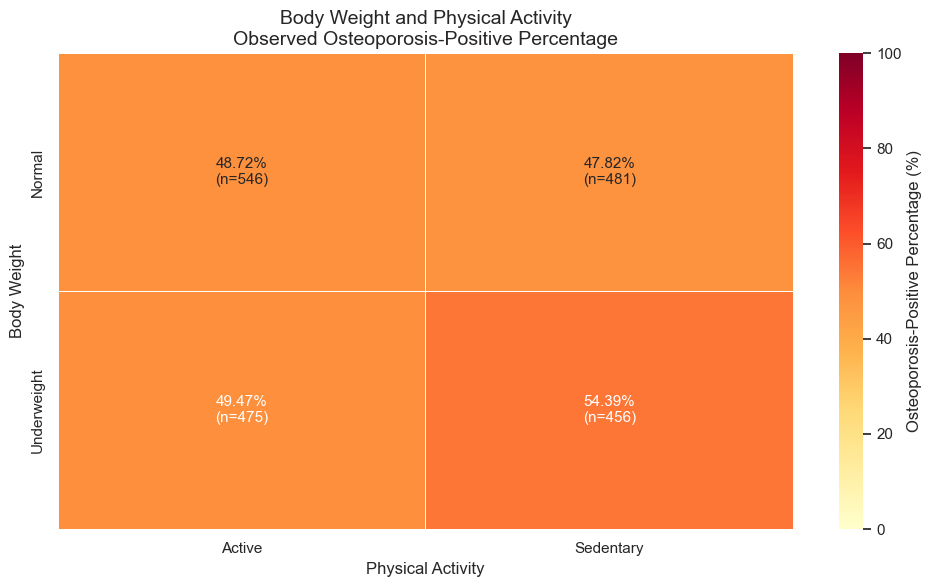

Physical Activity,Active,Sedentary
Body Weight,,
Normal,48.7200,47.8200
Underweight,49.4700,54.3900


Physical Activity,Active,Sedentary
Body Weight,,
Normal,546,481
Underweight,475,456


In [ ]:
# Body weight and physical activity

interaction_heatmap(
    df_eda,
    "Body Weight",
    "Physical Activity"
)

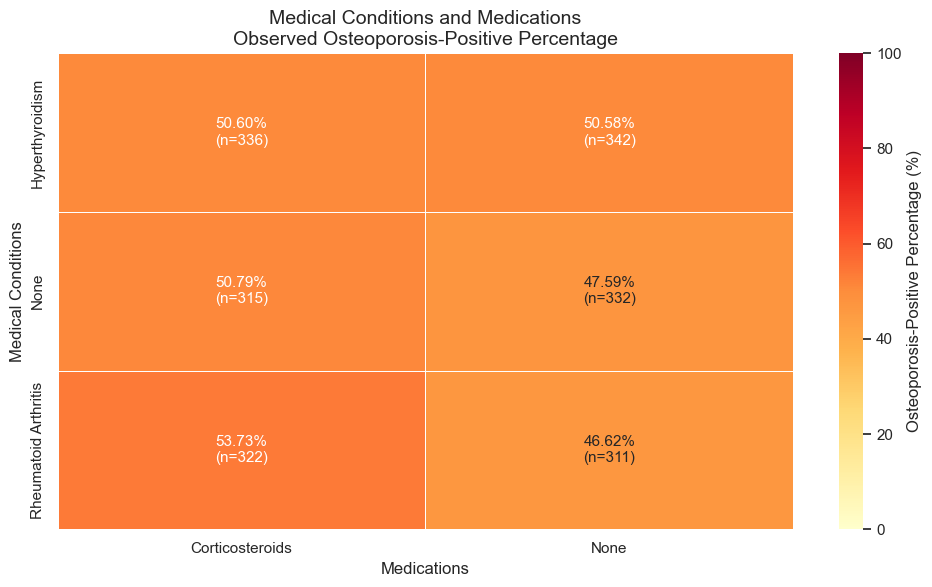

Medications,Corticosteroids,None
Medical Conditions,,
Hyperthyroidism,50.6000,50.5800
None,50.7900,47.5900
Rheumatoid Arthritis,53.7300,46.6200


Medications,Corticosteroids,None
Medical Conditions,,
Hyperthyroidism,336,342
None,315,332
Rheumatoid Arthritis,322,311


In [ ]:
# Medical conditions and medications

interaction_heatmap(
    df_eda,
    "Medical Conditions",
    "Medications"
)

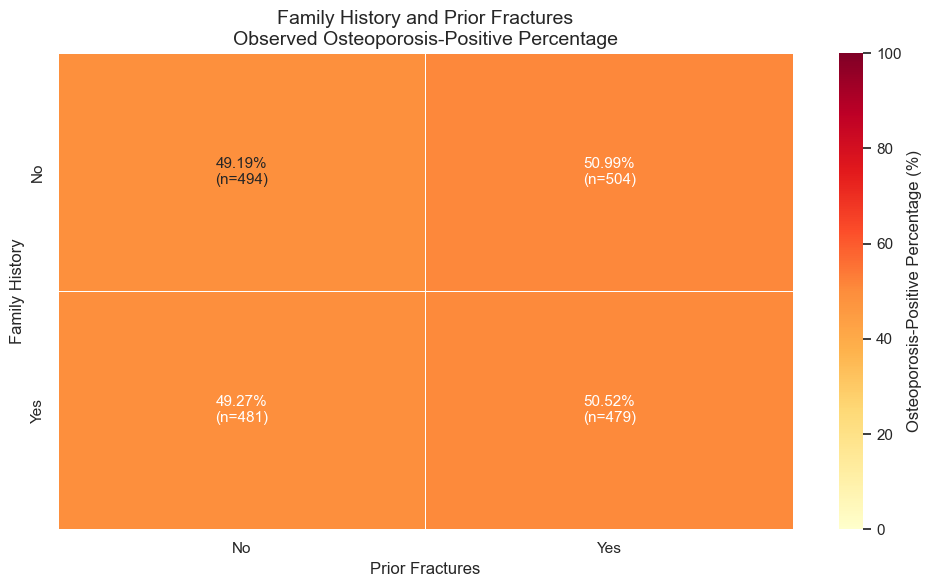

Prior Fractures,No,Yes
Family History,,
No,49.1900,50.9900
Yes,49.2700,50.5200


Prior Fractures,No,Yes
Family History,,
No,494,504
Yes,481,479


In [66]:
# Family history and prior fractures

interaction_heatmap(
    df_eda,
    "Family History",
    "Prior Fractures"
)

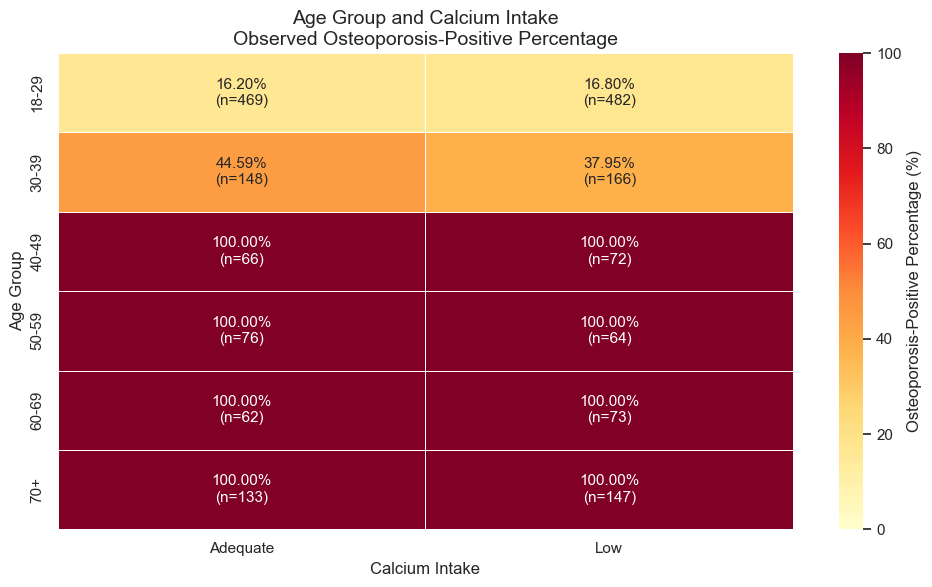

Calcium Intake,Adequate,Low
Age Group,,
18-29,16.2000,16.8000
30-39,44.5900,37.9500
40-49,100.0000,100.0000
50-59,100.0000,100.0000
60-69,100.0000,100.0000
70+,100.0000,100.0000


Calcium Intake,Adequate,Low
Age Group,,
18-29,469,482
30-39,148,166
40-49,66,72
50-59,76,64
60-69,62,73
70+,133,147


In [67]:
interaction_heatmap(
    df_eda,
    "Age Group",
    "Calcium Intake"
)

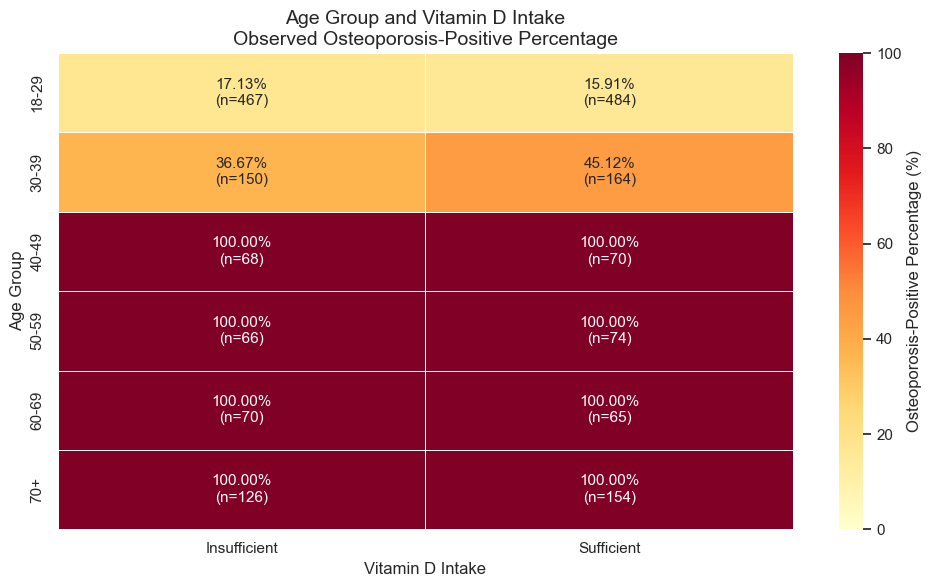

Vitamin D Intake,Insufficient,Sufficient
Age Group,,
18-29,17.1300,15.9100
30-39,36.6700,45.1200
40-49,100.0000,100.0000
50-59,100.0000,100.0000
60-69,100.0000,100.0000
70+,100.0000,100.0000


Vitamin D Intake,Insufficient,Sufficient
Age Group,,
18-29,467,484
30-39,150,164
40-49,68,70
50-59,66,74
60-69,70,65
70+,126,154


In [68]:
interaction_heatmap(
    df_eda,
    "Age Group",
    "Vitamin D Intake"
)

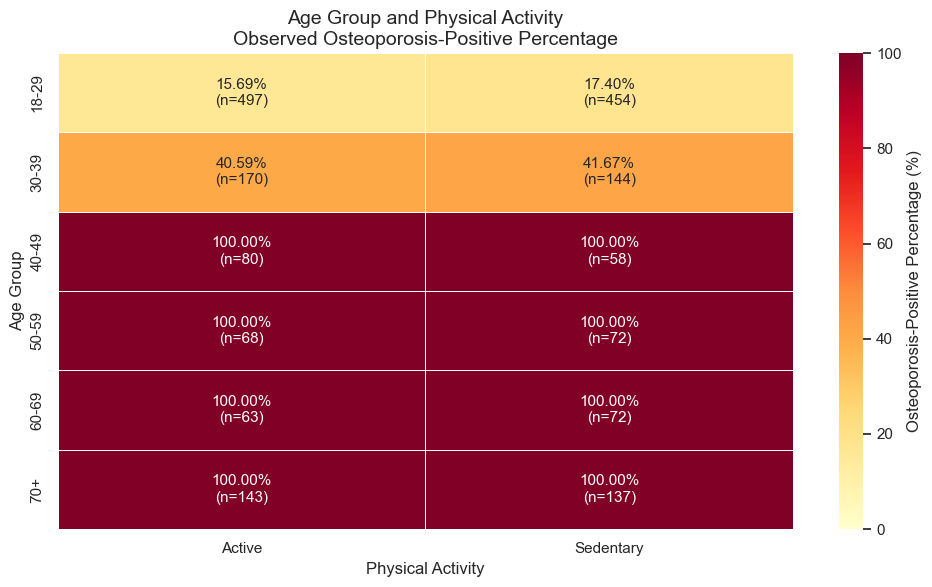

Physical Activity,Active,Sedentary
Age Group,,
18-29,15.6900,17.4000
30-39,40.5900,41.6700
40-49,100.0000,100.0000
50-59,100.0000,100.0000
60-69,100.0000,100.0000
70+,100.0000,100.0000


Physical Activity,Active,Sedentary
Age Group,,
18-29,497,454
30-39,170,144
40-49,80,58
50-59,68,72
60-69,63,72
70+,143,137


In [69]:
interaction_heatmap(
    df_eda,
    "Age Group",
    "Physical Activity"
)

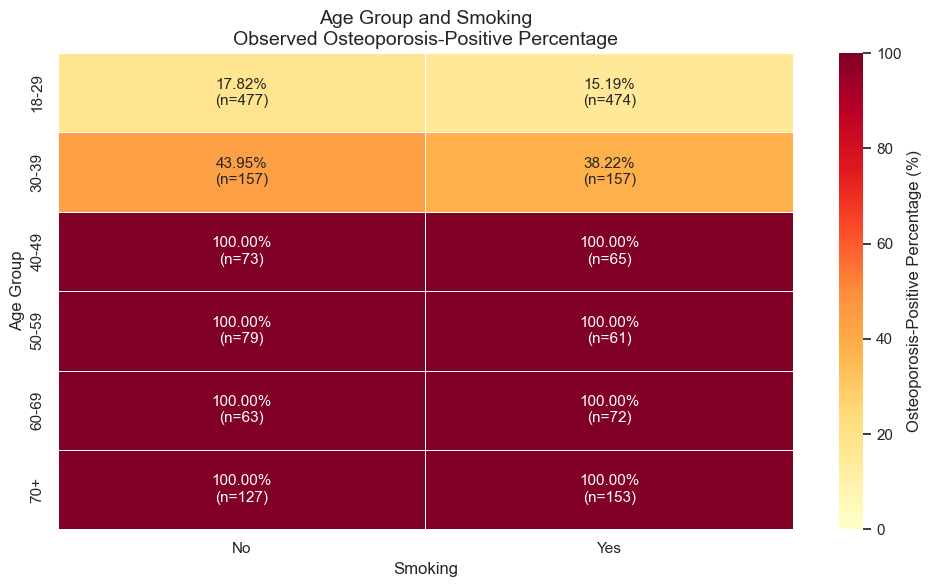

Smoking,No,Yes
Age Group,,
18-29,17.8200,15.1900
30-39,43.9500,38.2200
40-49,100.0000,100.0000
50-59,100.0000,100.0000
60-69,100.0000,100.0000
70+,100.0000,100.0000


Smoking,No,Yes
Age Group,,
18-29,477,474
30-39,157,157
40-49,73,65
50-59,79,61
60-69,63,72
70+,127,153


In [70]:
interaction_heatmap(
    df_eda,
    "Age Group",
    "Smoking"
)

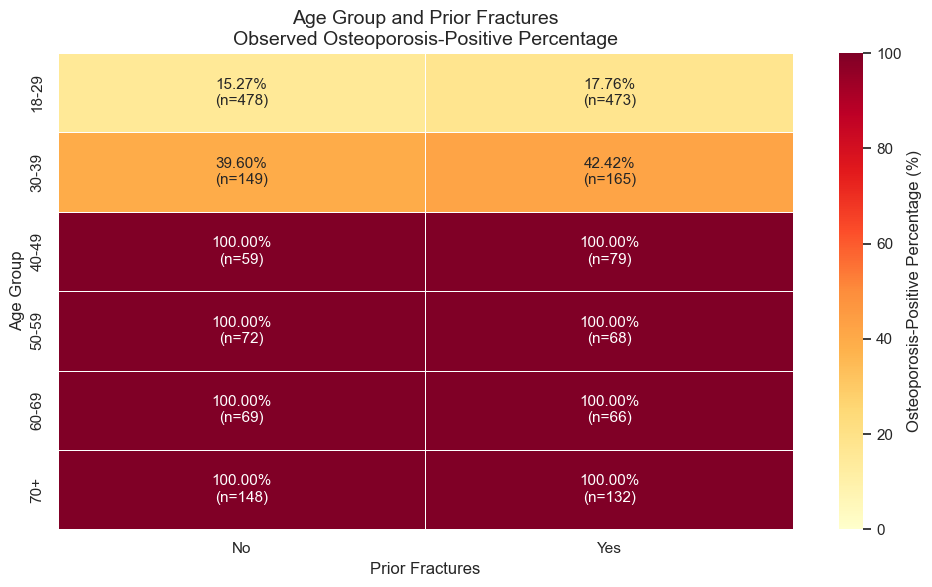

Prior Fractures,No,Yes
Age Group,,
18-29,15.2700,17.7600
30-39,39.6000,42.4200
40-49,100.0000,100.0000
50-59,100.0000,100.0000
60-69,100.0000,100.0000
70+,100.0000,100.0000


Prior Fractures,No,Yes
Age Group,,
18-29,478,473
30-39,149,165
40-49,59,79
50-59,72,68
60-69,69,66
70+,148,132


In [71]:
interaction_heatmap(
    df_eda,
    "Age Group",
    "Prior Fractures"
)

### Statistical association analysis

In [ ]:
# POINT-BISERIAL CORRELATION (AGE VS OSTEOPOROSIS)

correlation, p_value = stats.pointbiserialr(
    df[target],
    df["Age"]
)

print(f"Point-Biserial Correlation: {correlation:.4f}")
print(f"P-value: {p_value:.4e}")

if p_value < 0.05:

    print(
        "A statistically significant association "
        "was detected between Age and Osteoporosis."
    )

else:

    print(
        "No statistically significant association "
        "was detected."
    )

Point-Biserial Correlation: 0.6912
P-value: 2.8339e-278
A statistically significant association was detected between Age and Osteoporosis.


In [ ]:
# MANN-WHITNEY U TEST

age_negative = df.loc[df[target] == 0, "Age"]

age_positive = df.loc[df[target] == 1, "Age"]

u_statistic, p_value = stats.mannwhitneyu(
    age_positive,
    age_negative,
    alternative="two-sided"
)

rank_biserial = (
    2 * u_statistic /
    (len(age_positive) * len(age_negative)) - 1
)

print(f"U Statistic: {u_statistic:.4f}")
print(f"P-value: {p_value:.4e}")
print(f"Rank-Biserial Effect Size: {rank_biserial:.4f}")

U Statistic: 865320.0000
P-value: 1.2815e-209
Rank-Biserial Effect Size: 0.8057


In [ ]:
# CHI-SQUARE TEST FOR ALL CATEGORICAL FEATURES

chi_square_results = []

for col in categorical_cols:

    contingency_table = pd.crosstab(
        df[col],
        df[target]
    )

    chi2, p_value, dof, expected = (
        stats.chi2_contingency(
            contingency_table,
            correction=False
        )
    )

    chi_square_results.append({

        "Feature": col,

        "Chi-Square Statistic": chi2,

        "Degrees of Freedom": dof,

        "P-value": p_value,

        "Minimum Expected Count": expected.min(),

        "Expected Cells Below 5": (expected < 5).sum(),

        "Significant (Unadjusted)": (
            "Yes" if p_value < 0.05 else "No"
        )

    })

chi_square_df = pd.DataFrame(
    chi_square_results
).sort_values(
    "P-value"
).reset_index(drop=True)

display(chi_square_df.round(6))

,Feature,Chi-Square Statistic,Degrees of Freedom,P-value,Minimum Expected Count,Expected Cells Below 5,Significant (Unadjusted)
0,Body Weight,2.5086,1,0.1132,465.5000,0,No
1,Medications,2.2248,1,0.1358,486.5000,0,No
2,Physical Activity,0.7388,1,0.3900,468.5000,0,No
3,Vitamin D Intake,0.5910,1,0.4420,473.5000,0,No
4,Smoking,0.5230,1,0.4696,488.0000,0,No
5,Prior Fractures,0.4597,1,0.4978,487.5000,0,No
6,Hormonal Changes,0.4597,1,0.4978,488.5000,0,No
7,Gender,0.2942,1,0.5875,483.0000,0,No
8,Calcium Intake,0.0327,1,0.8565,477.0000,0,No
9,Medical Conditions,0.2956,2,0.8626,316.5000,0,No


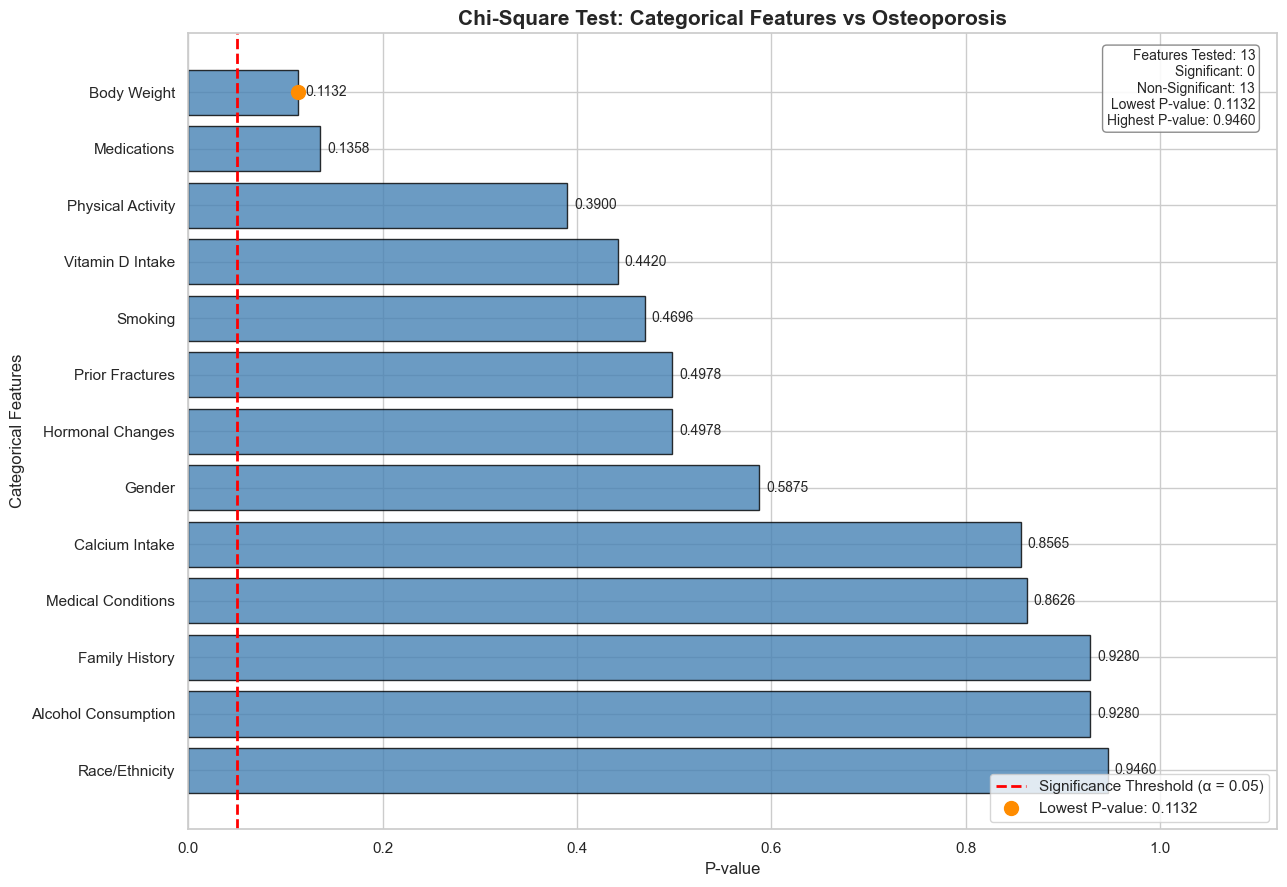

In [ ]:
# CHI-SQUARE TEST P-VALUE VISUALIZATION

alpha = 0.05

plot_df = chi_square_df.sort_values(
    "P-value",
    ascending=True
).copy()

# Assign colors based on statistical significance
colors = [
    "seagreen" if p < alpha else "steelblue"
    for p in plot_df["P-value"]
]

fig, ax = plt.subplots(figsize=(13, 9))

bars = ax.barh(
    plot_df["Feature"],
    plot_df["P-value"],
    color=colors,
    edgecolor="black",
    alpha=0.8
)

# Display p-values on bars
ax.bar_label(
    bars,
    labels=[
        f"{p:.4f}"
        for p in plot_df["P-value"]
    ],
    padding=5,
    fontsize=10
)

# Statistical significance threshold
ax.axvline(
    alpha,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Significance Threshold (α = {alpha})"
)

# Highlight the lowest p-value
min_idx = plot_df["P-value"].idxmin()

min_feature = plot_df.loc[min_idx, "Feature"]
min_p = plot_df.loc[min_idx, "P-value"]

ax.scatter(
    min_p,
    min_feature,
    color="darkorange",
    s=100,
    zorder=5,
    label=f"Lowest P-value: {min_p:.4f}"
)

# Summary statistics
significant_count = (
    plot_df["P-value"] < alpha
).sum()

summary_text = (
    f"Features Tested: {len(plot_df)}\n"
    f"Significant: {significant_count}\n"
    f"Non-Significant: "
    f"{len(plot_df) - significant_count}\n"
    f"Lowest P-value: {min_p:.4f}\n"
    f"Highest P-value: "
    f"{plot_df['P-value'].max():.4f}"
)

ax.text(
    0.98,
    0.98,
    summary_text,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10,
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        edgecolor="gray",
        alpha=0.9
    )
)

ax.invert_yaxis()

ax.set_xlim(0, 1.12)

ax.set_xlabel("P-value")
ax.set_ylabel("Categorical Features")

ax.set_title(
    "Chi-Square Test: Categorical Features vs Osteoporosis",
    fontsize=15,
    fontweight="bold"
)

ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

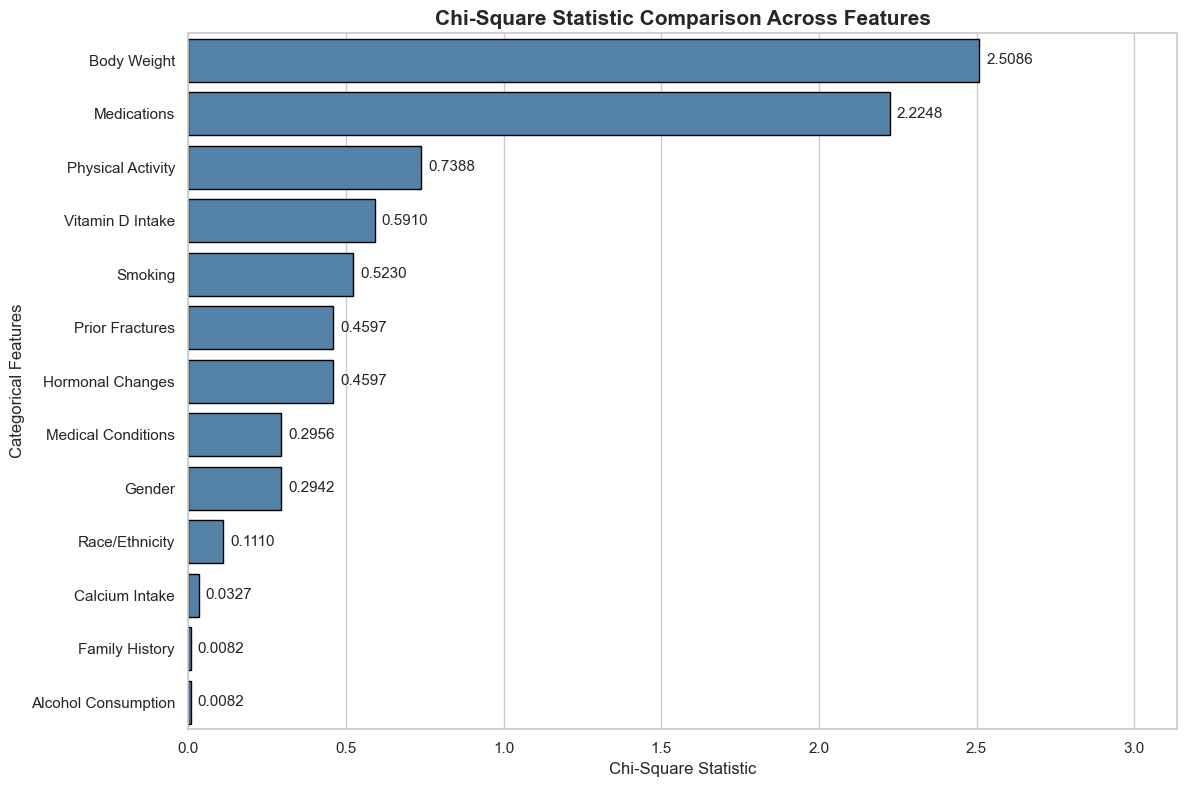

In [90]:
# CHI-SQUARE STATISTIC COMPARISON

plot_df = chi_square_df.sort_values(
    "Chi-Square Statistic",
    ascending=False
)

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=plot_df,
    x="Chi-Square Statistic",
    y="Feature",
    color="steelblue",
    edgecolor="black"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",
        padding=5
    )

plt.xlim(
    0,
    plot_df["Chi-Square Statistic"].max() * 1.25
)

plt.xlabel("Chi-Square Statistic")
plt.ylabel("Categorical Features")

plt.title(
    "Chi-Square Statistic Comparison Across Features",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [75]:
# MULTIPLE HYPOTHESIS TESTING CORRECTION

from statsmodels.stats.multitest import multipletests

reject, adjusted_p, _, _ = multipletests(
    chi_square_df["P-value"],
    alpha=0.05,
    method="fdr_bh"
)

chi_square_df["Adjusted P-value"] = adjusted_p

chi_square_df["Significant (Adjusted)"] = np.where(
    reject,
    "Yes",
    "No"
)

display(chi_square_df.round(6))

,Feature,Chi-Square Statistic,Degrees of Freedom,P-value,Minimum Expected Count,Expected Cells Below 5,Significant (Unadjusted),Adjusted P-value,Significant (Adjusted)
0,Body Weight,2.5086,1,0.1132,465.5000,0,No,0.8828,No
1,Medications,2.2248,1,0.1358,486.5000,0,No,0.8828,No
2,Physical Activity,0.7388,1,0.3900,468.5000,0,No,0.9245,No
3,Vitamin D Intake,0.5910,1,0.4420,473.5000,0,No,0.9245,No
4,Smoking,0.5230,1,0.4696,488.0000,0,No,0.9245,No
5,Prior Fractures,0.4597,1,0.4978,487.5000,0,No,0.9245,No
6,Hormonal Changes,0.4597,1,0.4978,488.5000,0,No,0.9245,No
7,Gender,0.2942,1,0.5875,483.0000,0,No,0.9460,No
8,Calcium Intake,0.0327,1,0.8565,477.0000,0,No,0.9460,No
9,Medical Conditions,0.2956,2,0.8626,316.5000,0,No,0.9460,No


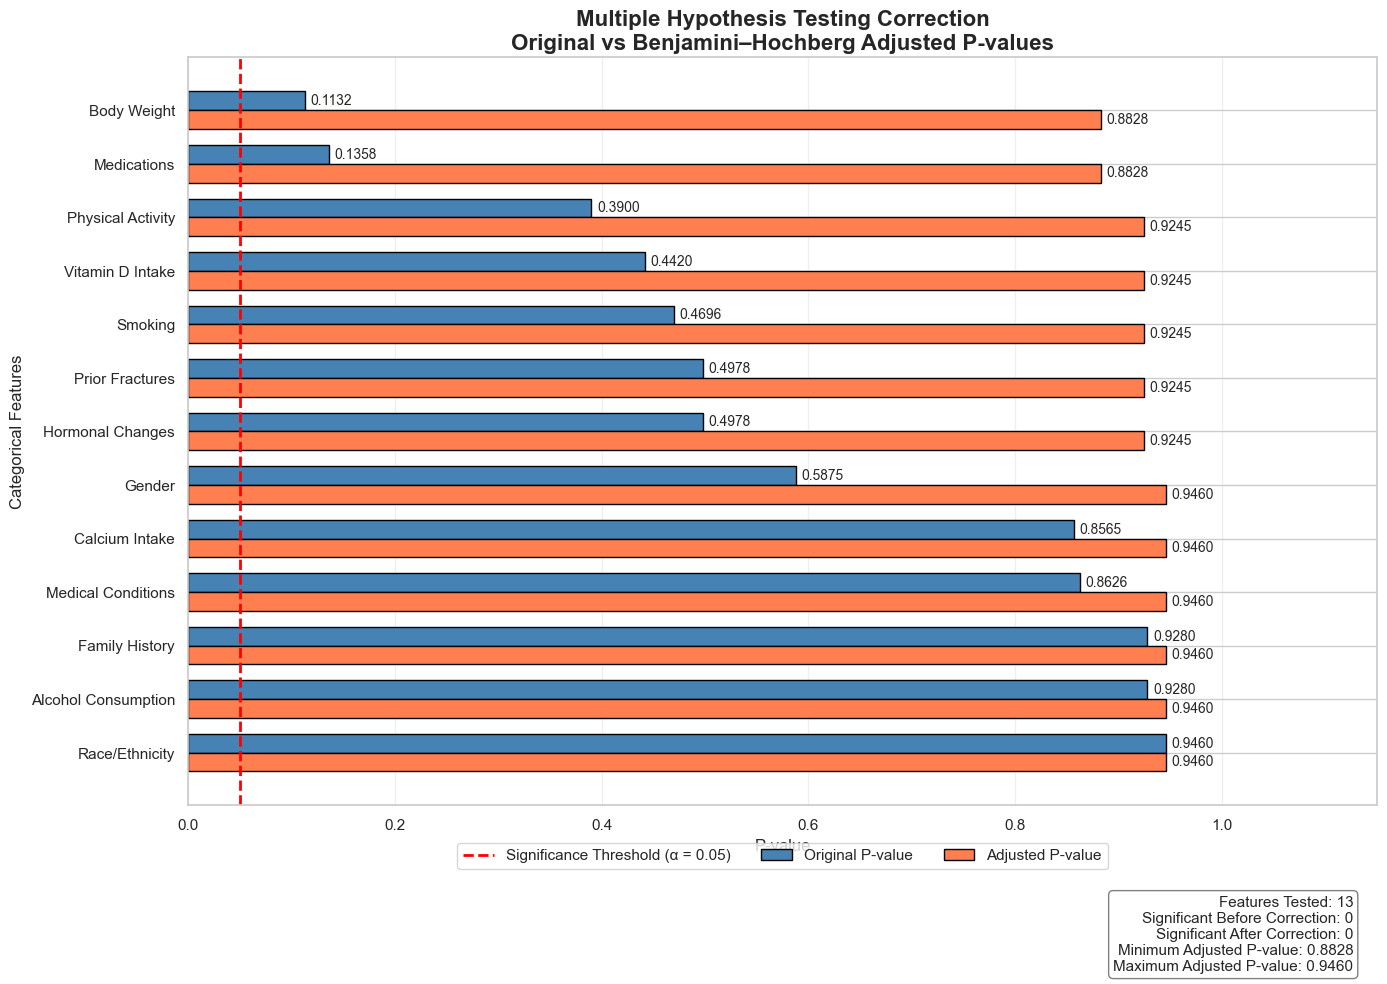

In [91]:
# MULTIPLE HYPOTHESIS TESTING CORRECTION - VISUALIZATION

plot_df = chi_square_df.sort_values(
    "P-value",
    ascending=True
).reset_index(drop=True)

alpha = 0.05

y = np.arange(len(plot_df))
bar_height = 0.35

fig, ax = plt.subplots(figsize=(14, 10))

# Original p-values
bars1 = ax.barh(
    y - bar_height / 2,
    plot_df["P-value"],
    height=bar_height,
    color="steelblue",
    edgecolor="black",
    label="Original P-value"
)

# Adjusted p-values
bars2 = ax.barh(
    y + bar_height / 2,
    plot_df["Adjusted P-value"],
    height=bar_height,
    color="coral",
    edgecolor="black",
    label="Adjusted P-value"
)

# Add values on bars
ax.bar_label(
    bars1,
    fmt="%.4f",
    padding=4,
    fontsize=10
)

ax.bar_label(
    bars2,
    fmt="%.4f",
    padding=4,
    fontsize=10
)

# Significance threshold
ax.axvline(
    alpha,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Significance Threshold (α = 0.05)"
)

# Feature labels
ax.set_yticks(y)
ax.set_yticklabels(plot_df["Feature"])

ax.invert_yaxis()

# Summary statistics
before_count = (
    plot_df["P-value"] < alpha
).sum()

after_count = (
    plot_df["Adjusted P-value"] < alpha
).sum()

summary_text = (
    f"Features Tested: {len(plot_df)}\n"
    f"Significant Before Correction: {before_count}\n"
    f"Significant After Correction: {after_count}\n"
    f"Minimum Adjusted P-value: "
    f"{plot_df['Adjusted P-value'].min():.4f}\n"
    f"Maximum Adjusted P-value: "
    f"{plot_df['Adjusted P-value'].max():.4f}"
)

ax.text(
    0.98,
    -0.12,
    summary_text,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=11,
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        edgecolor="gray"
    )
)

ax.set_xlim(0, 1.15)

ax.set_xlabel("P-value")
ax.set_ylabel("Categorical Features")

ax.set_title(
    "Multiple Hypothesis Testing Correction\n"
    "Original vs Benjamini–Hochberg Adjusted P-values",
    fontsize=16,
    fontweight="bold"
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.04),
    ncol=3
)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [92]:
# IMPACT OF MULTIPLE HYPOTHESIS TESTING CORRECTION

correction_summary = chi_square_df[[
    "Feature",
    "P-value",
    "Adjusted P-value"
]].copy()

correction_summary["Absolute Increase"] = (
    correction_summary["Adjusted P-value"] -
    correction_summary["P-value"]
)

correction_summary["Percentage Increase (%)"] = (
    correction_summary["Absolute Increase"] /
    correction_summary["P-value"].replace(0, np.nan)
) * 100

correction_summary["Correction Factor"] = (
    correction_summary["Adjusted P-value"] /
    correction_summary["P-value"].replace(0, np.nan)
)

correction_summary = correction_summary.sort_values(
    "Absolute Increase",
    ascending=False
)

display(correction_summary.round(4))

,Feature,P-value,Adjusted P-value,Absolute Increase,Percentage Increase (%),Correction Factor
0,Body Weight,0.1132,0.8828,0.7695,679.6375,7.7964
1,Medications,0.1358,0.8828,0.7470,550.0000,6.5000
2,Physical Activity,0.3900,0.9245,0.5344,137.0222,2.3702
3,Vitamin D Intake,0.4420,0.9245,0.4824,109.1435,2.0914
4,Smoking,0.4696,0.9245,0.4549,96.8734,1.9687
5,Prior Fractures,0.4978,0.9245,0.4267,85.7153,1.8572
6,Hormonal Changes,0.4978,0.9245,0.4267,85.7143,1.8571
7,Gender,0.5875,0.9460,0.3585,61.0184,1.6102
8,Calcium Intake,0.8565,0.9460,0.0895,10.4540,1.1045
9,Medical Conditions,0.8626,0.9460,0.0834,9.6719,1.0967


In [ ]:
# CRAMER'S V ASSOCIATION FUNCTION

def cramers_v(x, y):

    confusion_matrix = pd.crosstab(x, y)

    if min(confusion_matrix.shape) < 2:
        return np.nan

    chi2 = stats.chi2_contingency(
        confusion_matrix,
        correction=False
    )[0]

    n = confusion_matrix.to_numpy().sum()

    if n <= 1:
        return np.nan

    rows, cols = confusion_matrix.shape

    phi2 = chi2 / n

    # Bias correction
    phi2_corrected = max(
        0,
        phi2 - (
            (cols - 1) * (rows - 1)
        ) / (n - 1)
    )

    rows_corrected = (
        rows - (rows - 1) ** 2 / (n - 1)
    )

    cols_corrected = (
        cols - (cols - 1) ** 2 / (n - 1)
    )

    denominator = min(
        cols_corrected - 1,
        rows_corrected - 1
    )

    if denominator <= 0:
        return np.nan

    return np.sqrt(
        phi2_corrected / denominator
    )

In [93]:
display(cramers_df.round(6))

,Feature,Cramer's V
0,Body Weight,0.0278
1,Medications,0.0250
2,Gender,0.0000
3,Family History,0.0000
4,Hormonal Changes,0.0000
5,Race/Ethnicity,0.0000
6,Calcium Intake,0.0000
7,Physical Activity,0.0000
8,Vitamin D Intake,0.0000
9,Smoking,0.0000


In [ ]:
# CRAMER'S V - FEATURE VS TARGET

cramers_results = []

for col in categorical_cols:

    association = cramers_v(
        df[col],
        df[target]
    )

    cramers_results.append({
        "Feature": col,
        "Cramer's V": association
    })

cramers_df = pd.DataFrame(
    cramers_results
).sort_values(
    "Cramer's V",
    ascending=False
).reset_index(drop=True)

display(cramers_df.round(4))

,Feature,Cramer's V
0,Body Weight,0.0278
1,Medications,0.0250
2,Gender,0.0000
3,Family History,0.0000
4,Hormonal Changes,0.0000
5,Race/Ethnicity,0.0000
6,Calcium Intake,0.0000
7,Physical Activity,0.0000
8,Vitamin D Intake,0.0000
9,Smoking,0.0000


In [94]:
# TRADITIONAL VS BIAS-CORRECTED CRAMER'S V

cramers_comparison = []

for col in categorical_cols:

    contingency = pd.crosstab(
        df[col],
        df[target]
    )

    # Chi-square statistic without Yates correction
    chi2, p, dof, expected = stats.chi2_contingency(
        contingency,
        correction=False
    )

    n = contingency.to_numpy().sum()

    r, c = contingency.shape

    # Traditional Cramer's V
    traditional_v = np.sqrt(
        chi2 / (n * min(r - 1, c - 1))
    )

    # Bias-corrected Cramer's V
    phi2 = chi2 / n

    phi2_corrected = max(
        0,
        phi2 - ((c - 1) * (r - 1)) / (n - 1)
    )

    r_corrected = r - ((r - 1)**2) / (n - 1)

    c_corrected = c - ((c - 1)**2) / (n - 1)

    denominator = min(
        r_corrected - 1,
        c_corrected - 1
    )

    corrected_v = (
        np.sqrt(phi2_corrected / denominator)
        if denominator > 0 else np.nan
    )

    cramers_comparison.append({
        "Feature": col,
        "Traditional Cramer's V": traditional_v,
        "Bias-Corrected Cramer's V": corrected_v,
        "Difference": traditional_v - corrected_v
    })

cramers_comparison_df = pd.DataFrame(
    cramers_comparison
).sort_values(
    "Traditional Cramer's V",
    ascending=False
).reset_index(drop=True)

display(cramers_comparison_df.round(6))

,Feature,Traditional Cramer's V,Bias-Corrected Cramer's V,Difference
0,Body Weight,0.0358,0.0278,0.0080
1,Medications,0.0337,0.0250,0.0087
2,Physical Activity,0.0194,0.0000,0.0194
3,Vitamin D Intake,0.0174,0.0000,0.0174
4,Smoking,0.0163,0.0000,0.0163
5,Prior Fractures,0.0153,0.0000,0.0153
6,Hormonal Changes,0.0153,0.0000,0.0153
7,Medical Conditions,0.0123,0.0000,0.0123
8,Gender,0.0123,0.0000,0.0123
9,Race/Ethnicity,0.0075,0.0000,0.0075


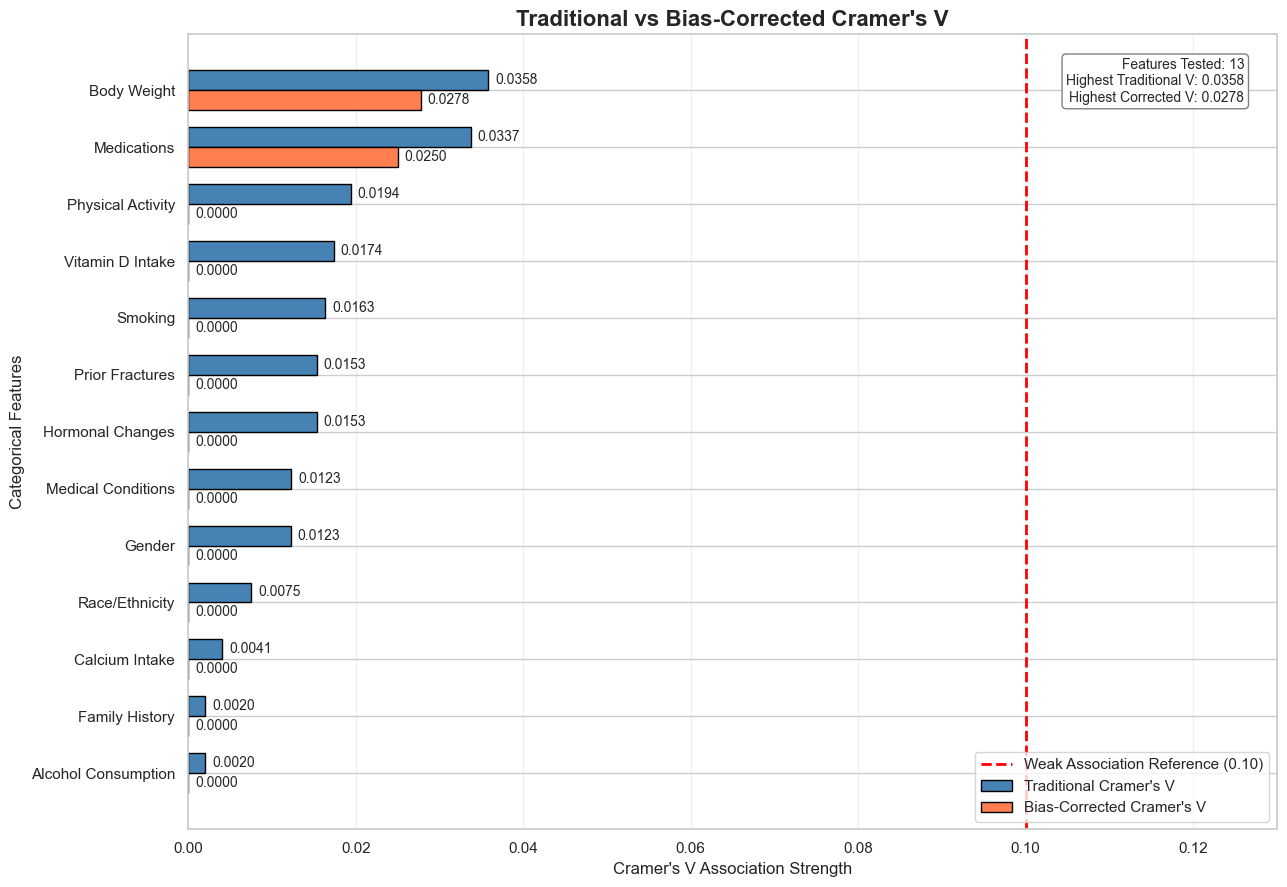

In [95]:
# CRAMER'S V COMPARISON VISUALIZATION

plot_df = cramers_comparison_df.copy()

y = np.arange(len(plot_df))

bar_height = 0.35

fig, ax = plt.subplots(figsize=(13, 9))

# Traditional Cramer's V
bars1 = ax.barh(
    y - bar_height / 2,
    plot_df["Traditional Cramer's V"],
    height=bar_height,
    color="steelblue",
    edgecolor="black",
    label="Traditional Cramer's V"
)

# Bias-corrected Cramer's V
bars2 = ax.barh(
    y + bar_height / 2,
    plot_df["Bias-Corrected Cramer's V"],
    height=bar_height,
    color="coral",
    edgecolor="black",
    label="Bias-Corrected Cramer's V"
)

# Display values
ax.bar_label(
    bars1,
    fmt="%.4f",
    padding=5,
    fontsize=10
)

ax.bar_label(
    bars2,
    fmt="%.4f",
    padding=5,
    fontsize=10
)

# Weak association reference threshold
ax.axvline(
    0.10,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Weak Association Reference (0.10)"
)

# Feature labels
ax.set_yticks(y)
ax.set_yticklabels(plot_df["Feature"])

ax.invert_yaxis()

# Summary statistics
summary_text = (
    f"Features Tested: {len(plot_df)}\n"
    f"Highest Traditional V: "
    f"{plot_df['Traditional Cramer' + chr(39) + 's V'].max():.4f}\n"
    f"Highest Corrected V: "
    f"{plot_df['Bias-Corrected Cramer' + chr(39) + 's V'].max():.4f}"
)

ax.text(
    0.97,
    0.97,
    summary_text,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10,
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        edgecolor="gray"
    )
)

ax.set_xlim(0, 0.13)

ax.set_xlabel("Cramer's V Association Strength")
ax.set_ylabel("Categorical Features")

ax.set_title(
    "Traditional vs Bias-Corrected Cramer's V",
    fontsize=16,
    fontweight="bold"
)

ax.legend(loc="lower right")

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

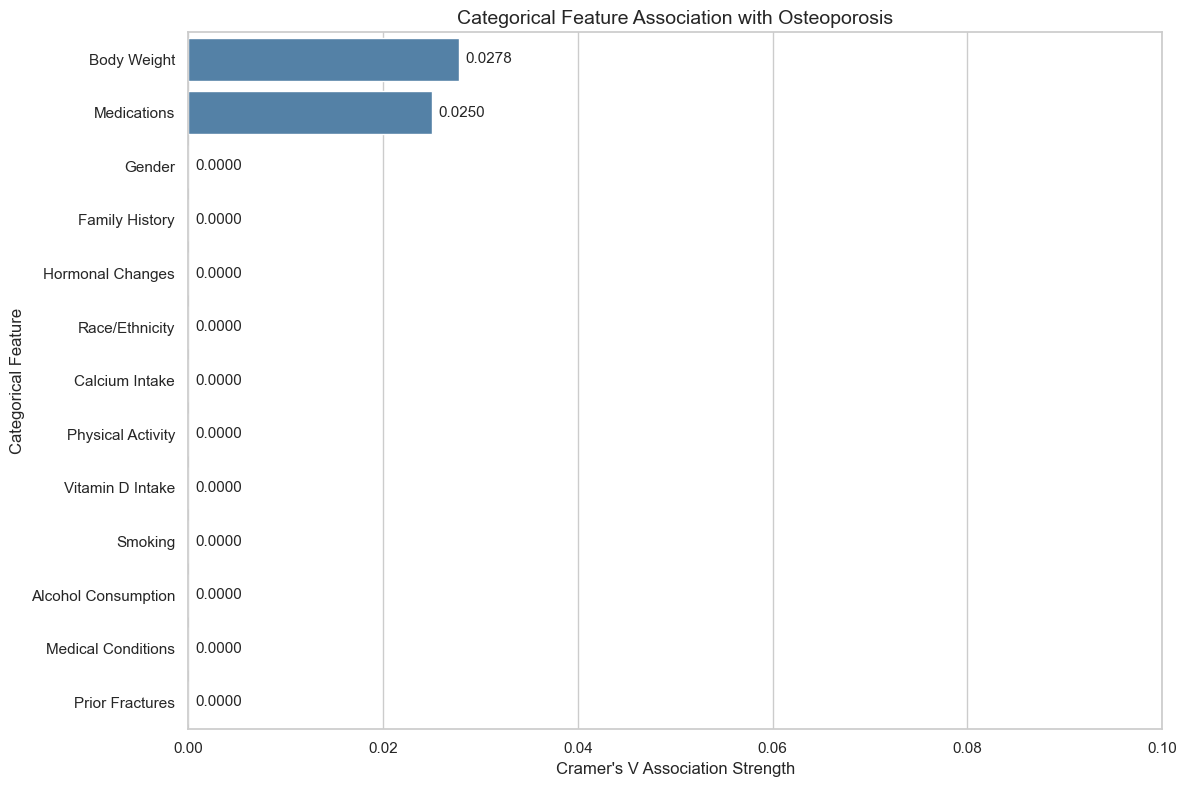

In [78]:
# CRAMER'S V FEATURE ASSOCIATION PLOT

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=cramers_df,
    x="Cramer's V",
    y="Feature",
    color="steelblue"
)

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.4f",
        padding=5
    )

plt.xlim(
    0,
    max(0.1, cramers_df["Cramer's V"].max() * 1.25)
)

plt.xlabel("Cramer's V Association Strength")
plt.ylabel("Categorical Feature")
plt.title("Categorical Feature Association with Osteoporosis")

plt.tight_layout()
plt.show()

In [ ]:
# CRAMER'S V ASSOCIATION MATRIX

association_cols = (
    categorical_cols +
    ["Age Group", target]
)

cramers_matrix = pd.DataFrame(
    np.nan,
    index=association_cols,
    columns=association_cols
)

for i, col1 in enumerate(association_cols):

    for j in range(i, len(association_cols)):

        col2 = association_cols[j]

        if col1 == col2:
            value = 1.0

        else:
            value = cramers_v(
                df_eda[col1],
                df_eda[col2]
            )

        cramers_matrix.loc[col1, col2] = value
        cramers_matrix.loc[col2, col1] = value

display(cramers_matrix.round(4))

,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Age Group,Osteoporosis
Gender,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0151,0.0329,0.0000,0.0000,0.0000,0.0000,0.0101,0.0000
Hormonal Changes,0.0000,1.0000,0.0000,0.0157,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0261,0.0000
Family History,0.0000,0.0000,1.0000,0.0000,0.0000,0.0081,0.0000,0.0058,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Race/Ethnicity,0.0000,0.0157,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0084,0.0000,0.0000,0.0000,0.0130,0.0353,0.0000
Body Weight,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0251,0.0350,0.0000,0.0284,0.0278
Calcium Intake,0.0000,0.0000,0.0081,0.0000,0.0000,1.0000,0.0115,0.0000,0.0278,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Vitamin D Intake,0.0000,0.0000,0.0000,0.0000,0.0000,0.0115,1.0000,0.0269,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Physical Activity,0.0151,0.0000,0.0058,0.0000,0.0000,0.0000,0.0269,1.0000,0.0137,0.0000,0.0000,0.0254,0.0445,0.0000,0.0000
Smoking,0.0329,0.0000,0.0000,0.0084,0.0000,0.0278,0.0000,0.0137,1.0000,0.0000,0.0489,0.0000,0.0000,0.0200,0.0000
Alcohol Consumption,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0315,0.0000,0.0000


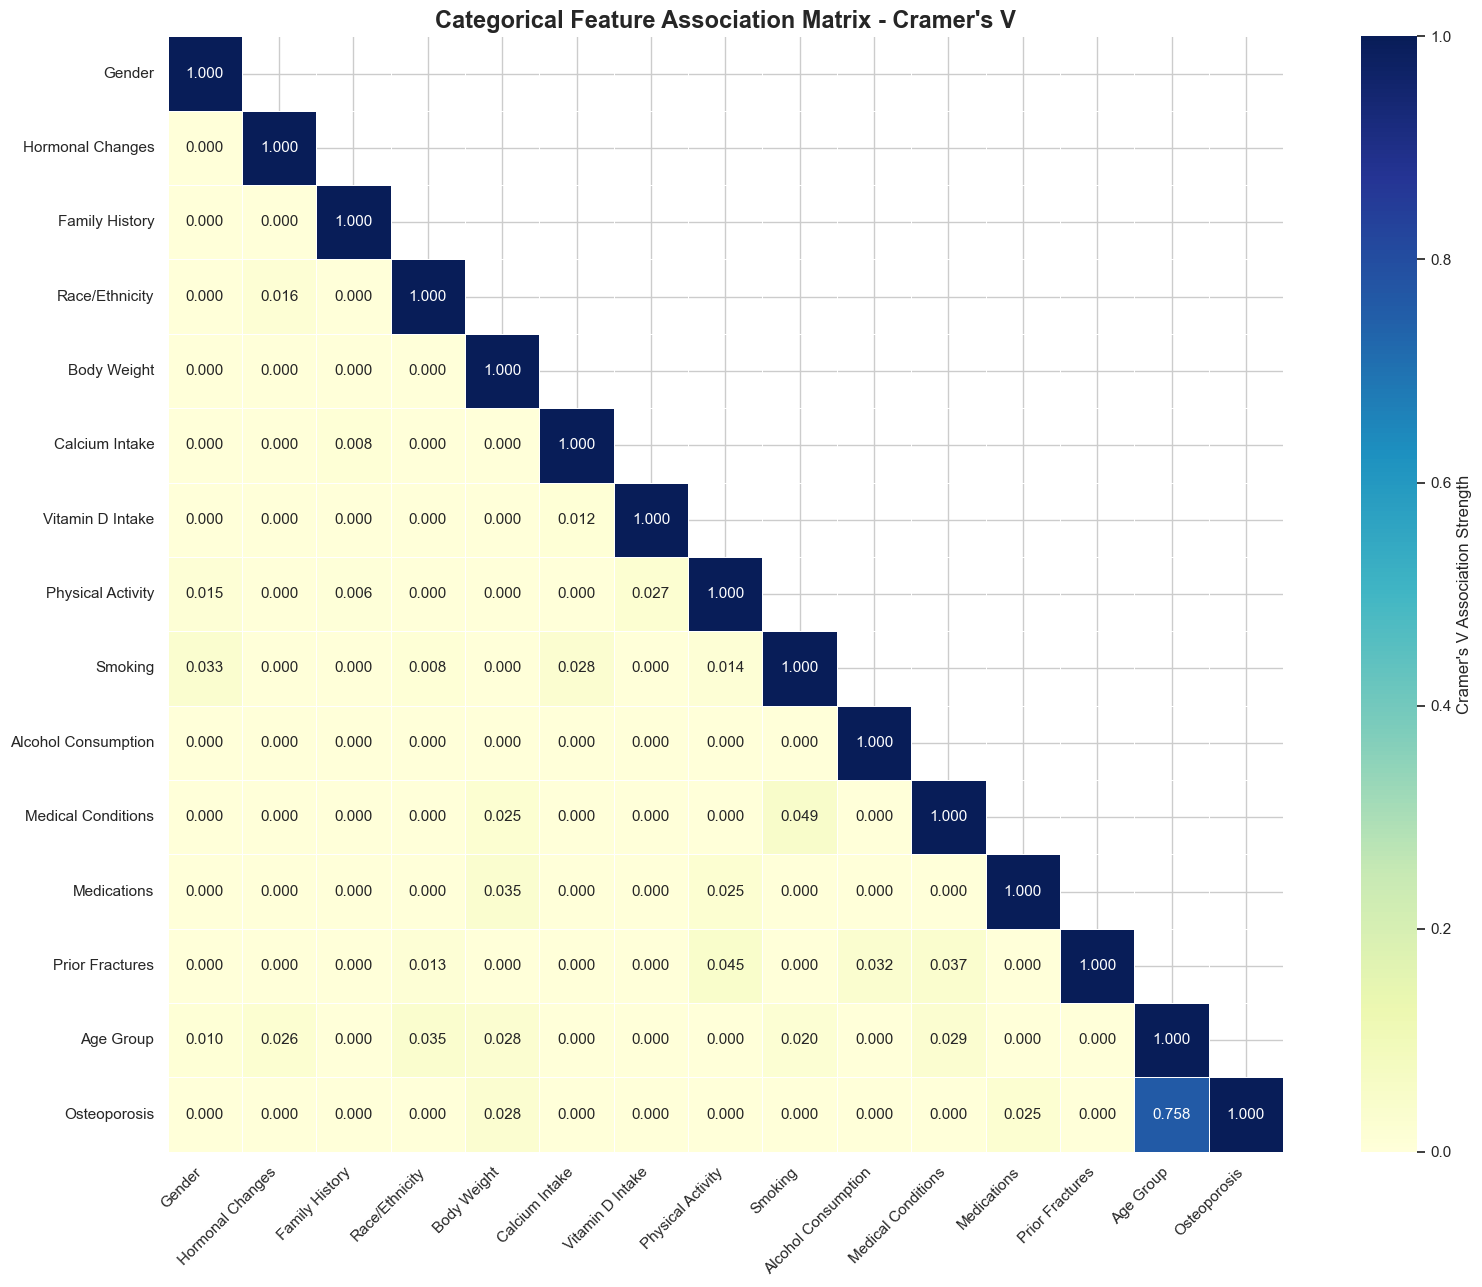

In [ ]:
# CRAMER'S V ASSOCIATION HEATMAP

plt.figure(figsize=(17, 13))

mask = np.triu(
    np.ones_like(
        cramers_matrix,
        dtype=bool
    ),
    k=1
)

sns.heatmap(
    cramers_matrix,
    mask=mask,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "Cramer's V Association Strength"
    }
)

plt.title(
    "Categorical Feature Association Matrix - Cramer's V",
    fontsize=17,
    fontweight="bold"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [96]:
# CRAMER'S V - STRONGEST FEATURE ASSOCIATIONS

association_pairs = []

for i in range(len(cramers_matrix.columns)):

    for j in range(i):

        association_pairs.append({
            "Feature 1": cramers_matrix.columns[i],
            "Feature 2": cramers_matrix.columns[j],
            "Cramer's V": cramers_matrix.iloc[i, j]
        })

association_pairs_df = pd.DataFrame(
    association_pairs
).sort_values(
    "Cramer's V",
    ascending=False
).reset_index(drop=True)

print("TOP 15 STRONGEST ASSOCIATIONS")
display(association_pairs_df.head(15).round(4))

TOP 15 STRONGEST ASSOCIATIONS


,Feature 1,Feature 2,Cramer's V
0,Osteoporosis,Age Group,0.7581
1,Medical Conditions,Smoking,0.0489
2,Prior Fractures,Physical Activity,0.0445
3,Prior Fractures,Medical Conditions,0.0374
4,Age Group,Race/Ethnicity,0.0353
5,Medications,Body Weight,0.0350
6,Smoking,Gender,0.0329
7,Prior Fractures,Alcohol Consumption,0.0315
8,Age Group,Medical Conditions,0.0292
9,Age Group,Body Weight,0.0284


In [97]:
# PREDICTOR-TO-PREDICTOR ASSOCIATIONS

predictor_associations = association_pairs_df[
    (association_pairs_df["Feature 1"] != target) &
    (association_pairs_df["Feature 2"] != target)
].copy()

print("TOP 15 PREDICTOR ASSOCIATIONS")

display(
    predictor_associations.head(15).round(4)
)

print(
    "Maximum Predictor Association:",
    round(predictor_associations["Cramer's V"].max(), 4)
)

print(
    "Mean Predictor Association:",
    round(predictor_associations["Cramer's V"].mean(), 4)
)

print(
    "Strong Associations (V >= 0.70):",
    (predictor_associations["Cramer's V"] >= 0.70).sum()
)

TOP 15 PREDICTOR ASSOCIATIONS


,Feature 1,Feature 2,Cramer's V
1,Medical Conditions,Smoking,0.0489
2,Prior Fractures,Physical Activity,0.0445
3,Prior Fractures,Medical Conditions,0.0374
4,Age Group,Race/Ethnicity,0.0353
5,Medications,Body Weight,0.0350
6,Smoking,Gender,0.0329
7,Prior Fractures,Alcohol Consumption,0.0315
8,Age Group,Medical Conditions,0.0292
9,Age Group,Body Weight,0.0284
10,Smoking,Calcium Intake,0.0278


Maximum Predictor Association: 0.0489
Mean Predictor Association: 0.0063
Strong Associations (V >= 0.70): 0


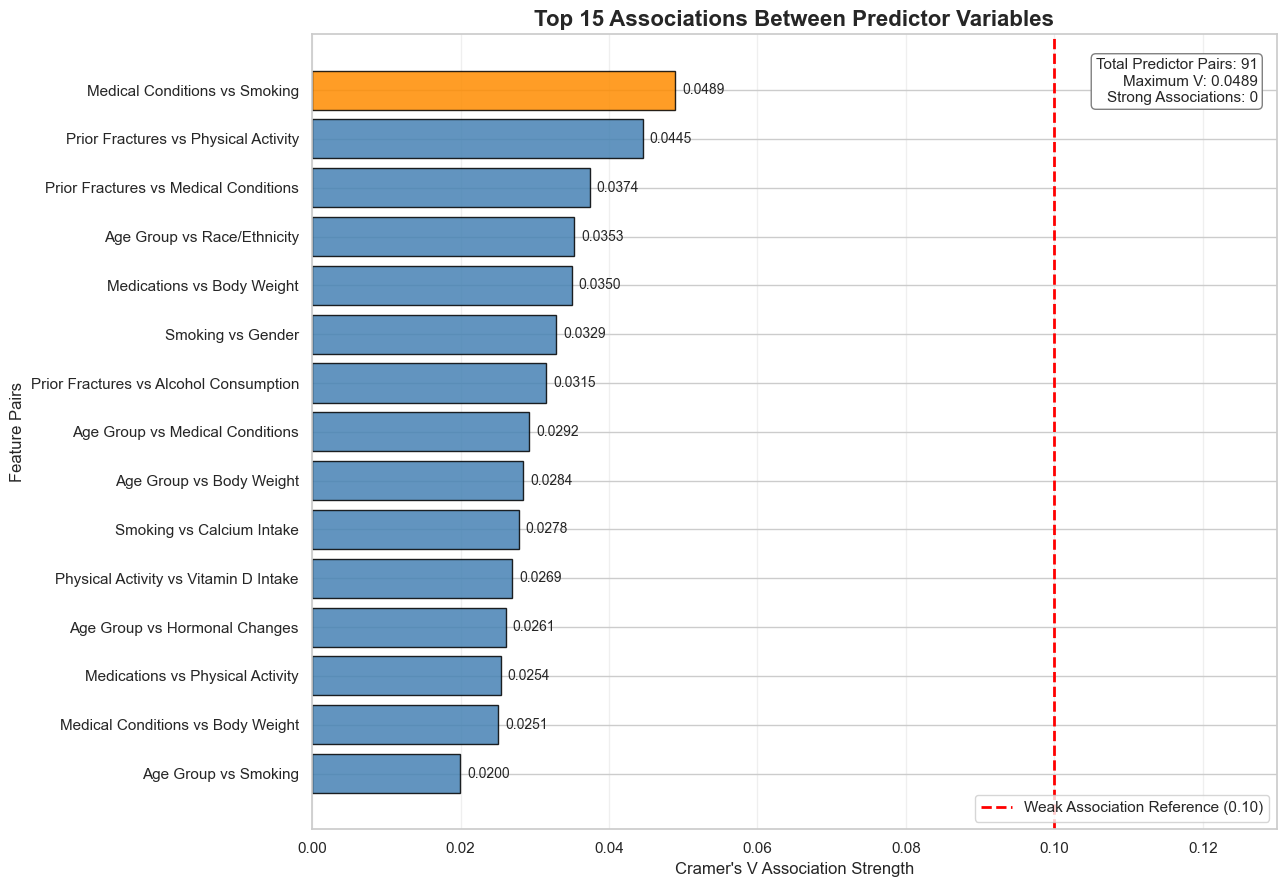

In [98]:
# TOP 15 PREDICTOR ASSOCIATIONS - VISUALIZATION

plot_df = predictor_associations.head(15).copy()

plot_df["Feature Pair"] = (
    plot_df["Feature 1"] +
    " vs " +
    plot_df["Feature 2"]
)

fig, ax = plt.subplots(figsize=(13, 9))

bars = ax.barh(
    plot_df["Feature Pair"],
    plot_df["Cramer's V"],
    color="steelblue",
    edgecolor="black",
    alpha=0.85
)

# Display association values
ax.bar_label(
    bars,
    fmt="%.4f",
    padding=5,
    fontsize=10
)

# Weak association reference
ax.axvline(
    0.10,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Weak Association Reference (0.10)"
)

# Highlight maximum association
bars[0].set_color("darkorange")
bars[0].set_edgecolor("black")

# Summary statistics
summary_text = (
    f"Total Predictor Pairs: "
    f"{len(predictor_associations)}\n"
    f"Maximum V: "
    f"{predictor_associations['Cramer' + chr(39) + 's V'].max():.4f}\n"
    f"Strong Associations: "
    f"{(predictor_associations['Cramer' + chr(39) + 's V'] >= 0.70).sum()}"
)

ax.text(
    0.98,
    0.97,
    summary_text,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=11,
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        edgecolor="gray"
    )
)

ax.invert_yaxis()

ax.set_xlim(
    0,
    max(0.13, plot_df["Cramer's V"].max() * 1.25)
)

ax.set_xlabel("Cramer's V Association Strength")
ax.set_ylabel("Feature Pairs")

ax.set_title(
    "Top 15 Associations Between Predictor Variables",
    fontsize=16,
    fontweight="bold"
)

ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# CONSOLIDATED STATISTICAL ASSOCIATION REPORT

statistical_report = chi_square_df.merge(
    cramers_df,
    on="Feature",
    how="left"
)

statistical_report = statistical_report.merge(
    association_summary[[
        "Feature",
        "Percentage Point Difference"
    ]],
    on="Feature",
    how="left"
)

statistical_report = statistical_report[[
    "Feature",
    "Chi-Square Statistic",
    "P-value",
    "Adjusted P-value",
    "Significant (Adjusted)",
    "Minimum Expected Count",
    "Expected Cells Below 5",
    "Cramer's V",
    "Percentage Point Difference"
]].sort_values(
    "Cramer's V",
    ascending=False
)

display(statistical_report.round(6))

,Feature,Chi-Square Statistic,P-value,Adjusted P-value,Significant (Adjusted),Minimum Expected Count,Expected Cells Below 5,Cramer's V,Percentage Point Difference
0,Body Weight,2.5086,0.1132,0.8828,No,465.5000,0,0.0278,3.5837
1,Medications,2.2248,0.1358,0.8828,No,486.5000,0,0.0250,3.3709
2,Physical Activity,0.7388,0.3900,0.9245,No,468.5000,0,0.0000,1.9443
3,Vitamin D Intake,0.5910,0.4420,0.9245,No,473.5000,0,0.0000,1.7383
4,Smoking,0.5230,0.4696,0.9245,No,488.0000,0,0.0000,1.6343
5,Prior Fractures,0.4597,0.4978,0.9245,No,487.5000,0,0.0000,1.5322
6,Hormonal Changes,0.4597,0.4978,0.9245,No,488.5000,0,0.0000,1.5322
7,Gender,0.2942,0.5875,0.9460,No,483.0000,0,0.0000,1.2260
8,Calcium Intake,0.0327,0.8565,0.9460,No,477.0000,0,0.0000,0.4088
9,Medical Conditions,0.2956,0.8626,0.9460,No,316.5000,0,0.0000,1.4400


In [ ]:
# EXACT AGE-WISE OSTEOPOROSIS ANALYSIS

exact_age_summary = df.groupby("Age")[target].agg(
    Total="size",
    Positive="sum",
    Positive_Rate="mean"
).reset_index()

exact_age_summary["Negative"] = (
    exact_age_summary["Total"] -
    exact_age_summary["Positive"]
)

exact_age_summary["Osteoporosis (%)"] = (
    exact_age_summary["Positive_Rate"] * 100
)

display(exact_age_summary.round(2))

,Age,Total,Positive,Positive_Rate,Negative,Osteoporosis (%)
0,18,152,20,0.1300,132,13.1600
1,19,147,14,0.1000,133,9.5200
2,20,109,12,0.1100,97,11.0100
3,21,117,13,0.1100,104,11.1100
4,22,99,15,0.1500,84,15.1500
5,23,56,13,0.2300,43,23.2100
6,24,10,10,1.0000,0,100.0000
7,25,64,16,0.2500,48,25.0000
8,26,62,14,0.2300,48,22.5800
9,27,9,9,1.0000,0,100.0000


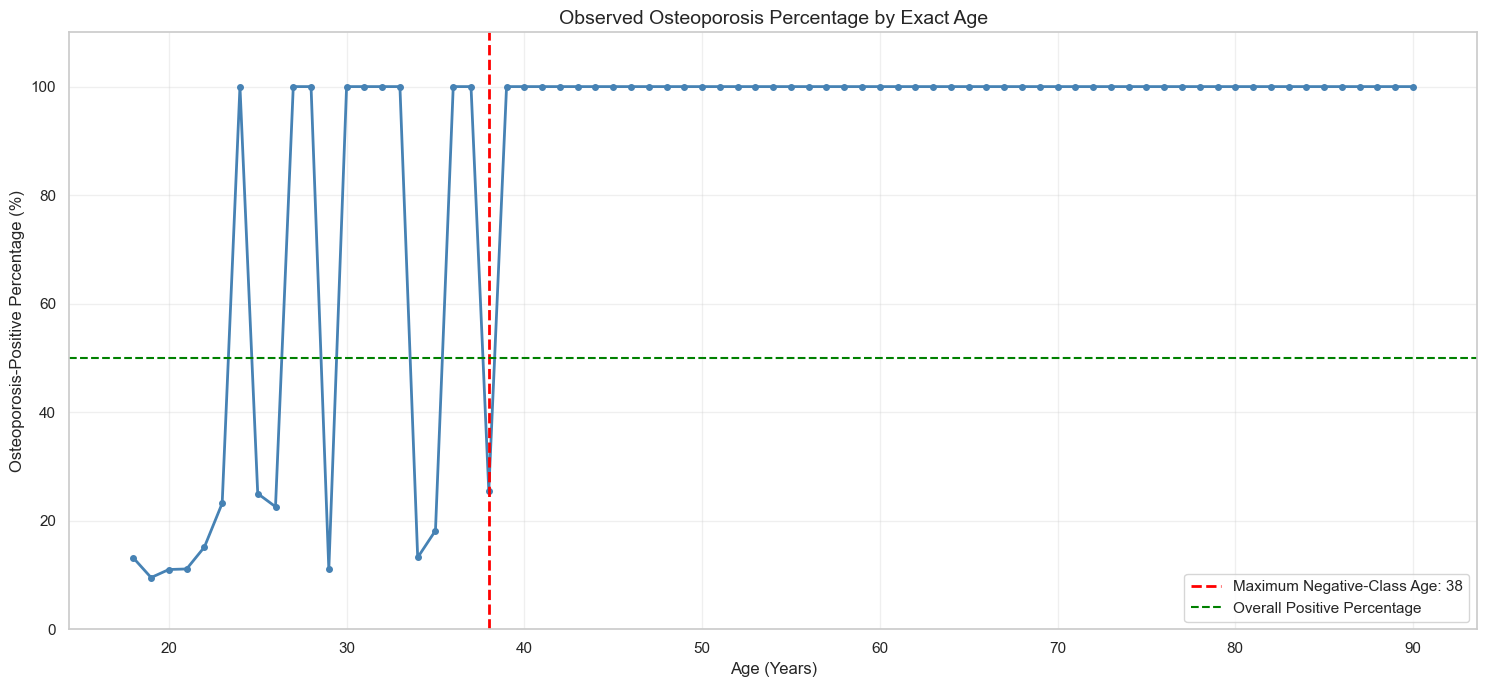

In [ ]:
# EXACT AGE-WISE POSITIVE PERCENTAGE

max_negative_age = df.loc[
    df[target] == 0,
    "Age"
].max()

plt.figure(figsize=(15, 7))

plt.plot(
    exact_age_summary["Age"],
    exact_age_summary["Osteoporosis (%)"],
    marker="o",
    markersize=4,
    color="steelblue",
    linewidth=2
)

plt.axvline(
    max_negative_age,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Maximum Negative-Class Age: {max_negative_age}"
)

plt.axhline(
    df[target].mean() * 100,
    color="green",
    linestyle="--",
    label="Overall Positive Percentage"
)

plt.xlabel("Age (Years)")
plt.ylabel("Osteoporosis-Positive Percentage (%)")

plt.title(
    "Observed Osteoporosis Percentage by Exact Age"
)

plt.ylim(0, 110)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [84]:
# OVERLAPPING AGE RANGE INVESTIGATION

negative_age_min = df.loc[
    df[target] == 0, "Age"
].min()

negative_age_max = df.loc[
    df[target] == 0, "Age"
].max()

positive_age_min = df.loc[
    df[target] == 1, "Age"
].min()

positive_age_max = df.loc[
    df[target] == 1, "Age"
].max()

overlap_min = max(
    negative_age_min,
    positive_age_min
)

overlap_max = min(
    negative_age_max,
    positive_age_max
)

df_overlap = df_eda[
    df_eda["Age"].between(
        overlap_min,
        overlap_max
    )
].copy()

print(f"Overlapping Age Range: {overlap_min}-{overlap_max}")

print(f"Observations in Overlapping Range: {len(df_overlap)}")

display(
    df_overlap[target].value_counts().sort_index()
)

Overlapping Age Range: 18-38
Observations in Overlapping Range: 1256


Osteoporosis
0    979
1    277
Name: count, dtype: int64

In [99]:
display(overlap_association_df.round(4))

,Feature,Full Dataset Association,Overlapping Age Association
11,Medications,0.0250,0.0495
12,Prior Fractures,0.0000,0.0225
4,Body Weight,0.0278,0.0185
8,Smoking,0.0000,0.0180
0,Gender,0.0000,0.0000
3,Race/Ethnicity,0.0000,0.0000
2,Family History,0.0000,0.0000
1,Hormonal Changes,0.0000,0.0000
5,Calcium Intake,0.0000,0.0000
7,Physical Activity,0.0000,0.0000


In [ ]:
# CATEGORICAL ASSOCIATIONS WITHIN OVERLAPPING AGE RANGE

overlap_results = []

for col in categorical_cols:

    overall_association = cramers_v(
        df_eda[col],
        df_eda[target]
    )

    overlap_association = cramers_v(
        df_overlap[col],
        df_overlap[target]
    )

    overlap_results.append({

        "Feature": col,

        "Full Dataset Association": overall_association,

        "Overlapping Age Association": overlap_association

    })

overlap_association_df = pd.DataFrame(
    overlap_results
).sort_values(
    "Overlapping Age Association",
    ascending=False
)

display(overlap_association_df.round(4))

,Feature,Full Dataset Association,Overlapping Age Association
11,Medications,0.0250,0.0495
12,Prior Fractures,0.0000,0.0225
4,Body Weight,0.0278,0.0185
8,Smoking,0.0000,0.0180
0,Gender,0.0000,0.0000
3,Race/Ethnicity,0.0000,0.0000
2,Family History,0.0000,0.0000
1,Hormonal Changes,0.0000,0.0000
5,Calcium Intake,0.0000,0.0000
7,Physical Activity,0.0000,0.0000


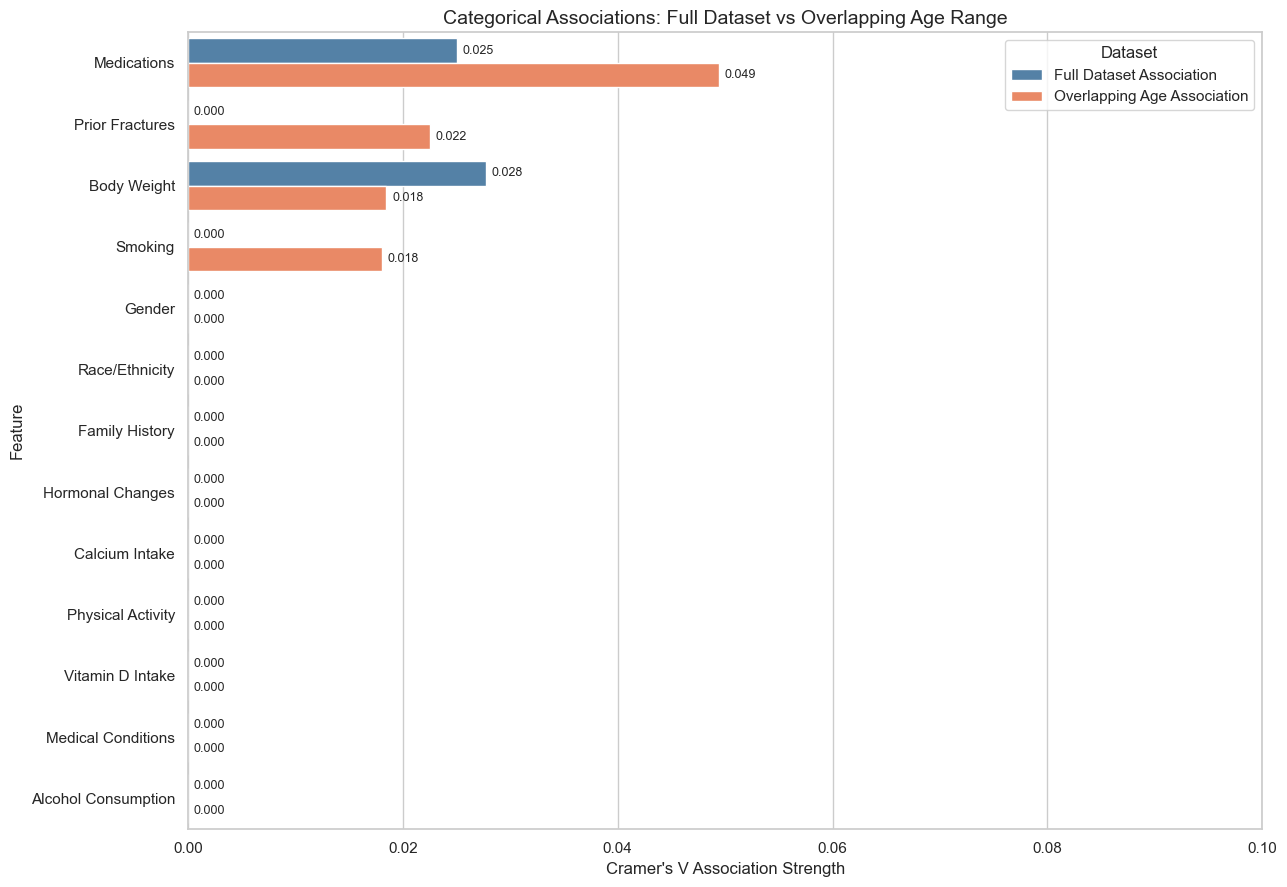

In [ ]:
# FULL DATASET VS OVERLAPPING AGE ASSOCIATIONS

overlap_plot_df = overlap_association_df.melt(
    id_vars="Feature",
    var_name="Dataset",
    value_name="Cramer's V"
)

plt.figure(figsize=(13, 9))

ax = sns.barplot(
    data=overlap_plot_df,
    x="Cramer's V",
    y="Feature",
    hue="Dataset",
    palette=["steelblue", "coral"]
)

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.3f",
        padding=4,
        fontsize=9
    )

plt.xlim(
    0,
    max(
        0.1,
        overlap_plot_df["Cramer's V"].max() * 1.3
    )
)

plt.xlabel("Cramer's V Association Strength")
plt.ylabel("Feature")

plt.title(
    "Categorical Associations: Full Dataset vs Overlapping Age Range"
)

plt.legend(title="Dataset")

plt.tight_layout()
plt.show()

In [101]:
# OVERLAPPING AGE RANGE - ASSOCIATION CHANGE ANALYSIS

overlap_change_df = overlap_association_df.copy()

# Calculate absolute change
overlap_change_df["Association Change"] = (
    overlap_change_df["Overlapping Age Association"] -
    overlap_change_df["Full Dataset Association"]
)

# Calculate percentage change
# Zero baseline values are treated as undefined
overlap_change_df["Percentage Change (%)"] = (
    overlap_change_df["Association Change"] /
    overlap_change_df["Full Dataset Association"].replace(
        0, np.nan
    )
) * 100

# Identify direction of change
overlap_change_df["Change Direction"] = np.select(
    [
        overlap_change_df["Association Change"] > 1e-8,
        overlap_change_df["Association Change"] < -1e-8
    ],
    [
        "Increased",
        "Decreased"
    ],
    default="Unchanged"
)

# Sort by association change
overlap_change_df = overlap_change_df.sort_values(
    "Association Change",
    ascending=False
).reset_index(drop=True)

display(overlap_change_df.round(4))

print("\nASSOCIATION CHANGE SUMMARY")

display(
    overlap_change_df["Change Direction"].value_counts()
)

,Feature,Full Dataset Association,Overlapping Age Association,Association Change,Percentage Change (%),Change Direction
0,Medications,0.0250,0.0495,0.0244,97.7530,Increased
1,Prior Fractures,0.0000,0.0225,0.0225,NaN,Increased
2,Smoking,0.0000,0.0180,0.0180,NaN,Increased
3,Gender,0.0000,0.0000,0.0000,NaN,Unchanged
4,Race/Ethnicity,0.0000,0.0000,0.0000,NaN,Unchanged
5,Physical Activity,0.0000,0.0000,0.0000,NaN,Unchanged
6,Family History,0.0000,0.0000,0.0000,NaN,Unchanged
7,Hormonal Changes,0.0000,0.0000,0.0000,NaN,Unchanged
8,Calcium Intake,0.0000,0.0000,0.0000,NaN,Unchanged
9,Medical Conditions,0.0000,0.0000,0.0000,NaN,Unchanged



ASSOCIATION CHANGE SUMMARY


Change Direction
Unchanged    9
Increased    3
Decreased    1
Name: count, dtype: int64

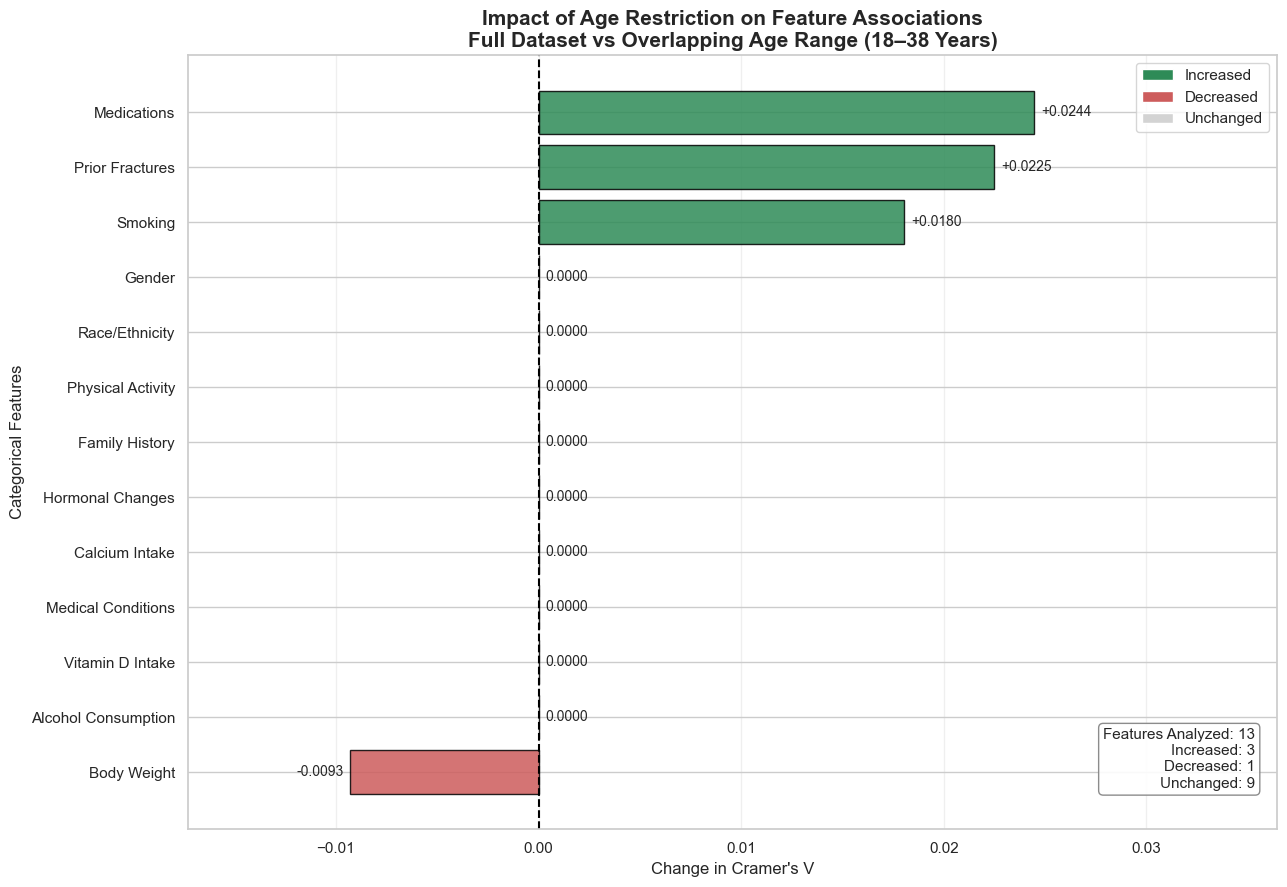

In [102]:
# ASSOCIATION CHANGE - VISUALIZATION

plot_df = overlap_change_df.copy()

colors = plot_df["Change Direction"].map({
    "Increased": "seagreen",
    "Decreased": "indianred",
    "Unchanged": "lightgray"
})

fig, ax = plt.subplots(figsize=(13, 9))

bars = ax.barh(
    plot_df["Feature"],
    plot_df["Association Change"],
    color=colors,
    edgecolor="black",
    alpha=0.85
)

# Add values to bars
ax.bar_label(
    bars,
    labels=[
        f"{v:+.4f}" if abs(v) > 1e-8 else "0.0000"
        for v in plot_df["Association Change"]
    ],
    padding=5,
    fontsize=10
)

# Zero reference line
ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5
)

# Summary statistics
summary_text = (
    f"Features Analyzed: {len(plot_df)}\n"
    f"Increased: "
    f"{(plot_df['Change Direction'] == 'Increased').sum()}\n"
    f"Decreased: "
    f"{(plot_df['Change Direction'] == 'Decreased').sum()}\n"
    f"Unchanged: "
    f"{(plot_df['Change Direction'] == 'Unchanged').sum()}"
)

ax.text(
    0.98,
    0.05,
    summary_text,
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=11,
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        edgecolor="gray",
        alpha=0.9
    )
)

# Legend
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor="seagreen", label="Increased"),
    Patch(facecolor="indianred", label="Decreased"),
    Patch(facecolor="lightgray", label="Unchanged")
]

ax.legend(
    handles=legend_elements,
    loc="upper right"
)

ax.invert_yaxis()

ax.set_xlim(
    plot_df["Association Change"].min() - 0.008,
    plot_df["Association Change"].max() + 0.012
)

ax.set_xlabel("Change in Cramer's V")
ax.set_ylabel("Categorical Features")

ax.set_title(
    "Impact of Age Restriction on Feature Associations\n"
    "Full Dataset vs Overlapping Age Range (18–38 Years)",
    fontsize=15,
    fontweight="bold"
)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [103]:
display(statistical_report.round(4))

,Feature,Chi-Square Statistic,P-value,Adjusted P-value,Significant (Adjusted),Minimum Expected Count,Expected Cells Below 5,Cramer's V,Percentage Point Difference
0,Body Weight,2.5086,0.1132,0.8828,No,465.5000,0,0.0278,3.5837
1,Medications,2.2248,0.1358,0.8828,No,486.5000,0,0.0250,3.3709
2,Physical Activity,0.7388,0.3900,0.9245,No,468.5000,0,0.0000,1.9443
3,Vitamin D Intake,0.5910,0.4420,0.9245,No,473.5000,0,0.0000,1.7383
4,Smoking,0.5230,0.4696,0.9245,No,488.0000,0,0.0000,1.6343
5,Prior Fractures,0.4597,0.4978,0.9245,No,487.5000,0,0.0000,1.5322
6,Hormonal Changes,0.4597,0.4978,0.9245,No,488.5000,0,0.0000,1.5322
7,Gender,0.2942,0.5875,0.9460,No,483.0000,0,0.0000,1.2260
8,Calcium Intake,0.0327,0.8565,0.9460,No,477.0000,0,0.0000,0.4088
9,Medical Conditions,0.2956,0.8626,0.9460,No,316.5000,0,0.0000,1.4400


In [104]:
# EXPORT STATISTICAL ANALYSIS RESULTS

import os

os.makedirs("statistical_results", exist_ok=True)

statistical_report.to_csv(
    "statistical_results/statistical_association_report.csv",
    index=False
)

chi_square_df.to_csv(
    "statistical_results/chi_square_results.csv",
    index=False
)

cramers_df.to_csv(
    "statistical_results/cramers_v_results.csv",
    index=False
)

cramers_matrix.to_csv(
    "statistical_results/cramers_v_matrix.csv"
)

overlap_association_df.to_csv(
    "statistical_results/overlapping_age_analysis.csv",
    index=False
)

print("Statistical analysis reports saved successfully.")

print("\nSaved files:")

for file in os.listdir("statistical_results"):
    print(file)

Statistical analysis reports saved successfully.

Saved files:
chi_square_results.csv
cramers_v_matrix.csv
cramers_v_results.csv
overlapping_age_analysis.csv
statistical_association_report.csv


In [87]:
# FINAL DATASET VERIFICATION AFTER EDA

print("Original Dataset Shape:", df_original.shape)

print("Cleaned Dataset Shape:", df.shape)

print("EDA Dataset Shape:", df_eda.shape)

print("\nOriginal Modeling Features:")
print(feature_cols)

print("\nEDA-Only Columns:")

eda_only_cols = [
    col for col in df_eda.columns
    if col not in df.columns
]

print(eda_only_cols)

assert target not in feature_cols

assert id_col not in feature_cols

assert "Osteoporosis Status" not in feature_cols

assert "Age Group" not in feature_cols

print("\nFeature verification completed successfully.")

Original Dataset Shape: (1958, 16)
Cleaned Dataset Shape: (1958, 16)
EDA Dataset Shape: (1958, 18)

Original Modeling Features:
['Age', 'Gender', 'Hormonal Changes', 'Family History', 'Race/Ethnicity', 'Body Weight', 'Calcium Intake', 'Vitamin D Intake', 'Physical Activity', 'Smoking', 'Alcohol Consumption', 'Medical Conditions', 'Medications', 'Prior Fractures']

EDA-Only Columns:
['Osteoporosis Status', 'Age Group']

Feature verification completed successfully.


In [ ]:
# SAVE CLEANED DATASET

df.to_csv(
    "osteoporosis_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.
